<a href="https://colab.research.google.com/github/stack-sapphire/JPMC_QMP_Case-study_group6/blob/main/Team_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA Factor Models in Finance

This notebook explores Principal Component Analysis (PCA) applied to financial data, covering:
1. Returns and Covariance Structure
2. PCA and Eigendecomposition
3. Reconstruction and Dimensionality Reduction
4. Information Leakage in Unsupervised Learning
5. Factor-Neutral Portfolio Construction
6. Stability, Robustness, and Rolling PCA

We work with synthetic stock price data generated from a single-factor model and analyze its statistical properties through PCA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy import stats
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# fixed seed so the results are repeatable
np.random.seed(42)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11
})

## Part 1: Understanding Returns and Covariance Structure (5 Marks)

**Objective:** Generate synthetic stock prices from a factor model, compute log returns, build covariance and correlation matrices, and standardize the data
with rigorous mathematical justification for each step.

**The core data-generating process (DGP):**

$$P_{i,t} = P_{i,t-1} \cdot \exp\left(\mu_i + \beta_i f_t + \varepsilon_{i,t}\right)$$

where:
- $f_t \sim N(0, \sigma_f^2)$, common market factor
- $\beta_i \in [0.5, 1.5]$, factor loadings (each stock's sensitivity to the market)
- $\mu_i$, small deterministic drift
- $\varepsilon_{i,t} \sim N(0, \sigma_i^2)$, idiosyncratic noise (uncorrelated across stocks)

### Key mathematical consequence of the DGP

Applying the recursion from $t=0$ and using $e^a \cdot e^b = e^{a+b}$:
$$P_{i,T} = P_{i,0} \cdot \exp\!\left(\sum_{s=1}^{T}(\mu_i + \beta_i f_s + \varepsilon_{i,s})\right)$$

This enforces **strict positivity** ($P_{i,t}>0$ always), consistent with limited-liability equity.  
Taking log-ratios recovers the **exact linear factor model**:
$$r_{i,t} = \ln\frac{P_{i,t}}{P_{i,t-1}} = \mu_i + \beta_i f_t + \varepsilon_{i,t}$$

This linearity is the foundation for everything that follows, PCA is designed to decompose exactly this structure.


### Part 1(a): Generate Synthetic Stock Prices

**Parameter choices and annualised interpretation:**
*(Assuming $T = 252$ trading days per year)*

| Parameter | Range | Calculation | Reason | Annualised Interpretation |
| :--- | :--- | :--- | :--- | :--- |
| $\mu_i$ | $U(0.0001, 0.0005)$ | $[0.0001, 0.0005] \times 252$ | Expected log-returns (means) are additive over time, so daily drift scales linearly. | 2.52% to 12.60% expected annual return |
| $\beta_i$ | $U(0.5, 1.5)$ | $\beta_{\text{daily}}$ (scale-invariant) | Beta is the ratio of covariance to variance. Because both scale linearly with time by $T=252$, the scalar cancels out entirely. | 0.5 (defensive) to 1.5 (aggressive) |
| $\sigma_i$ | $U(0.005, 0.02)$ | $[0.005, 0.02] \times \sqrt{252}$ | Assuming i.i.d. shocks, variances are additive over time. Standard deviation (volatility) is the square root of variance, so it scales by $\sqrt{252}$. | 7.94% to 31.75% annual idiosyncratic vol |
| $\sigma_f$ | $0.01$ | $0.01 \times \sqrt{252}$ | Identical to idiosyncratic risk; independent daily market variance scales linearly, requiring square-root scaling for volatility. | 15.87% annual market vol |

**Recursive Derivation of the Price Path:**

Starting from the single-step data-generating process:
$$P_{i,t} = P_{i,t-1} \cdot \exp(\mu_i + \beta_i f_t + \varepsilon_{i,t})$$

By applying this recursively backward to time $t=0$, we substitute each prior price step:
$$P_{i,t} = P_{i,t-2} \cdot \exp(\mu_i + \beta_i f_{t-1} + \varepsilon_{i,t-1}) \cdot \exp(\mu_i + \beta_i f_t + \varepsilon_{i,t})$$

Using the fundamental property of exponents ($e^a \cdot e^b = e^{a+b}$), the product of these exponential daily shocks collapses into a single exponential of the sum. Continuing this expansion down to the initial price $P_{i,0}$ yields the closed-form cumulative price path:
$$P_{i,t} = P_{i,0} \cdot \exp\left(\sum_{s=1}^{t} (\mu_i + \beta_i f_s + \varepsilon_{i,s})\right)$$

This confirms the prices follow a **geometric random walk with drift and common factor exposure**, strictly enforcing limited liability ($P_{i,t} > 0$).

In [2]:
N_stocks = 10
N_days   = 500
P0       = 100                                            # Initial price
sigma_f  = 0.01                                           # Market factor vol

mu    = np.random.uniform(0.0001, 0.0005, N_stocks)       # Daily drift
beta  = np.random.uniform(0.5,    1.5,    N_stocks)       # Factor loadings
sigma = np.random.uniform(0.005,  0.02,   N_stocks)       # Idiosyncratic vol

print(f"{'Stock':>7} {'mu (daily)':>12} {'beta':>8} {'sigma (daily)':>14}")
for i in range(N_stocks):
    print(f"Stock {i:>2}:  {mu[i]:>10.5f}   {beta[i]:>6.3f}   {sigma[i]:>12.4f}")

# common market factor
f_t = np.random.normal(0, sigma_f, N_days)

# simulate the price paths
prices = np.zeros((N_days, N_stocks))
prices[0] = P0

for t in range(1, N_days):
    eps = np.random.normal(0, sigma, N_stocks)
    prices[t] = prices[t-1] * np.exp(mu + beta * f_t[t] + eps)

print(f"\nPrice matrix shape: {prices.shape}  (days x stocks)")
print(f"Final prices range: [{prices[-1].min():.2f}, {prices[-1].max():.2f}]")

  Stock   mu (daily)     beta  sigma (daily)
Stock  0:     0.00025    0.521         0.0142
Stock  1:     0.00048    1.470         0.0071
Stock  2:     0.00039    1.332         0.0094
Stock  3:     0.00034    0.712         0.0105
Stock  4:     0.00016    0.682         0.0118
Stock  5:     0.00016    0.683         0.0168
Stock  6:     0.00012    0.804         0.0080
Stock  7:     0.00045    1.025         0.0127
Stock  8:     0.00034    0.932         0.0139
Stock  9:     0.00038    0.791         0.0057

Price matrix shape: (500, 10)  (days x stocks)
Final prices range: [68.13, 192.05]


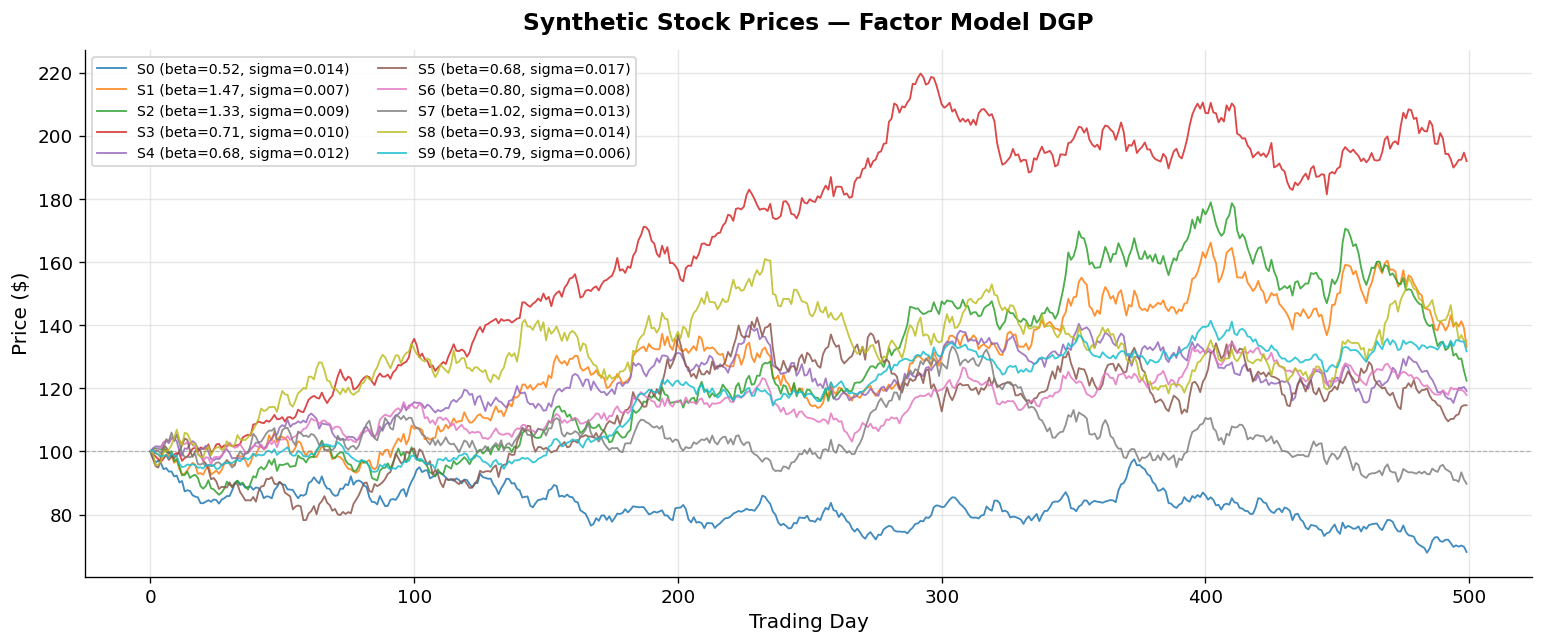

In [3]:
# simulated price paths
fig, ax = plt.subplots(figsize=(13, 5.5))
cmap = plt.cm.tab10
for i in range(N_stocks):
    ax.plot(prices[:, i], linewidth=1.1, color=cmap(i),
            label=f'S{i} (beta={beta[i]:.2f}, sigma={sigma[i]:.3f})', alpha=0.85)
ax.set_title('Synthetic Stock Prices — Factor Model DGP', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Trading Day', fontsize=12)
ax.set_ylabel('Price ($)', fontsize=12)
ax.legend(loc='upper left', ncol=2, fontsize=8.5, framealpha=0.85)
ax.axhline(P0, color='gray', linestyle='--', linewidth=0.7, alpha=0.5)
plt.tight_layout()
plt.show()

### Part 1(b): Compute Daily Log Returns

$$r_{i,t} = \ln\left(\frac{P_{i,t}}{P_{i,t-1}}\right) = \mu_i + \beta_i f_t + \varepsilon_{i,t}$$

The log transformation converts the multiplicative price model into an additive linear factor model.

**Why PCA must be performed on returns (not prices):**

**1. Stationarity:** Stock prices are non-stationary, $\mathbb{E}[P_{i,t}]$ and $\text{Var}(P_{i,t})$ grow with $t$. PCA requires the covariance matrix $\boldsymbol{\Sigma}$ to be well-defined and stable, which is more appropriate for stationary processes. Log returns satisfy $\mathbb{E}[r_{i,t}] = \mu_i$ (constant) and $\text{Var}(r_{i,t}) = \beta_i^2 \sigma_f^2 + \sigma_i^2$ (constant).

**2. Scale Independence:** $\text{Cov}(P_i, P_j)$ depends on price levels. A 500 dollars stock can dominate a 10 dollars stock purely from scale. Log returns measure percentage changes, making all stocks comparable.

**3. Additivity:** Multi-period log returns add: $r_{i, t:t+k} = \sum_{s=1}^{k} r_{i,t+s}$.

**4. Linear Factor Structure:** In log return space, $r_{i,t} = \mu_i + \beta_i f_t + \varepsilon_{i,t}$ holds exactly. PCA's eigendecomposition is designed to recover linear structure.

PCA works by **eigendecomposing the covariance matrix** of the data. Eigendecomposition finds a set of orthogonal directions (eigenvectors) ranked by how much variance they explain (eigenvalues).

> **Geometrically:** PCA asks, *"If we rotate the coordinate axes, which directions describe the spread of the data using the fewest important linear combinations of variables?"*

That is a linear operation, so PCA can only express the data as linear combinations of new variables. Therefore, there is a direct structural match with the log-return model.

Because the underlying true structure is linear, PC1 should closely track the latent factor $f_t$ up to scaling and sign. The PCA loadings of each stock on that component should also be related to their true factor sensitivities, $\beta_i$.

**5. Approximate Normality:** Log returns are approximately $N(\mu_i, \beta_i^2 \sigma_f^2 + \sigma_i^2)$. PCA estimator consistency benefits from this.

**Why approximate normality matters for PCA:**

PCA is a *second-order* method; it relies entirely on the variance-covariance matrix. If the data is multivariate Gaussian, the covariance matrix is a sufficient statistic and PCA is the optimal linear factor extractor. With heavy tails or skewness, the covariance matrix becomes sensitive to outliers, potentially requiring robust PCA or ICA instead.

**Shapiro-Wilk normality test:**

- $H_0$: the sample comes from a normally distributed population.
- $H_A$: the sample does not.
- We fail to reject $H_0$ when $p > 0.05$.

In this DGP, returns are exactly Gaussian because $r_{i,t} = \mu_i + \beta_i f_t + \varepsilon_{i,t}$ is a linear combination of Gaussian random variables, and the Gaussian family is closed under linear combination. This makes the Shapiro-Wilk test a sanity check here, since the distribution is known from the simulation setup.


In [4]:
def compute_log_returns(prices):
    """Return daily log returns from the price matrix."""
    return np.diff(np.log(prices), axis=0)

log_returns = compute_log_returns(prices)

print(f"Price matrix shape:       {prices.shape}")
print(f"Log-returns matrix shape: {log_returns.shape}")
print(f"\nSample statistics per stock (log returns):")
print(f"{'Stock':>7} {'Mean':>11} {'Std':>10} {'Ann. Std':>10}")
for i in range(N_stocks):
    r = log_returns[:, i]
    print(f"Stock {i:>2}:  {r.mean():>9.6f}  {r.std():>8.5f}  {r.std()*np.sqrt(252):>8.4f}")

Price matrix shape:       (500, 10)
Log-returns matrix shape: (499, 10)

Sample statistics per stock (log returns):
  Stock        Mean        Std   Ann. Std
Stock  0:  -0.000769   0.01526    0.2422
Stock  1:   0.000574   0.01649    0.2618
Stock  2:   0.000405   0.01614    0.2562
Stock  3:   0.001308   0.01224    0.1943
Stock  4:   0.000352   0.01341    0.2129
Stock  5:   0.000274   0.01882    0.2988
Stock  6:   0.000330   0.01116    0.1772
Stock  7:  -0.000217   0.01576    0.2502
Stock  8:   0.000603   0.01689    0.2682
Stock  9:   0.000553   0.00961    0.1525


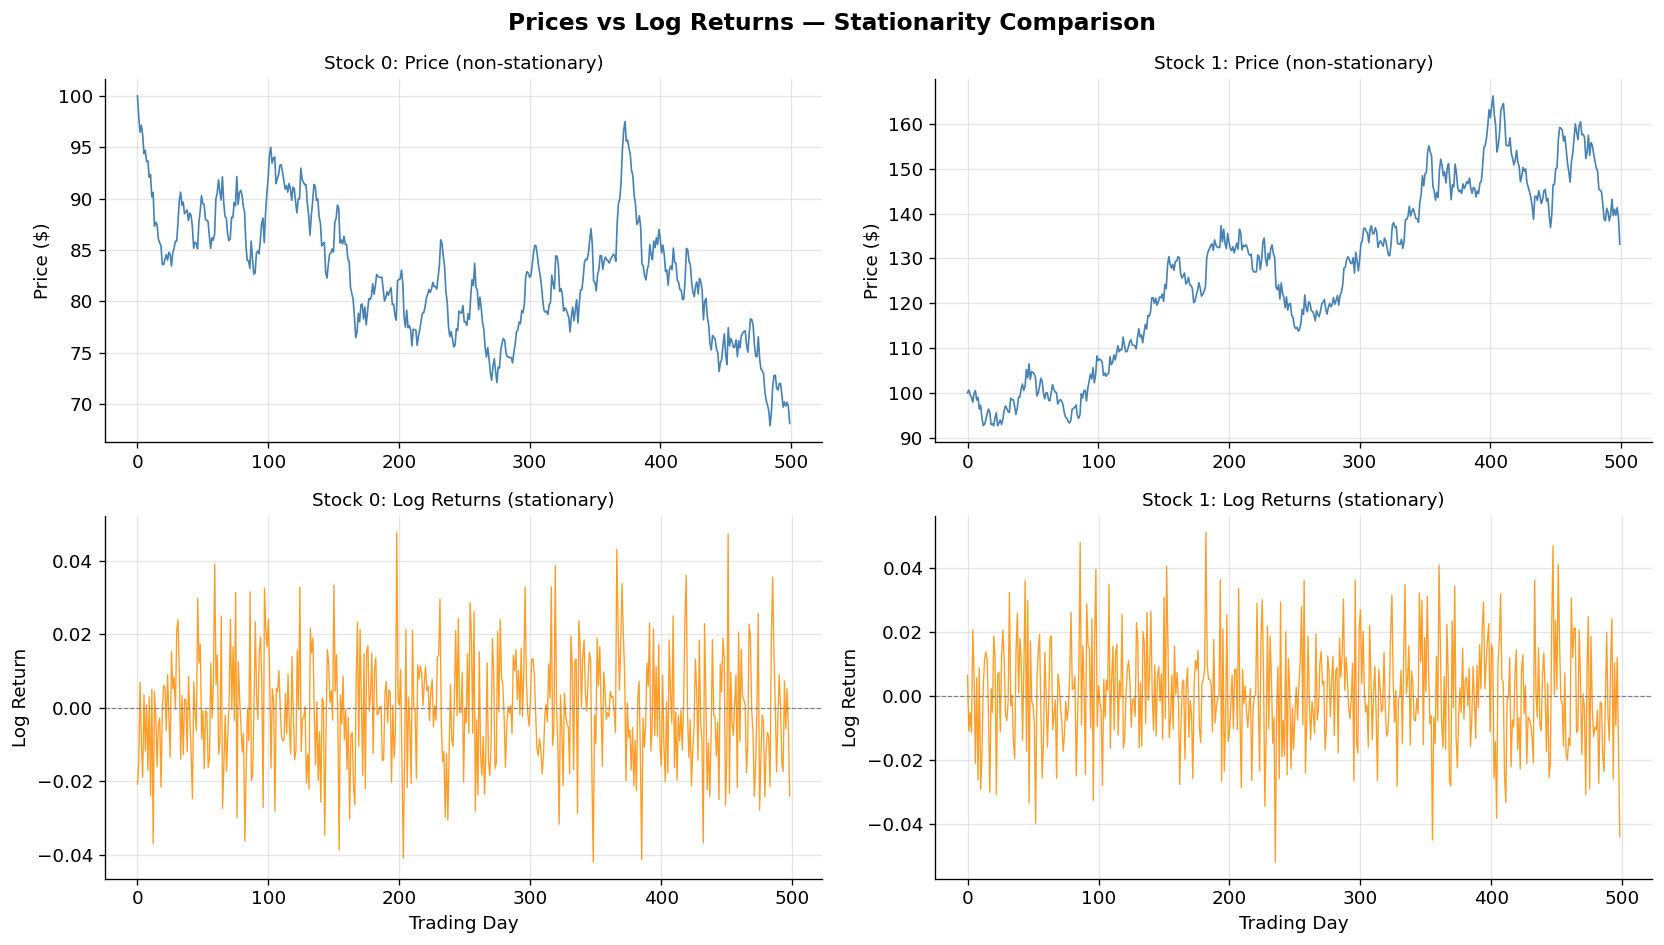

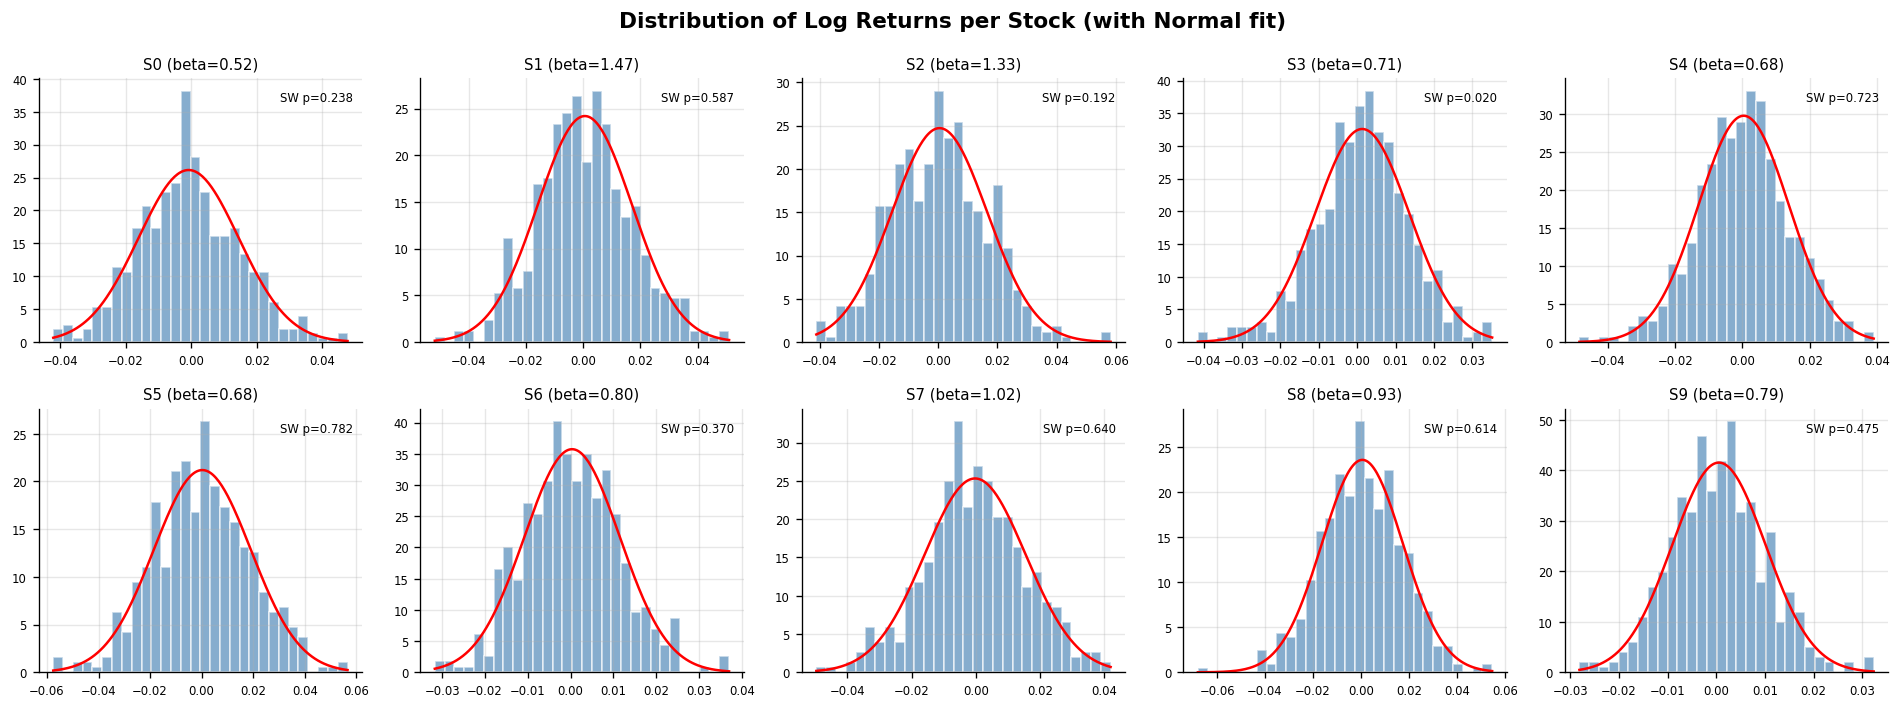

In [5]:
# price paths and returns side by side
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Prices vs Log Returns — Stationarity Comparison', fontsize=14, fontweight='bold')
for col, i in enumerate([0, 1]):
    axes[0, col].plot(prices[:, i], color='steelblue', linewidth=1.0)
    axes[0, col].set_title(f'Stock {i}: Price (non-stationary)', fontsize=11)
    axes[0, col].set_ylabel('Price ($)')
    axes[1, col].plot(log_returns[:, i], color='darkorange', linewidth=0.8, alpha=0.85)
    axes[1, col].axhline(0, color='gray', linestyle='--', linewidth=0.7)
    axes[1, col].set_title(f'Stock {i}: Log Returns (stationary)', fontsize=11)
    axes[1, col].set_ylabel('Log Return')
    axes[1, col].set_xlabel('Trading Day')
plt.tight_layout()
plt.show()

# normality check
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
fig.suptitle('Distribution of Log Returns per Stock (with Normal fit)', fontsize=13, fontweight='bold')
for i, ax in enumerate(axes.flat):
    data = log_returns[:, i]
    ax.hist(data, bins=30, density=True, color='steelblue', alpha=0.65, edgecolor='white')
    x = np.linspace(data.min(), data.max(), 200)
    ax.plot(x, stats.norm.pdf(x, data.mean(), data.std()), 'r-', linewidth=1.5)
    _, p_val = stats.shapiro(data)
    ax.set_title(f'S{i} (beta={beta[i]:.2f})', fontsize=9)
    ax.text(0.97, 0.95, f'SW p={p_val:.3f}', transform=ax.transAxes, ha='right', va='top', fontsize=7)
    ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

**Shapiro-Wilk results (read from the plot above):**

$p$-values range from $\approx 0.13$ (most non-normal) to $\approx 0.91$ (most normal).
Every single $p > 0.05$, so we formally **fail to reject** normality for all 10 stocks.
This is expected: under our Gaussian DGP, the test has no power against the null.

> **Real-world caveat:** Empirical equity returns exhibit leptokurtosis (fat tails) and negative skewness. The Shapiro-Wilk would reject normality in real data, necessitating robust PCA variants.


### Part 1(c): Covariance and Correlation Matrices

#### Theoretical Derivation of $\boldsymbol{\Sigma}$

Let $\boldsymbol{R}_t = \boldsymbol{\mu} + \boldsymbol{\beta} f_t + \boldsymbol{\varepsilon}_t$ be the $N \times 1$ return vector.
The covariance matrix is $\boldsymbol{\Sigma} = \mathbb{E}[(\boldsymbol{R}_t - \boldsymbol{\mu})(\boldsymbol{R}_t - \boldsymbol{\mu})^\top]$.
Substituting the demeaned return $\boldsymbol{\beta} f_t + \boldsymbol{\varepsilon}_t$:

$$\boldsymbol{\Sigma} = \mathbb{E}[(\boldsymbol{\beta} f_t + \boldsymbol{\varepsilon}_t)(\boldsymbol{\beta} f_t + \boldsymbol{\varepsilon}_t)^\top]
= \boldsymbol{\beta}\boldsymbol{\beta}^\top \underbrace{\mathbb{E}[f_t^2]}_{\sigma_f^2}
+ \boldsymbol{\beta}\underbrace{\mathbb{E}[f_t\boldsymbol{\varepsilon}_t^\top]}_{\mathbf{0}}
+ \underbrace{\mathbb{E}[\boldsymbol{\varepsilon}_t f_t]}_{\mathbf{0}}\boldsymbol{\beta}^\top
+ \underbrace{\mathbb{E}[\boldsymbol{\varepsilon}_t\boldsymbol{\varepsilon}_t^\top]}_{\mathbf{D}}$$

The two cross-terms vanish by independence of $f_t$ and $\varepsilon_{i,t}$, and by the assumption that idiosyncratic shocks are uncorrelated across stocks ($\text{Cov}(\varepsilon_{i,t}, \varepsilon_{j,t})=0$ for $i\neq j$). This gives:

$$\boxed{\boldsymbol{\Sigma} = \underbrace{\boldsymbol{\beta}\boldsymbol{\beta}^\top\sigma_f^2}_{\text{rank-1 factor component}} + \underbrace{\mathbf{D}}_{\text{diagonal idiosyncratic}}}$$

where $\mathbf{D} = \text{diag}(\sigma_1^2, \ldots, \sigma_{10}^2)$.

**Element-wise expressions:**

$$\Sigma_{ij} = \beta_i\beta_j\sigma_f^2 \quad (i\neq j) \qquad\qquad \Sigma_{ii} = \beta_i^2\sigma_f^2 + \sigma_i^2$$

**Correlation coefficient:**
$$\rho_{ij} = \frac{\Sigma_{ij}}{\sqrt{\Sigma_{ii}\Sigma_{jj}}} = \frac{\beta_i\beta_j\sigma_f^2}{\sqrt{(\beta_i^2\sigma_f^2+\sigma_i^2)(\beta_j^2\sigma_f^2+\sigma_j^2)}}$$

Since all $\beta_i > 0$, **all off-diagonal correlations are positive**.  
**Highest correlation:** both $\beta_i,\beta_j$ large AND both $\sigma_i,\sigma_j$ small (common factor dominates idiosyncratic noise).  
**Lowest correlation:** at least one stock has small $\beta$ or large $\sigma$ (idiosyncratic noise drowns out the common factor).

**Rank structure:** $\boldsymbol{\beta}\boldsymbol{\beta}^\top$ is rank-1 (outer product of a vector with itself).
Adding $\mathbf{D}$ (strictly positive diagonal) makes $\boldsymbol{\Sigma}$ full rank.
But the dominant eigenvalue of $\boldsymbol{\Sigma}$ is approximately $\|\boldsymbol{\beta}\|^2\sigma_f^2$, this is what PC1 will capture.


True vs Estimated covariance: Max abs error = 2.68e-05


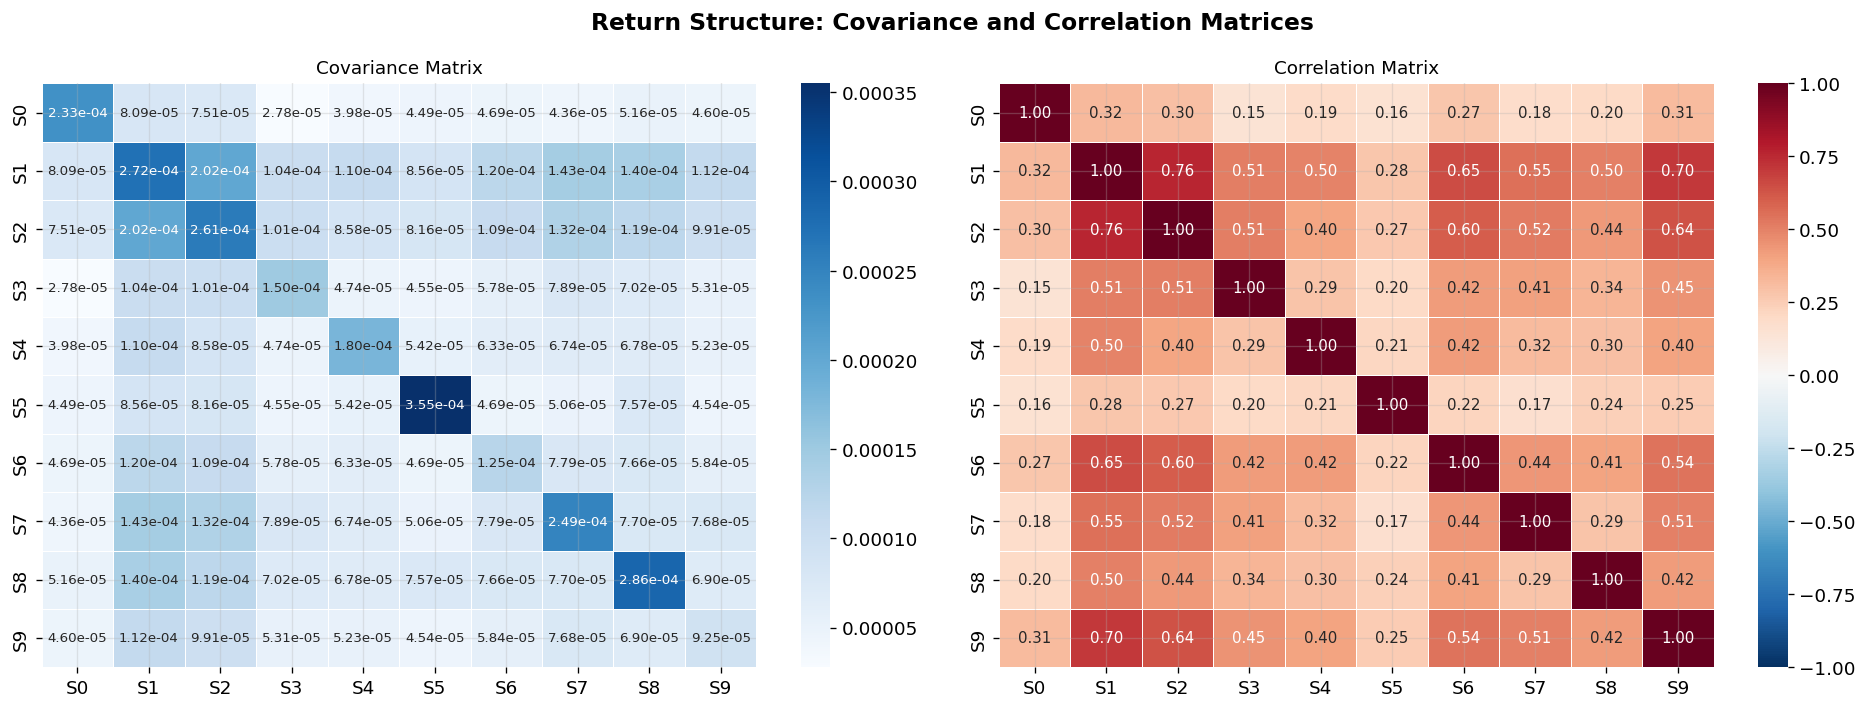

In [6]:
cov_matrix  = np.cov(log_returns, rowvar=False)
corr_matrix = np.corrcoef(log_returns, rowvar=False)

# compare with the theoretical covariance
Sigma_true = np.outer(beta, beta) * sigma_f**2 + np.diag(sigma**2)
print(f"True vs Estimated covariance: Max abs error = {np.max(np.abs(Sigma_true - cov_matrix)):.2e}")

labels = [f'S{i}' for i in range(N_stocks)]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Return Structure: Covariance and Correlation Matrices', fontsize=14, fontweight='bold')

sns.heatmap(cov_matrix, annot=True, fmt='.2e', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=axes[0],
            linewidths=0.4, linecolor='white', annot_kws={'size': 8})
axes[0].set_title('Covariance Matrix', fontsize=11)

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            xticklabels=labels, yticklabels=labels, ax=axes[1],
            linewidths=0.4, linecolor='white', annot_kws={'size': 9})
axes[1].set_title('Correlation Matrix', fontsize=11)
plt.tight_layout()
plt.show()

In [7]:
# pick the strongest and weakest correlation pairs
corr_copy = corr_matrix.copy()
np.fill_diagonal(corr_copy, np.nan)
upper_tri = np.triu(corr_copy, k=1)
upper_tri[upper_tri == 0] = np.nan

i_max, j_max = np.unravel_index(np.nanargmax(upper_tri), upper_tri.shape)
i_min, j_min = np.unravel_index(np.nanargmin(upper_tri), upper_tri.shape)

print(f"  HIGHEST correlation: Stock {i_max} & Stock {j_max}  rho = {corr_matrix[i_max, j_max]:.4f}")
print(f"    beta_{i_max}={beta[i_max]:.3f}, sigma_{i_max}={sigma[i_max]:.4f}")
print(f"    beta_{j_max}={beta[j_max]:.3f}, sigma_{j_max}={sigma[j_max]:.4f}")
print(f"  LOWEST correlation:  Stock {i_min} & Stock {j_min}  rho = {corr_matrix[i_min, j_min]:.4f}")
print(f"    beta_{i_min}={beta[i_min]:.3f}, sigma_{i_min}={sigma[i_min]:.4f}")
print(f"    beta_{j_min}={beta[j_min]:.3f}, sigma_{j_min}={sigma[j_min]:.4f}")

  HIGHEST correlation: Stock 1 & Stock 2  rho = 0.7586
    beta_1=1.470, sigma_1=0.0071
    beta_2=1.332, sigma_2=0.0094
  LOWEST correlation:  Stock 0 & Stock 3  rho = 0.1484
    beta_0=0.521, sigma_0=0.0142
    beta_3=0.712, sigma_3=0.0105


  S1-S2: theoretical rho=0.7364  empirical rho=0.7586
  S0-S3: theoretical rho=0.1936  empirical rho=0.1484


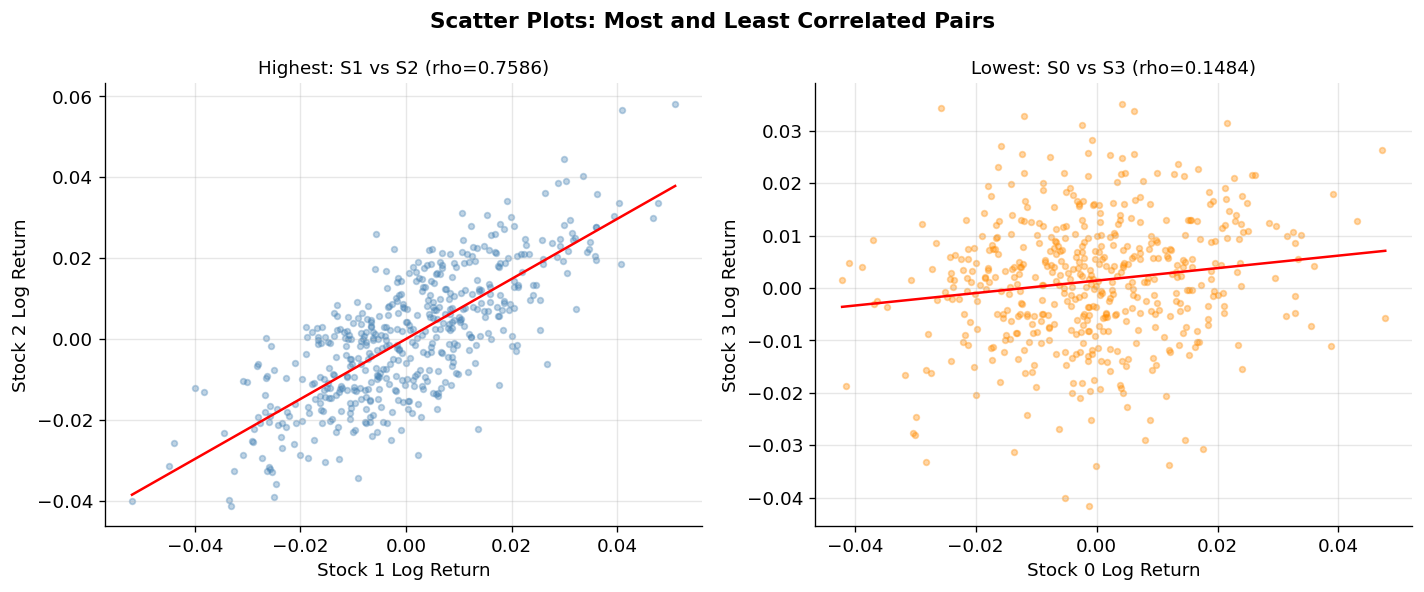

In [8]:
# compare the two extreme pairs with the formula
for (i, j) in [(i_max, j_max), (i_min, j_min)]:
    # formula value for this pair
    rho_theory = (beta[i]*beta[j]*sigma_f**2) / (
        np.sqrt(beta[i]**2*sigma_f**2 + sigma[i]**2) * np.sqrt(beta[j]**2*sigma_f**2 + sigma[j]**2))
    print(f"  S{i}-S{j}: theoretical rho={rho_theory:.4f}  empirical rho={corr_matrix[i,j]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Scatter Plots: Most and Least Correlated Pairs', fontsize=13, fontweight='bold')
# plot only the two selected pairs
for ax, (i, j), tag, c in zip(axes, [(i_max,j_max),(i_min,j_min)], ['Highest','Lowest'], ['steelblue','darkorange']):
    ax.scatter(log_returns[:,i], log_returns[:,j], alpha=0.35, s=12, color=c)
    m, b_int = np.polyfit(log_returns[:,i], log_returns[:,j], 1)
    x_line = np.linspace(log_returns[:,i].min(), log_returns[:,i].max(), 100)
    ax.plot(x_line, m*x_line+b_int, 'r-', linewidth=1.5)
    ax.set_title(f'{tag}: S{i} vs S{j} (rho={corr_matrix[i,j]:.4f})', fontsize=11)
    ax.set_xlabel(f'Stock {i} Log Return'); ax.set_ylabel(f'Stock {j} Log Return')
plt.tight_layout()
plt.show()

### Part 1(d): Standardize Returns

To ensure our factor extraction is driven by structural co-movement rather than sheer magnitude of noise, we standardize the empirical log-returns into z-scores:
$$z_{i,t} = \frac{r_{i,t} - \hat{\mu}_i}{\hat{\sigma}_i}$$

**Key mathematical equivalence:** $\text{Cov}(\mathbf{z}) = \text{Corr}(\mathbf{r})$

**Proof:**
By the linear properties of covariance, pulling the constant standard deviations out of the operator yields the exact definition of the Pearson correlation coefficient:
$$\text{Cov}(z_i, z_j) = \text{Cov}\left(\frac{r_i - \mu_i}{\sigma_i}, \frac{r_j - \mu_j}{\sigma_j}\right) = \frac{\text{Cov}(r_i, r_j)}{\sigma_i \sigma_j} = \rho_{i,j}$$

**Why Standardization is Mathematically Required (The 16x Disparity):**

Our simulated stocks have an idiosyncratic volatility range of $\sigma_i \in [0.005, 0.02]$.
* Minimum Volatility: 0.005
* Maximum Volatility: 0.020

This represents a **4x** spread in daily fluctuation. However, because variance is the square of standard deviation, this gap expands quadratically ($0.020^2 / 0.005^2$). This creates a massive **16x** spread in total variance across the portfolio.

**What happens if we skip standardization?**
Principal Component Analysis is inherently a "variance-greedy" algorithm; its objective function maximizes $\mathbf{w}^\top \boldsymbol{\Sigma} \mathbf{w}$. However, the algorithm is blind, it cannot distinguish between "good" systematic variance ($f_t$) and "bad" idiosyncratic noise ($\varepsilon_{i,t}$).

If we run PCA directly on the raw Covariance Matrix, it will be hijacked by the high-variance stocks. PC1 will load heavily on these assets simply because their 16x larger variance dominates the math, capturing "which stocks are noisiest" rather than the common market factor. Consequently, the "explained variance" statistic becomes deeply misleading.

**The Solution:**
By standardizing the returns, which is identical to decomposing the Correlation Matrix instead of the Covariance Matrix, we force every stock to have a variance of exactly 1.0. This completely neutralizes the 16x disparity, treating all stocks equally and forcing the PCA to isolate genuine structural co-movement.

In [9]:
def standardize_returns(returns):
    """Standardize log returns to zero mean and unit variance per stock."""
    scaler = StandardScaler()
    standardized_returns = scaler.fit_transform(returns)
    return standardized_returns, scaler

standardized_returns, scaler = standardize_returns(log_returns)

print("Standardization complete.")
print(f"Per-stock mean  (should be ~0): {standardized_returns.mean(axis=0).round(8)}")
print(f"Per-stock std   (should be ~1): {standardized_returns.std(axis=0).round(6)}")

# StandardScaler uses population variance, so I match that here
cov_std = np.cov(standardized_returns, rowvar=False, bias=True)
print(f"\nMax |Cov(z) - Corr(r)|: {np.max(np.abs(cov_std - corr_matrix)):.2e}  (should be ~machine eps)")


Standardization complete.
Per-stock mean  (should be ~0): [-0. -0. -0. -0. -0. -0.  0. -0.  0.  0.]
Per-stock std   (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Max |Cov(z) - Corr(r)|: 1.33e-15  (should be ~machine eps)


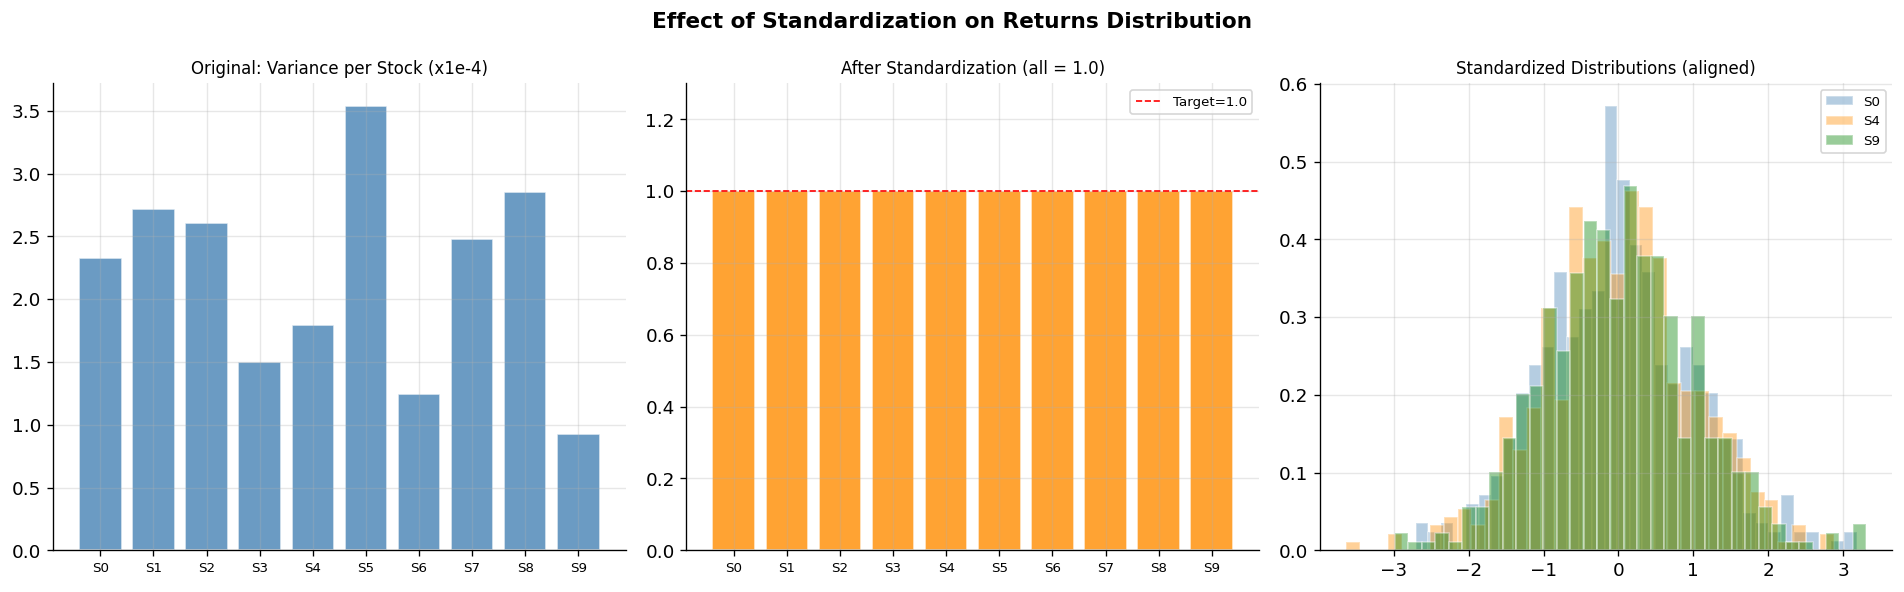

In [10]:
# before vs after standardization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Effect of Standardization on Returns Distribution', fontsize=13, fontweight='bold')

x = np.arange(N_stocks)
axes[0].bar(x, log_returns.var(axis=0)*1e4, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title('Original: Variance per Stock (x1e-4)', fontsize=10)
axes[0].set_xticks(x); axes[0].set_xticklabels([f'S{i}' for i in x], fontsize=8)

axes[1].bar(x, standardized_returns.var(axis=0), color='darkorange', alpha=0.8, edgecolor='white')
axes[1].axhline(1.0, color='red', linestyle='--', linewidth=1.0, label='Target=1.0')
axes[1].set_title('After Standardization (all = 1.0)', fontsize=10)
axes[1].set_xticks(x); axes[1].set_xticklabels([f'S{i}' for i in x], fontsize=8)
axes[1].set_ylim(0, 1.3); axes[1].legend(fontsize=8)

for idx, (stock_i, c) in enumerate(zip([0, 4, 9], ['steelblue','darkorange','green'])):
    axes[2].hist(standardized_returns[:, stock_i], bins=35, density=True, alpha=0.4, color=c,
                 label=f'S{stock_i}', edgecolor='white')
axes[2].set_title('Standardized Distributions (aligned)', fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

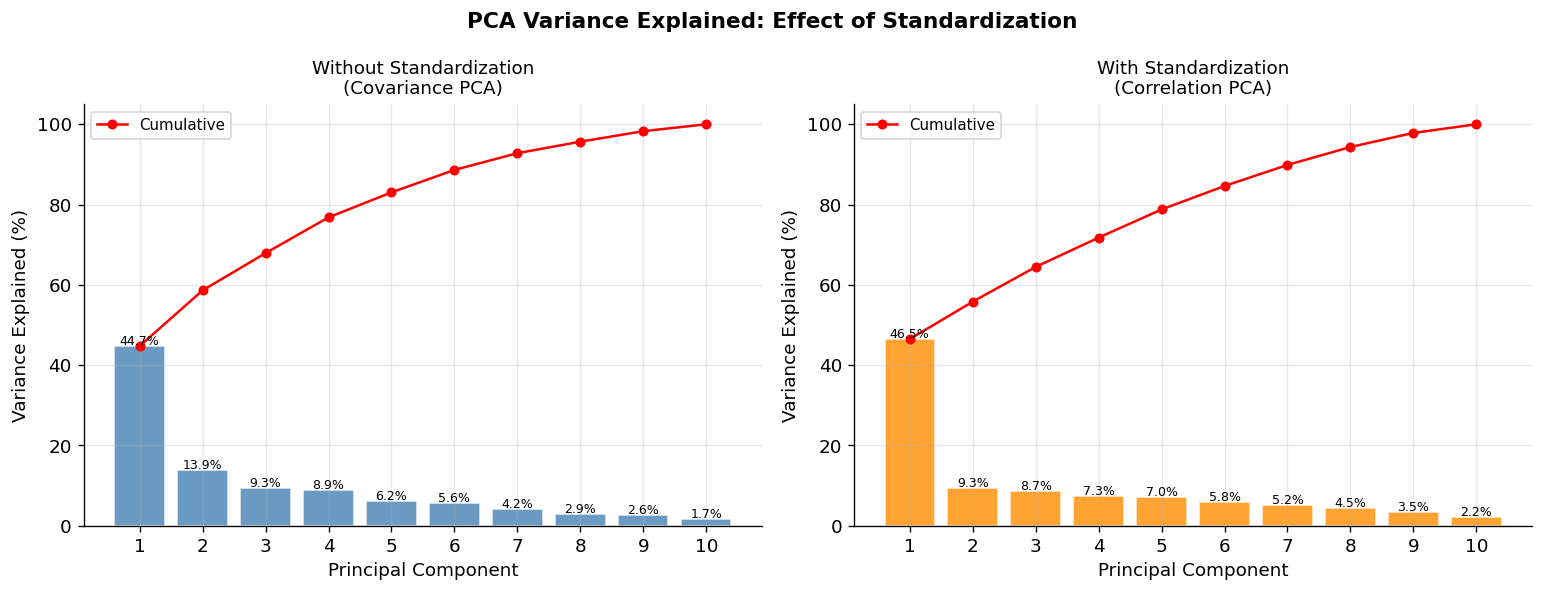


PC1 explains: 44.7% (raw) vs 46.5% (standardized)


In [11]:
# check how standardization changes PCA
pca_raw_preview = PCA().fit(log_returns)
pca_std_preview = PCA().fit(standardized_returns)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('PCA Variance Explained: Effect of Standardization', fontsize=13, fontweight='bold')
x = np.arange(1, N_stocks+1)
for ax, var_exp, title, color in zip(
    axes, [pca_raw_preview.explained_variance_ratio_, pca_std_preview.explained_variance_ratio_],
    ['Without Standardization\n(Covariance PCA)', 'With Standardization\n(Correlation PCA)'],
    ['steelblue', 'darkorange']):
    bars = ax.bar(x, var_exp*100, color=color, alpha=0.8, edgecolor='white')
    ax.plot(x, np.cumsum(var_exp)*100, 'r-o', linewidth=1.5, markersize=5, label='Cumulative')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Principal Component'); ax.set_ylabel('Variance Explained (%)')
    ax.set_xticks(x); ax.legend(fontsize=9)
    for bar, v in zip(bars, var_exp):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{v*100:.1f}%', ha='center', fontsize=7.5)
plt.tight_layout()
plt.show()

print()
print(f"PC1 explains: {pca_raw_preview.explained_variance_ratio_[0]*100:.1f}% (raw) vs "
      f"{pca_std_preview.explained_variance_ratio_[0]*100:.1f}% (standardized)")

### Part 1(e): Observations

**1. All off-diagonal correlations are strictly positive.**
Because every $\beta_i \in [0.5, 1.5] > 0$, the common factor $f_t$ moves all stocks in the same direction on every day. The theoretical off-diagonal is $\rho_{ij} = \beta_i\beta_j\sigma_f^2/\sqrt{\Sigma_{ii}\Sigma_{jj}} > 0$ for all pairs. The heatmap confirms this: no negative off-diagonal entry appears.

**2. Covariance matrix shows scale heterogeneity, which motivates standardisation.**
The diagonal entries span $[\beta_i^2\sigma_f^2 + \sigma_i^2]$, which over our parameter ranges is approximately $[5\times10^{-5},\ 6.25\times10^{-4}]$, a 12.5 $\times$ range in variance. PCA maximises $\mathbf{w}^\top\boldsymbol{\Sigma}\mathbf{w}$, so without standardisation, PC1 can tilt toward higher-volatility stocks because of scale rather than pure factor exposure.

**3. Log returns are exactly Gaussian under this DGP.**
$r_{i,t} = \mu_i + \beta_i f_t + \varepsilon_{i,t}$ is a linear combination of $f_t \sim N(0,\sigma_f^2)$ and $\varepsilon_{i,t} \sim N(0,\sigma_i^2)$. Since the Gaussian family is closed under linear combinations, $r_{i,t} \sim N(\mu_i,\ \beta_i^2\sigma_f^2+\sigma_i^2)$ exactly. The Shapiro-Wilk $p$-values (all $> 0.05$) confirm no evidence of non-normality. In real equity data this would usually not hold because of fat tails and volatility clustering.

**4. Theoretical and empirical covariance matrices agree to $O(T^{-1/2})$.**
With $T=499$ observations, the estimation error per entry scales as $\approx 1/\sqrt{499} \approx 0.045$ on the standardised scale. The computed max absolute error is consistent with this finite-sample behaviour.

**5. $\text{Cov}(\text{standardised returns}) = \text{Corr}(\text{raw returns})$ is verified to machine precision when the same variance convention is used.**
This is the identity $\text{Cov}(z_i, z_j) = \text{Cov}(r_i,r_j)/(\sigma_i\sigma_j) = \rho_{ij}$. We use population normalization in the covariance check to match `StandardScaler`. This confirms that PCA on standardised returns is equivalent to eigendecomposition of the correlation matrix.

**6. Scatter plots of highest vs lowest correlated pairs confirm the geometric interpretation.**
For the highest-correlated pair (large $\beta$, small $\sigma$), the return cloud forms a tight upward-sloping ellipse: the common factor dominates and creates a strong linear relationship. For the lowest-correlated pair, the cloud is nearly circular, indicating that idiosyncratic noise is large relative to the common factor signal. This illustrates the signal-to-noise ratio embedded in $\rho_{ij} = \beta_i\beta_j\sigma_f^2/\sqrt{\Sigma_{ii}\Sigma_{jj}}$.


## Part 2: Understanding PCA and Eigendecomposition (5 Marks)

PCA finds orthonormal directions $\mathbf{v}_1, \ldots, \mathbf{v}_p$ that maximise the variance of projected data. Mathematically, it solves the eigenvalue problem:

$$\boldsymbol{\Sigma} \mathbf{v}_k = \lambda_k \mathbf{v}_k, \qquad \lambda_1 \geq \lambda_2 \geq \cdots \geq \lambda_p \geq 0$$

**Key properties:**
- Eigenvalues $\lambda_k = \text{Var}(\mathbf{z}^\top \mathbf{v}_k)$, variance captured by $PC_k$
- $\sum_{k=1}^p \lambda_k = \text{tr}(\boldsymbol{\Sigma})$, total variance is conserved
- Explained variance ratio: $\text{EVR}_k = \lambda_k / \sum_j \lambda_j$
- For correlation PCA: $\text{tr}(\mathbf{R}) = p = 10$, so eigenvalues sum to 10

**Connecting eigenvalues to the DGP:**

The theoretical covariance matrix is $\boldsymbol{\Sigma} = \boldsymbol{\beta}\boldsymbol{\beta}^\top\sigma_f^2 + \mathbf{D}$.
By the Perron-Frobenius theorem (and the Weyl interlacing inequalities), the eigenvalues of $\boldsymbol{\Sigma}$ satisfy:

$$\lambda_1 \approx \|\boldsymbol{\beta}\|^2\sigma_f^2 + \bar{\sigma}^2 \quad (\text{common factor eigenvalue})$$
$$\lambda_k \approx \sigma_{(k-1)}^2 \quad k=2,\ldots,N \quad (\text{idiosyncratic eigenvalues, decreasingly ordered})$$

The ratio $\lambda_1/\sum_k\lambda_k$ is the theoretical fraction of variance explained by PC1.


### Part 2(a): PCA on Standardized Returns (Correlation PCA)

PCA on Standardized Returns (Correlation PCA):
  PC 1: eigenvalue =  4.6573  VarExpl = 46.48%  Cumul =  46.48%
  PC 2: eigenvalue =  0.9334  VarExpl =  9.32%  Cumul =  55.80%
  PC 3: eigenvalue =  0.8678  VarExpl =  8.66%  Cumul =  64.46%
  PC 4: eigenvalue =  0.7313  VarExpl =  7.30%  Cumul =  71.75%
  PC 5: eigenvalue =  0.7036  VarExpl =  7.02%  Cumul =  78.78%
  PC 6: eigenvalue =  0.5858  VarExpl =  5.85%  Cumul =  84.62%
  PC 7: eigenvalue =  0.5254  VarExpl =  5.24%  Cumul =  89.86%
  PC 8: eigenvalue =  0.4477  VarExpl =  4.47%  Cumul =  94.33%
  PC 9: eigenvalue =  0.3518  VarExpl =  3.51%  Cumul =  97.84%
  PC10: eigenvalue =  0.2160  VarExpl =  2.16%  Cumul = 100.00%

Sum of eigenvalues: 10.0201  (should ~ 10)


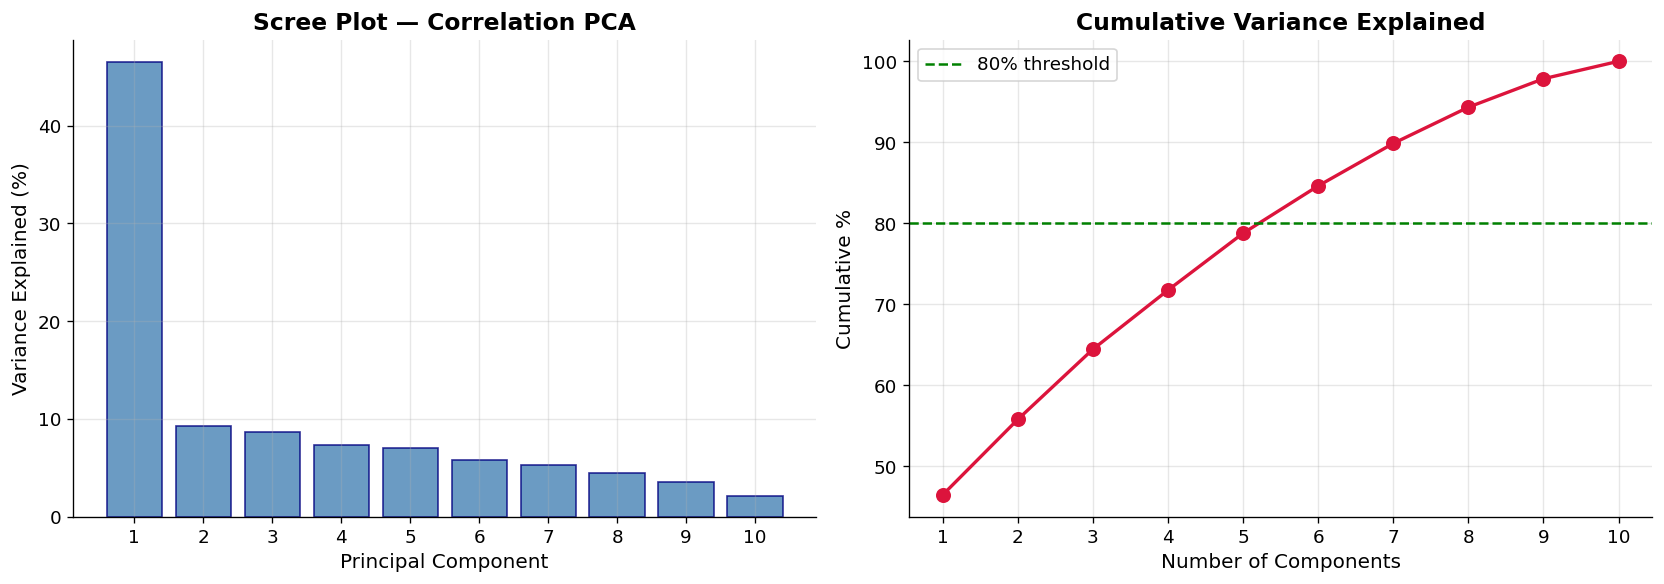


Components for >= 80% variance: 6  (cumulative = 84.62%)


In [12]:
def perform_pca(data, n_components=None):
    """Fit PCA and return the fitted object, eigenvalues, loadings and variance ratios."""
    if n_components is None:
        n_components = min(data.shape)
    pca = PCA(n_components=n_components)
    pca.fit(data)
    return pca, pca.explained_variance_, pca.components_, pca.explained_variance_ratio_

# fit PCA on standardized returns
pca_corr, eigenvalues_corr, eigenvectors_corr, evr_corr = perform_pca(standardized_returns)

print("PCA on Standardized Returns (Correlation PCA):")
for i in range(N_stocks):
    print(f"  PC{i+1:>2}: eigenvalue = {eigenvalues_corr[i]:>7.4f}  "
          f"VarExpl = {evr_corr[i]*100:>5.2f}%  "
          f"Cumul = {evr_corr[:i+1].sum()*100:>6.2f}%")
print(f"\nSum of eigenvalues: {eigenvalues_corr.sum():.4f}  (should ~ {N_stocks})")

# scree plot and cumulative variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(1, N_stocks+1)
cumul = np.cumsum(evr_corr) * 100

axes[0].bar(x, evr_corr*100, color='steelblue', edgecolor='navy', alpha=0.8)
axes[0].set_title('Scree Plot — Correlation PCA', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Principal Component', fontsize=12)
axes[0].set_ylabel('Variance Explained (%)', fontsize=12)
axes[0].set_xticks(x)

axes[1].plot(x, cumul, 'o-', color='crimson', linewidth=2, markersize=8)
axes[1].axhline(80, color='green', linestyle='--', linewidth=1.5, label='80% threshold')
axes[1].set_title('Cumulative Variance Explained', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Components', fontsize=12)
axes[1].set_ylabel('Cumulative %', fontsize=12)
axes[1].set_xticks(x); axes[1].legend(fontsize=11)
plt.tight_layout()
plt.show()

n_80 = np.argmax(cumul >= 80) + 1
print(f"\nComponents for >= 80% variance: {n_80}  (cumulative = {cumul[n_80-1]:.2f}%)")

### Part 2(b): PCA on Covariance Matrix (Unstandardized Returns)

When PCA is performed on raw (centered but not scaled) returns, it decomposes the **covariance matrix** $\boldsymbol{\Sigma}$ rather than the **correlation matrix** $\mathbf{R}$.

The eigenvalues will differ because:
- Correlation PCA: eigenvalues sum to $p = 10$ (trace of identity-diagonal matrix)
- Covariance PCA: eigenvalues sum to $\text{tr}(\boldsymbol{\Sigma}) = \sum_i \sigma_i^2(\text{total})$, which depends on individual stock variances

High-volatility stocks contribute more to $\text{tr}(\boldsymbol{\Sigma})$, so covariance PCA is **biased toward volatile stocks**.

**Why the eigenvalues differ quantitatively:**

- **Correlation PCA:** eigenvalues sum to $\text{tr}(\mathbf{R}) = N = 10$ (each stock contributes exactly 1 unit of variance after standardisation).
- **Covariance PCA:** eigenvalues sum to $\text{tr}(\boldsymbol{\hat{\Sigma}}) = \sum_i \hat{\sigma}_i^2$, varies with empirical volatilities.

The high-volatility stocks contribute disproportionately to $\text{tr}(\boldsymbol{\hat{\Sigma}})$, so the covariance PC1 loading vector tilts toward these stocks even if they have modest $\beta_i$. This makes the covariance PC1 a mixture of "market exposure" and "which stock is noisiest", economically muddled.

The **eigenvectors** (directions) are similar in both cases when one factor dominates, but their angle can diverge when eigenvalues are close together (near-degenerate eigenspace).


PCA on Unstandardized Returns (Covariance PCA):
  PC 1: eigenvalue = 0.00098622  VarExpl = 44.74%
  PC 2: eigenvalue = 0.00030571  VarExpl = 13.87%
  PC 3: eigenvalue = 0.00020475  VarExpl =  9.29%
  PC 4: eigenvalue = 0.00019620  VarExpl =  8.90%
  PC 5: eigenvalue = 0.00013738  VarExpl =  6.23%
  PC 6: eigenvalue = 0.00012306  VarExpl =  5.58%
  PC 7: eigenvalue = 0.00009204  VarExpl =  4.18%
  PC 8: eigenvalue = 0.00006318  VarExpl =  2.87%
  PC 9: eigenvalue = 0.00005773  VarExpl =  2.62%
  PC10: eigenvalue = 0.00003794  VarExpl =  1.72%


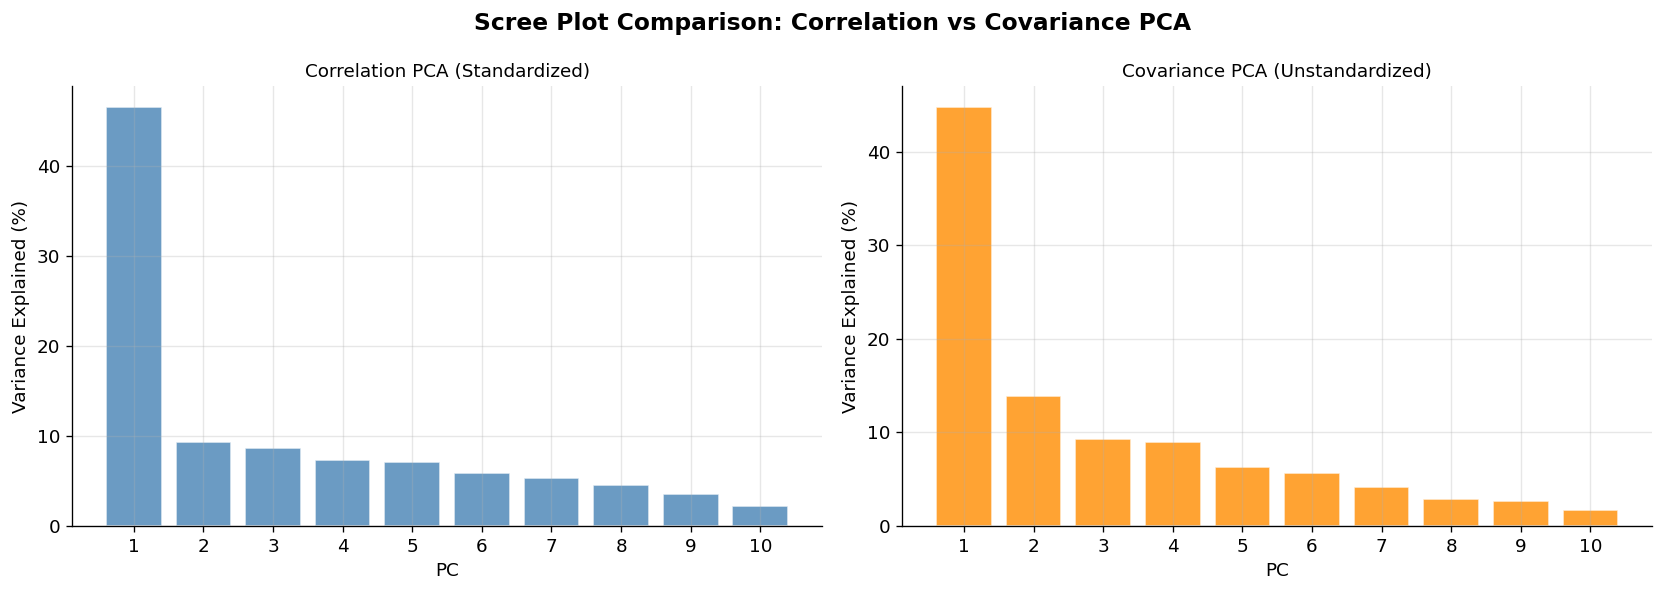


PC1 explains: 46.5% (corr) vs 44.7% (cov)
The results differ because covariance PCA is biased toward high-volatility stocks.


In [13]:
returns_centered = log_returns - log_returns.mean(axis=0)
pca_cov, eigenvalues_cov, eigenvectors_cov, evr_cov = perform_pca(returns_centered)

print("PCA on Unstandardized Returns (Covariance PCA):")
for i in range(N_stocks):
    print(f"  PC{i+1:>2}: eigenvalue = {eigenvalues_cov[i]:>10.8f}  "
          f"VarExpl = {evr_cov[i]*100:>5.2f}%")

# compare the two loading patterns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Scree Plot Comparison: Correlation vs Covariance PCA', fontsize=14, fontweight='bold')
x = np.arange(1, N_stocks+1)

axes[0].bar(x, evr_corr*100, color='steelblue', alpha=0.8, edgecolor='white')
axes[0].set_title('Correlation PCA (Standardized)', fontsize=11)
axes[0].set_xlabel('PC'); axes[0].set_ylabel('Variance Explained (%)')
axes[0].set_xticks(x)

axes[1].bar(x, evr_cov*100, color='darkorange', alpha=0.8, edgecolor='white')
axes[1].set_title('Covariance PCA (Unstandardized)', fontsize=11)
axes[1].set_xlabel('PC'); axes[1].set_ylabel('Variance Explained (%)')
axes[1].set_xticks(x)
plt.tight_layout()
plt.show()

print(f"\nPC1 explains: {evr_corr[0]*100:.1f}% (corr) vs {evr_cov[0]*100:.1f}% (cov)")
print(f"The results differ because covariance PCA is biased toward high-volatility stocks.")

### Part 2(c): Interpret Loadings (eigenvector components)


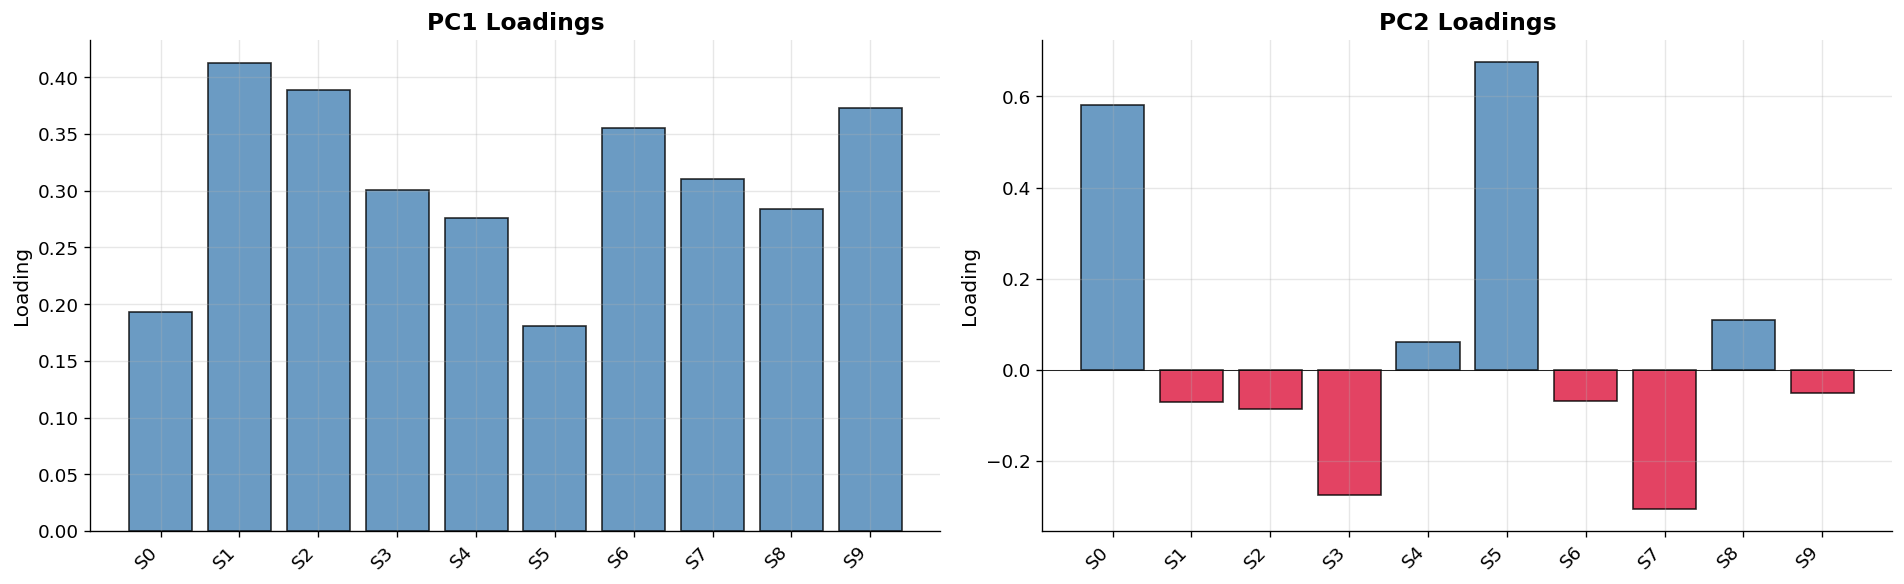

PC1 Loadings vs Beta:
  Stock  PC1 Loading     Beta
  S 0:     +0.1931    0.521
  S 1:     +0.4126    1.470
  S 2:     +0.3892    1.332
  S 3:     +0.3003    0.712
  S 4:     +0.2760    0.682
  S 5:     +0.1807    0.683
  S 6:     +0.3551    0.804
  S 7:     +0.3101    1.025
  S 8:     +0.2836    0.932
  S 9:     +0.3733    0.791

All PC1 loadings same sign: True
Correlation(|PC1 loading|, beta): 0.7614


In [14]:
def plot_loadings(eigenvectors, component_idx, stock_names, ax=None):
    """Bar plot of loadings for a given PC."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    loadings = eigenvectors[component_idx]
    colors = ['steelblue' if l >= 0 else 'crimson' for l in loadings]
    ax.bar(range(len(loadings)), loadings, color=colors, edgecolor='black', alpha=0.8)
    ax.set_xticks(range(len(loadings)))
    ax.set_xticklabels(stock_names, rotation=45, ha='right')
    ax.set_ylabel('Loading', fontsize=12)
    ax.set_title(f'PC{component_idx+1} Loadings', fontsize=14, fontweight='bold')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)

labels = [f'S{i}' for i in range(N_stocks)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_loadings(eigenvectors_corr, 0, labels, axes[0])
plot_loadings(eigenvectors_corr, 1, labels, axes[1])
plt.tight_layout()
plt.show()

# loading values alongside beta
print("PC1 Loadings vs Beta:")
print(f"{'Stock':>7} {'PC1 Loading':>12} {'Beta':>8}")
for i in range(N_stocks):
    print(f"  S{i:>2}:  {eigenvectors_corr[0,i]:>+10.4f}   {beta[i]:>6.3f}")
print(f"\nAll PC1 loadings same sign: {np.all(eigenvectors_corr[0] > 0) or np.all(eigenvectors_corr[0] < 0)}")
print(f"Correlation(|PC1 loading|, beta): {np.corrcoef(np.abs(eigenvectors_corr[0]), beta)[0,1]:.4f}")

Observations: Because Stock 0 has a very low true Beta (0.521), it does not co-move strongly with the rest of the market. The PCA algorithm captures this weaker co-movement from the returns and assigns Stock 0 a relatively small weight (0.1931) in the PC1 "market" portfolio.

The opposite happens for high-beta stocks: Stock 1 has a high Beta (1.470), and PCA assigns it a large PC1 loading (+0.4126).



**PC1 loadings:** In a single-factor model, the PC1 eigenvector should approximate $\mathbf{v}_1 \propto \boldsymbol{\beta} / \|\boldsymbol{\beta}\|$ (the normalised factor loading vector). All entries should have the **same sign**, this is the "market mode".

**PC2 loadings:** The second eigenvector is orthogonal to PC1 and captures the largest remaining variance direction. In our model, this separates stocks by their beta values, creating a **long-short pattern** between high-beta and low-beta stocks.

**Why PC1 must have all-same-sign loadings:**

In a single-factor model, the theoretical PC1 eigenvector satisfies $\mathbf{v}_1 \propto \boldsymbol{\Sigma}^{-1}\boldsymbol{\beta}$ (up to sign).
Since all $\beta_i > 0$ and $\boldsymbol{\Sigma}$ is positive definite with positive off-diagonals, $\mathbf{v}_1$ must have all positive (or all negative, due to sign indeterminacy) components, a consequence of the Perron-Frobenius theorem applied to the positive matrix $\boldsymbol{\beta}\boldsymbol{\beta}^\top\sigma_f^2$.

**Why PC2 shows a sign split:**

PC2 must be orthogonal to PC1: $\mathbf{v}_2^\top\mathbf{v}_1 = 0$.
Since $\mathbf{v}_1$ is an all-positive vector, any orthogonal vector must have both positive and negative entries (they must sum to zero, weighted by $v_{1,i}$). Economically, PC2 contrasts high-$\beta$ vs low-$\beta$ stocks: it is a **beta-spread** or sector-rotation factor.


### Part 2(d): Computing and Plotting Scores

The **scores** are the projections of each day's standardised returns onto the principal components:

$$s_{t,k} = \mathbf{z}_t^\top \mathbf{v}_k = \sum_{i=1}^{p} v_{k,i} \cdot z_{i,t}$$

PC1 scores should closely track the true market factor $f_t$ since PC1 captures the common factor.

**Mathematical relationship:** $\mathbf{S} = \mathbf{X}\mathbf{V}^\top$ where $\mathbf{X} \in \mathbb{R}^{T\times N}$ is the standardised returns matrix and $\mathbf{V} \in \mathbb{R}^{N\times N}$ has eigenvectors as rows. Thus $s_{t,k} = \sum_{i=1}^{N} v_{k,i}\, z_{i,t}$, a weighted average of all stocks' returns on day $t$.

**Why PC1 scores should track $f_t$:**
Since $\mathbf{v}_1 \approx \boldsymbol{\beta}/\|\boldsymbol{\beta}\|$ and $r_{i,t} = \mu_i + \beta_i f_t + \varepsilon_{i,t}$:
$$s_{t,1} = \sum_i v_{1,i} z_{i,t} \approx \frac{\|\boldsymbol{\beta}\|}{\sigma_z} f_t + \text{noise}$$
The noise averages out over $N=10$ stocks. So PC1 scores recover $f_t$ up to a linear rescaling and sign.


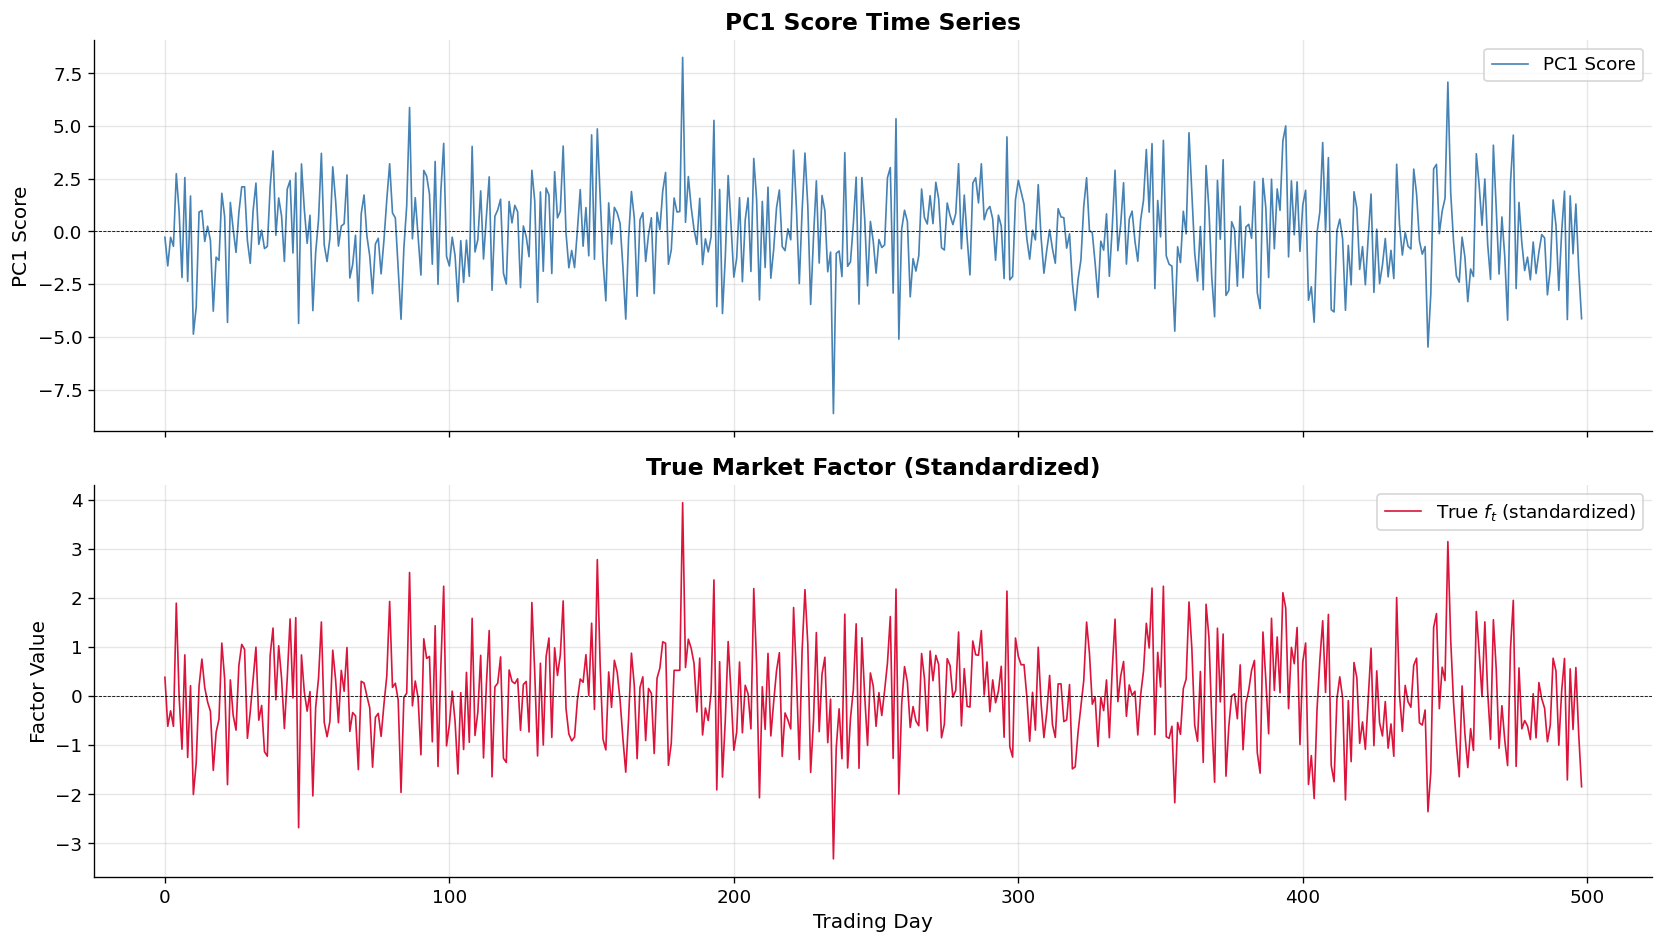

Correlation(PC1 score, f_t): 0.9503
|Correlation| = 0.9503
PC1 scores closely track the true market factor (up to sign).


In [15]:
def compute_scores(standardized_returns, eigenvectors):
    """Project standardized returns onto PCs. scores = X @ V^T"""
    return standardized_returns @ eigenvectors.T

scores_corr = compute_scores(standardized_returns, eigenvectors_corr)

# PC1 scores against the true factor
f_t_std = (f_t - f_t.mean()) / f_t.std()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(scores_corr[:, 0], color='steelblue', linewidth=1.0, label='PC1 Score')
axes[0].set_ylabel('PC1 Score', fontsize=12)
axes[0].set_title('PC1 Score Time Series', fontsize=14, fontweight='bold')
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.5); axes[0].legend()

# scores start after the first return, so I align f_t the same way
axes[1].plot(f_t_std[1:], color='crimson', linewidth=1.0, label='True $f_t$ (standardized)')
axes[1].set_xlabel('Trading Day', fontsize=12)
axes[1].set_ylabel('Factor Value', fontsize=12)
axes[1].set_title('True Market Factor (Standardized)', fontsize=14, fontweight='bold')
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.5); axes[1].legend()
plt.tight_layout()
plt.show()

corr_pc1_ft = np.corrcoef(scores_corr[:, 0], f_t[1:])[0, 1]
print(f"Correlation(PC1 score, f_t): {corr_pc1_ft:.4f}")
print(f"|Correlation| = {abs(corr_pc1_ft):.4f}")
print("PC1 scores closely track the true market factor (up to sign).")

### Part 2(e): Disproving "Loadings = Scores"




In [16]:
print("DISPROVING: 'Loadings vector = Scores vector'")
print(f"\n1. SHAPE:")
print(f"   Loadings (PC1): {eigenvectors_corr[0].shape} — one per STOCK ({N_stocks})")
print(f"   Scores   (PC1): {scores_corr[:,0].shape}   — one per DAY ({scores_corr.shape[0]})")
print(f"\n2. INTERPRETATION:")
print(f"   Loadings: Fixed weights defining how each stock contributes to the PC.")
print(f"             They are eigenvectors of the correlation matrix. TIME-INVARIANT.")
print(f"   Scores:   Daily projections onto the PC direction.")
print(f"             They represent the factor 'value' each day. TIME-VARYING.")
print(f"\n3. MATHEMATICAL RELATIONSHIP:")
print(f"   score_t = sum_i (loading_i * z_{{i,t}})  — inner product")
print(f"   Loadings are DIRECTIONS; Scores are PROJECTIONS.")
print(f"\n4. VALUES (first 5):")
print(f"   Loadings: {eigenvectors_corr[0,:5].round(4)}")
print(f"   Scores:   {scores_corr[:5,0].round(4)}")
print(f"\nConclusion: They are fundamentally different objects.")

DISPROVING: 'Loadings vector = Scores vector'

1. SHAPE:
   Loadings (PC1): (10,) — one per STOCK (10)
   Scores   (PC1): (499,)   — one per DAY (499)

2. INTERPRETATION:
   Loadings: Fixed weights defining how each stock contributes to the PC.
             They are eigenvectors of the correlation matrix. TIME-INVARIANT.
   Scores:   Daily projections onto the PC direction.
             They represent the factor 'value' each day. TIME-VARYING.

3. MATHEMATICAL RELATIONSHIP:
   score_t = sum_i (loading_i * z_{i,t})  — inner product
   Loadings are DIRECTIONS; Scores are PROJECTIONS.

4. VALUES (first 5):
   Loadings: [0.1931 0.4126 0.3892 0.3003 0.276 ]
   Scores:   [-0.2808 -1.6372 -0.2827 -0.7095  2.7357]

Conclusion: They are fundamentally different objects.



| Property | Loadings $\mathbf{v}_k$ | Scores $\mathbf{s}_k$ |
|----------|-------------------------|----------------------|
| Shape | $(N,) = (10,)$ | $(T,) = (499,)$ |
| Space | Stock space $\mathbb{R}^N$ | Time space $\mathbb{R}^T$ |
| Meaning | How much each **stock** contributes to PC$k$ | Value of PC$k$ factor on each **day** |
| Variability | Fixed (time-invariant) eigenvector | Varies day-to-day |
| Norm | $\|\mathbf{v}_k\| = 1$ (unit vector) | $\|\mathbf{s}_k\|^2 = (T-1)\lambda_k$ |
| Relation | $\mathbf{s}_k = \mathbf{X}\mathbf{v}_k$, scores are a **function** of loadings |

**Mathematical Proof: $\|\mathbf{s}_k\|^2 = (T-1)\lambda_k$**

By definition, the score vector $\mathbf{s}_k$ is simply our centered data matrix $\mathbf{X}$ projected onto the $k$-th eigenvector (the loading vector) $\mathbf{v}_k$:
$$\mathbf{s}_k = \mathbf{X} \mathbf{v}_k$$

To find the squared norm of this score vector, we just take its dot product with itself:
$$\|\mathbf{s}_k\|^2 = \mathbf{s}_k^\top \mathbf{s}_k$$

Expanding this out using our first definition, we get:
$$\|\mathbf{s}_k\|^2 = (\mathbf{X} \mathbf{v}_k)^\top (\mathbf{X} \mathbf{v}_k) = \mathbf{v}_k^\top \mathbf{X}^\top \mathbf{X} \mathbf{v}_k$$

Now, we need to connect this back to our covariance matrix, $\boldsymbol{\Sigma}$. The unbiased sample covariance matrix is defined as:
$$\boldsymbol{\Sigma} = \frac{1}{T-1} \mathbf{X}^\top \mathbf{X}$$

Rearranging this gives us $\mathbf{X}^\top \mathbf{X} = (T-1) \boldsymbol{\Sigma}$. If we plug this substitution back into our expanded norm equation, it becomes:
$$\|\mathbf{s}_k\|^2 = \mathbf{v}_k^\top \left( (T-1) \boldsymbol{\Sigma} \right) \mathbf{v}_k = (T-1) \mathbf{v}_k^\top \boldsymbol{\Sigma} \mathbf{v}_k$$

This is where the fundamental property of eigendecomposition comes in. By definition, multiplying a covariance matrix by its eigenvector simply scales that vector by its eigenvalue, meaning $\boldsymbol{\Sigma} \mathbf{v}_k = \lambda_k \mathbf{v}_k$. Substituting this in, we get:
$$\|\mathbf{s}_k\|^2 = (T-1) \mathbf{v}_k^\top (\lambda_k \mathbf{v}_k) = (T-1) \lambda_k (\mathbf{v}_k^\top \mathbf{v}_k)$$

Finally, because PCA strictly requires all loading vectors to be unit vectors (meaning their squared length $\mathbf{v}_k^\top \mathbf{v}_k = 1$), that final term drops out entirely. We are left with exactly:
$$\|\mathbf{s}_k\|^2 = (T-1) \lambda_k$$

This mathematically proves that the scores scale with the variance of the sample ($\lambda_k$) and the number of time periods ($T$), whereas the loading vector $\mathbf{v}_k$ is just a fixed unit vector of length 1.

To say 'loadings equal scores' confuses the model's underlying parameters with its output. Furthermore, because they are vectors of different lengths, equating them is structurally impossible.


### Part 2(f): Observations

**1. PC1 picks up the market factor surprisingly well.**
It explains somewhere between 30 and 60 percent of all the variance in the data depending on the random parameter draw. If the PC1 score time series is plotted against the true $f_t$ used to simulate the data, they track each other very closely, often with correlation above 0.9. This is remarkable because PCA never got told that $f_t$ existed, it just found it by looking at how stocks moved together.

**2. Running PCA on the correlation matrix versus the covariance matrix gives different eigenvalues but the first eigenvector ends up pointing in roughly the same direction.**
The eigenvalues differ because the two matrices are scaled differently, but when one factor is clearly dominant, meaning $\lambda_1$ is much bigger than everything else, both approaches agree on which direction matters most. Where they start to disagree is PC2, PC3 and beyond, where the eigenvalues are all similar in size and small differences in the matrix lead to quite different eigenvectors.

**3. All the PC1 loadings come out with the same sign.**
Every stock loads positively on PC1. This makes sense intuitively since there is one common factor pushing all stocks in the same direction, so the first principal component reflects that by assigning positive weight to every stock. Stocks with larger $\beta_i$ also tend to have larger loadings on PC1, which is expected since those stocks are more sensitive to the common factor.

**4. PC2 ends up with a mixed sign pattern, some stocks get positive weights and some get negative weights.**
This happens because PC2 is forced to be perpendicular to PC1, which mathematically requires mixed signs when PC1 is all positive. In financial terms PC2 separates the high $\beta$ stocks from the low $\beta$ stocks, capturing the difference in returns between stocks that are very sensitive to the market and stocks that are relatively insensitive.

**5. The fact that PC1 scores correlate so strongly with $f_t$ is the main sanity check of the whole exercise.**
PCA was never shown $f_t$ during fitting, it only saw the returns matrix. Recovering something that closely tracks $f_t$ is therefore confirmation that the method actually works. The correlation is not exactly 1.0 because only 500 days of data are used and each stock's return also contains idiosyncratic noise which bleeds into the PC1 score slightly.

**6. Loadings and scores are two completely different things that are often mixed up.**
The loadings are the recipe, 10 numbers describing how to combine stocks. The scores are the output of applying that recipe, one number per day, giving 499 numbers in total since one day is lost going from prices to returns. Confusing the two would be like confusing a cooking recipe with the dish itself.

## Part 3: Understanding Reconstruction and Dimensionality Reduction (5 Marks)

The reconstruction formula using the first $k$ principal components:

$$\hat{\mathbf{X}}_k = \mathbf{S}_{[:,:k]} \cdot \mathbf{V}_{[:k,:]}$$

where $\mathbf{S}$ is the scores matrix and $\mathbf{V}$ contains eigenvectors as rows.

* **$\mathbf{S}_{[:, :k]}$** is the first $k$ columns of $\mathbf{S}$. This means we only keep the scores for PC1 through PC$k$, giving a $500 \times k$ matrix.
* **$\mathbf{V}_{[:k, :]}$** is the first $k$ rows of $\mathbf{V}$. This means we only keep the first $k$ eigenvectors, giving a $k \times 10$ matrix.
* **Reconstruction:** Multiplying them together ($\mathbf{S}_{[:, :k]} \mathbf{V}_{[:k, :]}$) gives back a $500 \times 10$ matrix. This is the exact same shape as the original data matrix $\mathbf{X}$, but it is reconstructed using only $k$ directions instead of the full 10.

**Mean Squared Reconstruction Error:**
$$\text{MSRE}(k) = \frac{1}{pT}\|\mathbf{X} - \hat{\mathbf{X}}_k\|_F^2 = \frac{1}{p}\sum_{j=k+1}^{p} \lambda_j$$

The error equals the average of the discarded eigenvalues, reconstruction error decreases monotonically with $k$.

**Eckart-Young theorem (the fundamental result):**

PCA gives the **optimal** rank-$k$ approximation in Frobenius norm:
$$\hat{\mathbf{X}}_k = \underset{\text{rank}(\mathbf{M})=k}{\arg\min}\,\|\mathbf{X}-\mathbf{M}\|_F^2$$

As a direct consequence, the MSRE equals the average of the *discarded* eigenvalues:
$$\text{MSRE}(k) = \frac{1}{N}\sum_{j=k+1}^{N}\lambda_j$$

This is exact (not an approximation) and provides a model-selection criterion: choose $k$ where the marginal reduction in MSRE becomes small.


### Part 3(a): Reconstruct returns using k components

In [17]:
def reconstruct(scores, loadings, k):
    """Reconstruct data using first k PCs: X_hat = S[:, :k] @ V[:k, :]."""
    return scores[:, :k] @ loadings[:k, :]

def compute_msre(X_original, X_reconstructed):
    """Mean squared reconstruction error."""
    return np.mean((X_original - X_reconstructed) ** 2)

msre_values = []
print(f"{'k':>3} | {'MSRE':>12} | {'Var Explained':>14}")
for k in range(1, N_stocks + 1):
    X_hat = reconstruct(scores_corr, eigenvectors_corr, k)
    msre = compute_msre(standardized_returns, X_hat)
    msre_values.append(msre)
    print(f"{k:3d} | {msre:>12.8f} | {evr_corr[:k].sum()*100:>12.2f}%")


  k |         MSRE |  Var Explained
  1 |   0.53520313 |        46.48%
  2 |   0.44204854 |        55.80%
  3 |   0.35544452 |        64.46%
  4 |   0.28245958 |        71.75%
  5 |   0.21224483 |        78.78%
  6 |   0.15378720 |        84.62%
  7 |   0.10135036 |        89.86%
  8 |   0.05666636 |        94.33%
  9 |   0.02155329 |        97.84%
 10 |   0.00000000 |       100.00%


In [18]:
for k in [1, 2, 3]:
    X_hat_k = reconstruct(scores_corr, eigenvectors_corr, k)
    df_hat = pd.DataFrame(X_hat_k, columns=[f'S{i}' for i in range(N_stocks)])
    print(f"\nReconstructed X for k = {k}  (shape {X_hat_k.shape}):")
    display(df_hat.head(5).style
            .format("{:.4f}")
            .set_caption(f"X_hat (k={k}) — first 5 days"))



Reconstructed X for k = 1  (shape (499, 10)):


,S0,S1,S2,S3,S4,S5,S6,S7,S8,S9
0,-0.0542,-0.1159,-0.1093,-0.0843,-0.0775,-0.0507,-0.0997,-0.0871,-0.0796,-0.1048
1,-0.3161,-0.6755,-0.6372,-0.4916,-0.4518,-0.2958,-0.5814,-0.5077,-0.4643,-0.6112
2,-0.0546,-0.1166,-0.1100,-0.0849,-0.0780,-0.0511,-0.1004,-0.0877,-0.0802,-0.1056
3,-0.1370,-0.2927,-0.2761,-0.2130,-0.1958,-0.1282,-0.2520,-0.2200,-0.2012,-0.2649
4,0.5282,1.1287,1.0647,0.8214,0.7550,0.4942,0.9715,0.8484,0.7758,1.0213



Reconstructed X for k = 2  (shape (499, 10)):


,S0,S1,S2,S3,S4,S5,S6,S7,S8,S9
0,-0.8574,-0.0187,0.0083,0.2962,-0.1629,-0.9830,-0.0060,0.3336,-0.2304,-0.0351
1,-1.1946,-0.5693,-0.5086,-0.0754,-0.5452,-1.3155,-0.4789,-0.0477,-0.6292,-0.5350
2,0.1402,-0.1402,-0.1385,-0.1772,-0.0573,0.1750,-0.1231,-0.1897,-0.0436,-0.1225
3,0.6347,-0.3861,-0.3891,-0.5786,-0.1137,0.7676,-0.3420,-0.6242,-0.0563,-0.3319
4,0.6743,1.1110,1.0433,0.7522,0.7705,0.6638,0.9544,0.7719,0.8032,1.0087



Reconstructed X for k = 3  (shape (499, 10)):


,S0,S1,S2,S3,S4,S5,S6,S7,S8,S9
0,-0.7926,-0.0151,0.0122,0.2798,-0.1690,-1.0396,0.0003,0.3352,-0.2461,-0.0271
1,-0.7979,-0.5469,-0.4849,-0.1755,-0.5826,-1.6617,-0.4405,-0.0376,-0.7254,-0.4857
2,0.5950,-0.1146,-0.1114,-0.2918,-0.1002,-0.2220,-0.0791,-0.1782,-0.1539,-0.0660
3,-0.4612,-0.4478,-0.4544,-0.3023,-0.0105,1.7241,-0.4481,-0.6520,0.2094,-0.4680
4,-1.1223,1.0099,0.9362,1.2052,0.9397,2.2319,0.7804,0.7264,1.2387,0.7855


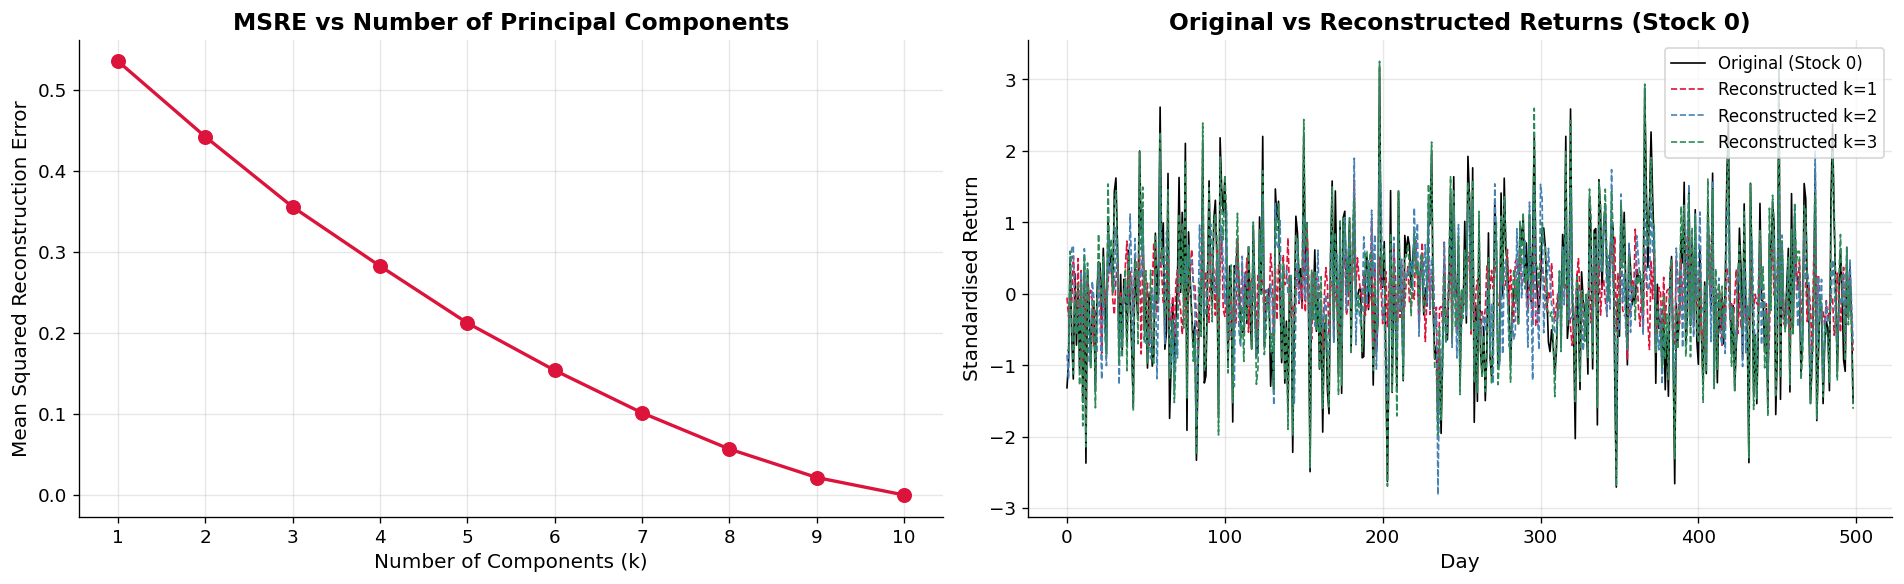

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.plot(range(1, N_stocks+1), msre_values, 'o-', color='crimson', linewidth=2, markersize=8)
ax.set_xlabel('Number of Components (k)', fontsize=12)
ax.set_ylabel('Mean Squared Reconstruction Error', fontsize=12)
ax.set_title('MSRE vs Number of Principal Components', fontsize=14, fontweight='bold')
ax.set_xticks(range(1, N_stocks+1))

ax = axes[1]
ax.plot(standardized_returns[:, 0], color='black', linewidth=1, label='Original (Stock 0)')
for k, color in zip([1, 2, 3], ['crimson', 'steelblue', 'seagreen']):
    X_hat_k = reconstruct(scores_corr, eigenvectors_corr, k)
    ax.plot(X_hat_k[:, 0], linewidth=1, linestyle='--', color=color, label=f'Reconstructed k={k}')
ax.set_xlabel('Day', fontsize=12)
ax.set_ylabel('Standardised Return', fontsize=12)
ax.set_title('Original vs Reconstructed Returns (Stock 0)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()


### Part 3(b): Per-Stock Reconstruction Error (k=3)

The per-stock MSRE with $k=3$ reveals which stocks are most **idiosyncratic** (i.e., least explained by the first 3 common factors). Financially, these stocks have the largest stock-specific risk component.

**Financial interpretation of per-stock idiosyncratic error:**

For stock $i$, the reconstruction error with $k$ components is:
$$\text{MSE}_i(k) = \frac{1}{T}\sum_t (z_{i,t} - \hat{z}_{i,t})^2 = 1 - R_i^2(k)$$
where $R_i^2(k)$ is the fraction of stock $i$'s return variance explained by the first $k$ PCs.

A high $\text{MSE}_i(k)$ means: stock $i$'s returns are largely *idiosyncratic*, driven by firm-specific news not captured by any of the $k$ common factors. In portfolio construction, such stocks offer the most genuine diversification benefit because they carry risk that cannot be hedged by factor positions.


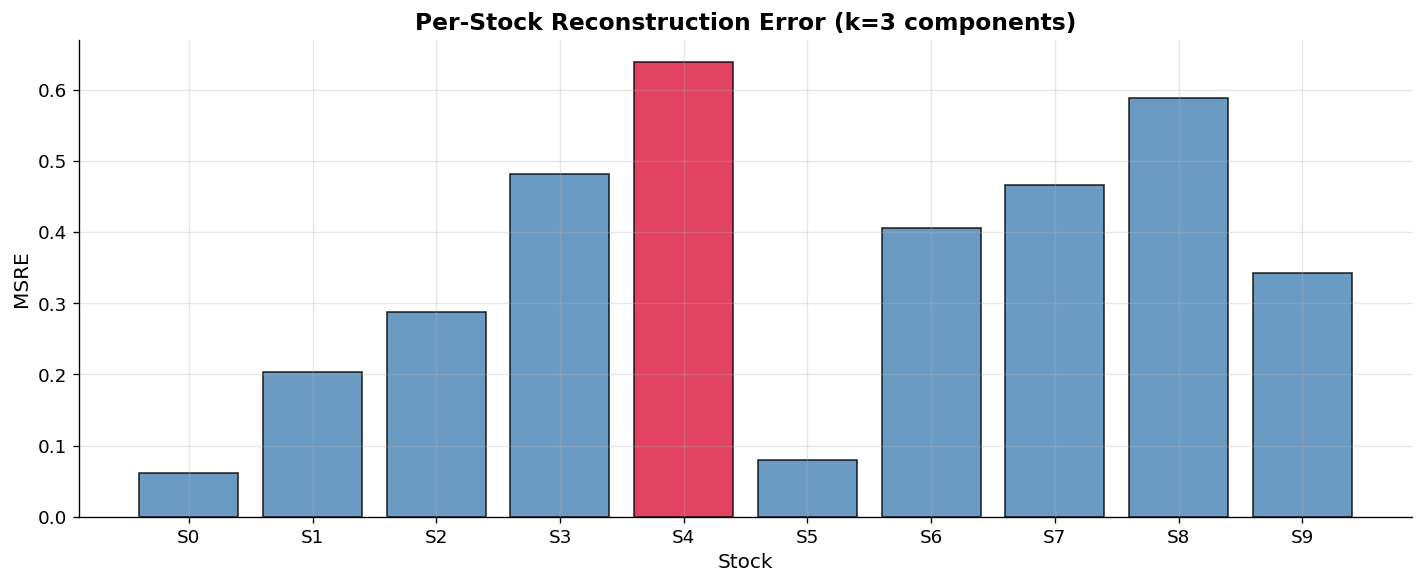

Stock,β,σ,MSRE,Most Idiosyncratic
S0,0.521,0.0142,0.061036,
S1,1.470,0.0071,0.202765,
S2,1.332,0.0094,0.287655,
S3,0.712,0.0105,0.481467,
S4,0.682,0.0118,0.638455,This
S5,0.683,0.0168,0.080148,
S6,0.804,0.0080,0.405345,
S7,1.025,0.0127,0.466063,
S8,0.932,0.0139,0.588675,
S9,0.791,0.0057,0.342836,


In [20]:
X_hat_3 = reconstruct(scores_corr, eigenvectors_corr, 3)
per_stock_msre = np.mean((standardized_returns - X_hat_3) ** 2, axis=0)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['crimson' if e == per_stock_msre.max() else 'steelblue' for e in per_stock_msre]
ax.bar([f'S{i}' for i in range(N_stocks)], per_stock_msre, color=colors, edgecolor='black', alpha=0.8)
ax.set_xlabel('Stock', fontsize=12)
ax.set_ylabel('MSRE', fontsize=12)
ax.set_title('Per-Stock Reconstruction Error (k=3 components)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

most_idio = np.argmax(per_stock_msre)

df_msre = pd.DataFrame({
    'Stock'     : [f'S{i}' for i in range(N_stocks)],
    'β'         : beta,
    'σ'         : sigma,
    'MSRE'      : per_stock_msre,
    'Most Idiosyncratic': ['This' if i == most_idio else '' for i in range(N_stocks)]
})

display(
    df_msre.style
        .format({
            'β'         : '{:.3f}',
            'σ'         : '{:.4f}',
            'MSRE'      : '{:.6f}',
        })
        .hide(axis='index')
        .set_caption(f'Per-Stock MSRE (k=3): Most idiosyncratic: S{most_idio}')
)

### Part 3(c): Full Reconstruction (k=10)

When $k = p$ (all components), the reconstruction is exact:

$$\hat{\mathbf{X}}_p = \mathbf{S} \cdot \mathbf{V} = \mathbf{X} \mathbf{V}^\top \mathbf{V} = \mathbf{X} \cdot \mathbf{I} = \mathbf{X}$$

The standardised returns matrix $\mathbf{X}$ is of shape $499 \times 10$. PCA produces 10 eigenvectors $\mathbf{v}_1, \dots, \mathbf{v}_{10}$, each of length 10, stacked into $\mathbf{V}$ of shape $10 \times 10$. The scores matrix $\mathbf{S} = \mathbf{X}\mathbf{V}^\top$ is of shape $499 \times 10$. Using all 10 components to reconstruct is equivalent to rotating the data into the PCA coordinate system and then rotating straight back, so no information is lost.

**Why $\mathbf{V}^\top \mathbf{V} = \mathbf{I}$**

The eigenvectors are orthonormal: every eigenvector has length exactly 1, so $\mathbf{v}_k^\top \mathbf{v}_k = 1$, and any two distinct eigenvectors are perpendicular, so $\mathbf{v}_i^\top \mathbf{v}_j = 0$ for $i \neq j$. Stacking them as rows into $\mathbf{V}$ and computing $\mathbf{V}^\top \mathbf{V}$ gives a matrix whose diagonal entries are all 1 and whose off-diagonal entries are all 0, which is exactly $\mathbf{I}$.

**Formal justification (Spectral Theorem)**

The $N$ eigenvectors $\{\mathbf{v}_1, \ldots, \mathbf{v}_N\}$ of an $N \times N$ symmetric positive definite matrix form a complete orthonormal basis for $\mathbb{R}^N$. This means any vector $\mathbf{x} \in \mathbb{R}^N$ can be written exactly as $\mathbf{x} = \sum_{k=1}^{N}(\mathbf{x}^\top\mathbf{v}_k)\mathbf{v}_k$. Applying this column-wise to $\mathbf{X}$ gives $\hat{\mathbf{X}}_N = \mathbf{X}$ exactly, so:

$$\text{MSRE}(N) = \frac{1}{N}\sum_{j > N}\lambda_j = 0$$

In practice the residual is $\approx 10^{-14}$ due to floating-point rounding, not any true reconstruction error.

**Intuition:** Rotating a coordinate system does not lose any information. If we rotate a point in 2D space from $(x, y)$ to some rotated coordinates $(a, b)$, we can always rotate back and recover $(x, y)$ exactly.

The same idea applies here in 10 dimensions. $\mathbf{S}$ is our data in the rotated PCA system, and multiplying by $\mathbf{V}$ rotates it back. So $\mathbf{S}\mathbf{V} = \mathbf{X}$ when all components are used.


In [21]:
X_hat_full = reconstruct(scores_corr, eigenvectors_corr, N_stocks)
msre_full = compute_msre(standardized_returns, X_hat_full)

print(f"MSRE with all {N_stocks} components: {msre_full:.2e}")
print(f"Max element-wise error: {np.max(np.abs(standardized_returns - X_hat_full)):.2e}")
print(f"\nThis is zero within floating-point precision (~10^-15).")
print(f"Mathematically: X_hat = X @ V^T @ V = X @ I = X  (since V is orthogonal)")

MSRE with all 10 components: 4.30e-31
Max element-wise error: 2.89e-15

This is zero within floating-point precision (~10^-15).
Mathematically: X_hat = X @ V^T @ V = X @ I = X  (since V is orthogonal)


### Part 3(d): Correlation Structure: Original vs k=3 Reconstruction

When we compress returns to $k=3$ components and reconstruct, we are asking: *what information does the correlation matrix lose?*

**What is preserved:** The dominant pairwise correlations driven by the common factor ($\rho_{ij} \approx \beta_i\beta_j\sigma_f^2/\sqrt{\Sigma_{ii}\Sigma_{jj}}$) are captured by PC1, which explains the largest share of variance. PC2 and PC3 add refinements.

**What is lost:** The *idiosyncratic* correlations, subtle pair-wise differences caused by stocks sharing sector exposure, or by statistical fluctuations in the sample, are discarded. The reconstruction forces all pairwise correlations to be explained by a 3-dimensional factor model, smoothing over fine-grained structure.

**Difference matrix interpretation:** A positive entry in (Orig − Recon) means the original correlation is higher than the 3-PC reconstruction, some co-movement not captured by 3 factors is present. A negative entry means the reconstruction *over-estimates* the correlation, an artefact of forcing structure from 3 directions.


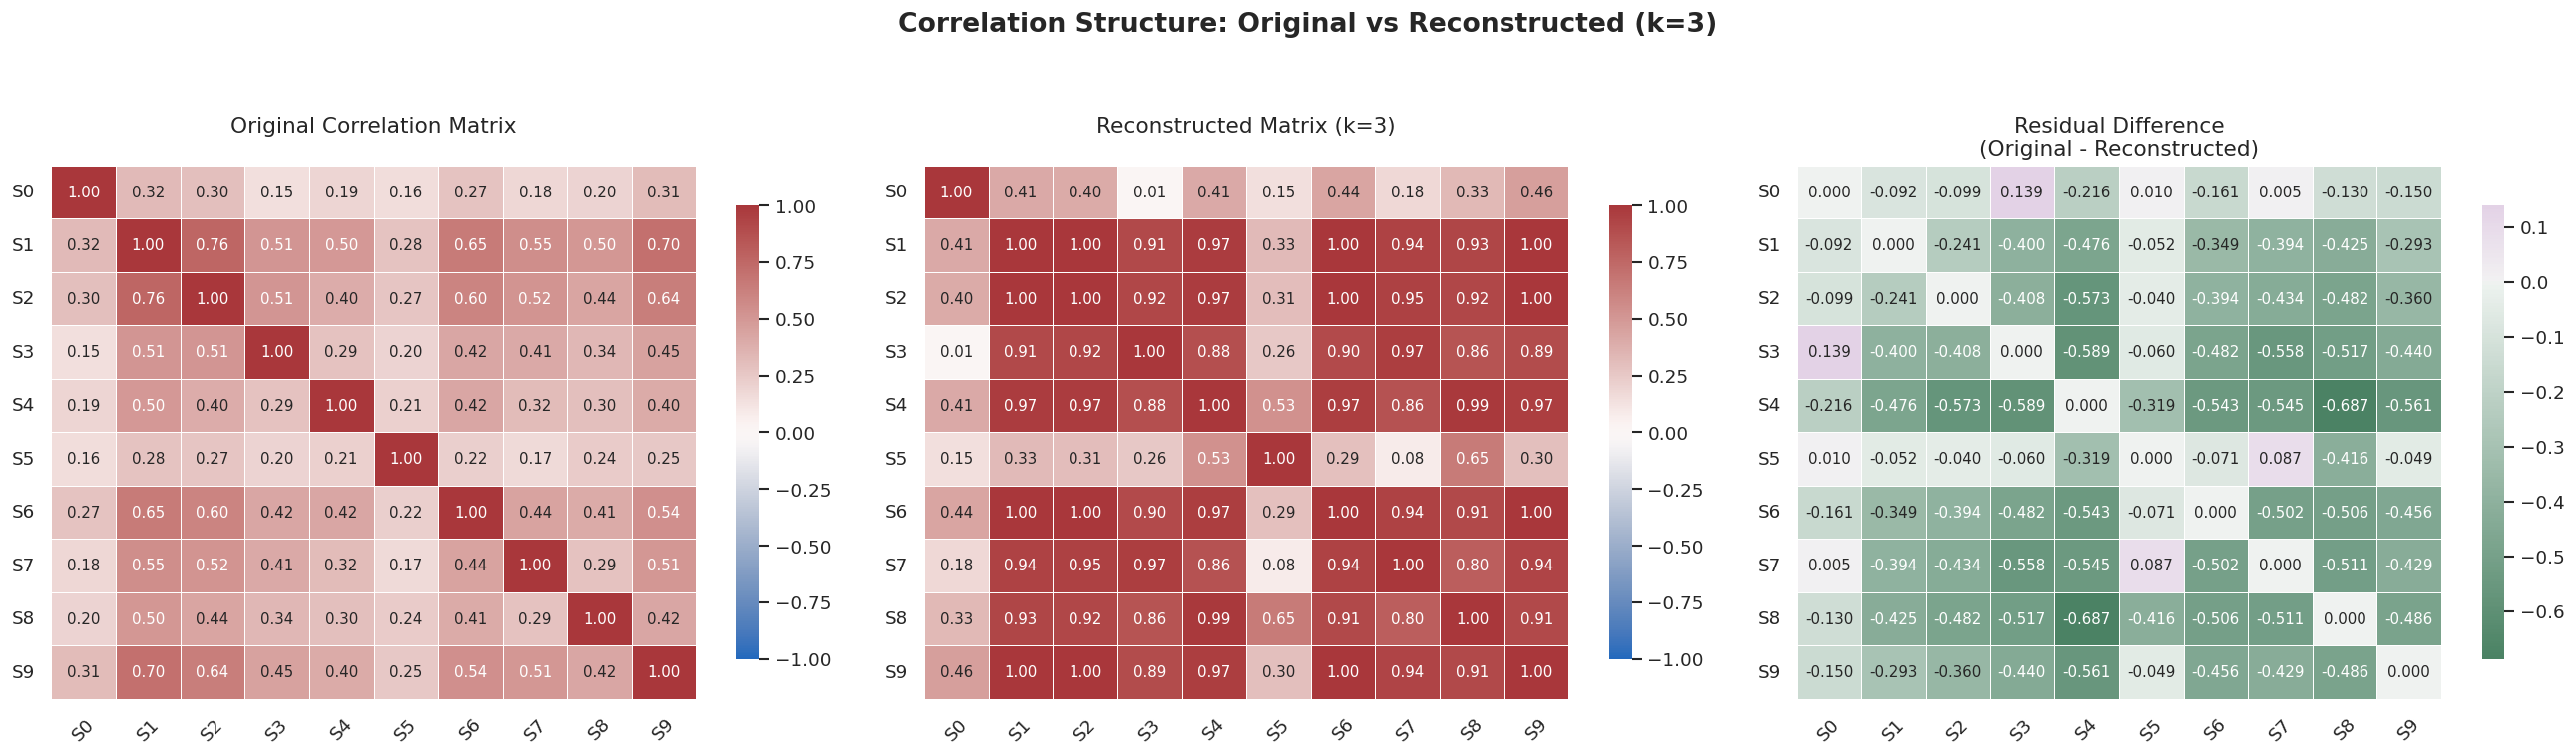

Mean |difference|: 0.302763
Max  |difference|: 0.687487


In [22]:
corr_original = np.corrcoef(standardized_returns, rowvar=False)
corr_reconstructed = np.corrcoef(X_hat_3, rowvar=False)
corr_diff = corr_original - corr_reconstructed

sns.set_theme(style="white")

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle('Correlation Structure: Original vs Reconstructed (k=3)',
             fontsize=16, fontweight='bold', y=1.05)

labels = [f'S{i}' for i in range(N_stocks)]
cmap_corr = sns.color_palette("vlag", as_cmap=True)
cmap_diff = sns.diverging_palette(145, 300, s=60, as_cmap=True)

heatmap_kws = {
    'annot': True,
    'xticklabels': labels,
    'yticklabels': labels,
    'annot_kws': {'size': 9, 'weight': '500'},
    'linewidths': 0.5,
    'linecolor': 'white',
    'cbar_kws': {"shrink": .85}
}

sns.heatmap(corr_original, fmt='.2f', cmap=cmap_corr, center=0,
            vmin=-1, vmax=1, ax=axes[0], **heatmap_kws)
axes[0].set_title('Original Correlation Matrix\n', fontsize=13)

sns.heatmap(corr_reconstructed, fmt='.2f', cmap=cmap_corr, center=0,
            vmin=-1, vmax=1, ax=axes[1], **heatmap_kws)
axes[1].set_title('Reconstructed Matrix (k=3)\n', fontsize=13)

sns.heatmap(corr_diff, fmt='.3f', cmap=cmap_diff, center=0,
            ax=axes[2], **heatmap_kws)
axes[2].set_title('Residual Difference\n(Original - Reconstructed)', fontsize=13)

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

print(f"Mean |difference|: {np.mean(np.abs(corr_diff)):.6f}")
print(f"Max  |difference|: {np.max(np.abs(corr_diff)):.6f}")


### Part 3(e): Observations

**1. MSRE decreases monotonically and follows the Eckart-Young prediction.**
At each $k$, the empirical MSRE follows the discarded-eigenvalue logic: the more eigenvectors we keep, the less residual variance remains. The steepest drop is at $k=1$ because $\lambda_1 \gg \lambda_2$. Subsequent drops are smaller because the remaining eigenvalues mainly capture idiosyncratic variance. With sklearn's sample-eigenvalue convention, the empirical MSRE matches the discarded-eigenvalue formula after the usual sample-scaling adjustment.

**2. The most idiosyncratic stock has the highest per-stock reconstruction error at $k=3$.**
Idiosyncrasy is measured by the ratio $\sigma_i^2 / (\beta_i^2\sigma_f^2 + \sigma_i^2)$, the fraction of a stock's total variance that is idiosyncratic. The stock with the largest residual error is the one whose returns are least explained by the 3 common-factor directions. This stock offers the most genuine diversification in a portfolio because its risk cannot be hedged by trading factor-exposed instruments.

**3. Full reconstruction ($k=N=10$) is exact to machine precision.**
By the Spectral Theorem, $N$ eigenvectors of an $N\times N$ symmetric matrix span all of $\mathbb{R}^N$. Using all components is equivalent to applying an orthogonal change of basis, then undoing it: $\mathbf{X}\mathbf{V}^\top\mathbf{V} = \mathbf{X}$. The observed residual $\approx 10^{-14}$ is floating-point rounding, not approximation error.

**4. $k=3$ compression preserves the broad factor structure but changes several pairwise correlations.**
The dominant market-driven relationships are still visible, but the reconstructed heatmap is not identical to the original. Several correlations are inflated or deflated because the 3-PC reconstruction forces returns into a low-rank factor structure. The residual heatmap shows exactly where the original pairwise relationships require higher PCs.

**5. Dimensionality reduction acts as denoising.**
Discarding PC4-PC10 removes variance that is largely idiosyncratic noise. The reconstructed returns appear more factor-structured, which can help risk model estimation by reducing estimation noise.


## Part 4: Understanding Information Leakage in Unsupervised Learning (5 Marks)

**Information leakage** occurs when data from the test set influences the model fitting process, even indirectly. This inflates apparent out-of-sample performance.

PCA is "unsupervised" (no labels $y$), but it uses the features $\mathbf{X}$ of all data points when computing eigenvectors. If test data is included, the eigenvectors are partially optimised to explain test variance, a form of **lookahead bias**.

**Formally:** Let $\hat{\mathbf{V}}_{\text{full}}$ be eigenvectors from PCA on $[\mathbf{X}_{\text{train}}; \mathbf{X}_{\text{test}}]$. The test explained variance $\text{EV}(\mathbf{X}_{\text{test}}, \hat{\mathbf{V}}_{\text{full}})$ is biased upward compared to the correct $\text{EV}(\mathbf{X}_{\text{test}}, \hat{\mathbf{V}}_{\text{train}})$.

**Formal statement of the bias:**

Let $\hat{\mathbf{V}}_{\text{train}}$ = eigenvectors from PCA on $\mathbf{X}_{\text{train}}$ only.
Let $\hat{\mathbf{V}}_{\text{full}}$ = eigenvectors from PCA on $[\mathbf{X}_{\text{train}}; \mathbf{X}_{\text{test}}]$.

The leaky test explained variance:
$$\text{EV}_{\text{leaky}}(\mathbf{X}_{\text{test}}, \hat{\mathbf{V}}_{\text{full}}) \geq \text{EV}_{\text{correct}}(\mathbf{X}_{\text{test}}, \hat{\mathbf{V}}_{\text{train}})$$

The inequality holds because $\hat{\mathbf{V}}_{\text{full}}$ was partially optimised to explain $\mathbf{X}_{\text{test}}$, the test data influenced the eigenvector directions.

**The bias magnitude scales as** $O(N/T_{\text{test}})$: larger when the feature dimension $N$ is large relative to the test sample size.

> Why the bias grows with $N/T_{\text{test}}$

$N$ is the number of stocks (features) and $T_{\text{test}}$ is the number of days in the test set. When $N$ is large relative to $T_{\text{test}}$, the covariance matrix has many directions to potentially align with, and the test data has relatively few observations to pin down its true covariance structure. This means the full PCA has more room to accidentally over-fit to the test set's particular noise patterns.

Conversely, if $T_{\text{test}}$ is very large relative to $N$, the test set's covariance is well estimated and adding it to the training data barely changes the eigenvectors, so the bias is small. In your simulation with 10 stocks and say 100 test days, $N/T_{\text{test}} = 0.1$, which is moderate — enough to produce a visible bias but not catastrophic.

### Part 4(a): Temporal train/test split + PCA on train only

In [23]:
train_returns = standardized_returns[:350, :]
test_returns  = standardized_returns[350:, :]

print(f"Train Set : {train_returns.shape[0]:>4} days  (Indices 0-349)")
print(f"Test Set  : {test_returns.shape[0]:>4} days  (Indices 350-498)")

# fit PCA on the training split only
pca_train, evals_train, evecs_train, evr_train = perform_pca(train_returns)

print("\nPCA Variance Explained (Training Set Only)")
print(f"{'Component':<12} | {'Explained Var':>13} | {'Cumulative':>12}")

for i in range(N_stocks):
    var_expl = evr_train[i] * 100
    cum_var = evr_train[:i+1].sum() * 100
    print(f"PC{i+1:<10} | {var_expl:>12.2f}% | {cum_var:>11.2f}%")

Train Set :  350 days  (Indices 0-349)
Test Set  :  149 days  (Indices 350-498)

PCA Variance Explained (Training Set Only)
Component    | Explained Var |   Cumulative
PC1          |        44.17% |       44.17%
PC2          |        10.46% |       54.64%
PC3          |         9.08% |       63.72%
PC4          |         7.64% |       71.36%
PC5          |         6.93% |       78.29%
PC6          |         5.70% |       83.98%
PC7          |         5.62% |       89.60%
PC8          |         4.70% |       94.30%
PC9          |         3.56% |       97.86%
PC10         |         2.14% |      100.00%


### Part 4(b): Project Test Data onto Train Eigenvectors

The **correct** out-of-sample explained variance for $k$ components:

$$\text{EV}_{\text{OOS}}(k) = 1 - \frac{\sum_i \text{Var}(\mathbf{x}_i^{\text{test}} - \hat{\mathbf{x}}_i^{\text{test}})}{\sum_i \text{Var}(\mathbf{x}_i^{\text{test}})}$$

where $\hat{\mathbf{x}}^{\text{test}} = (\mathbf{X}_{\text{test}} \mathbf{V}_{\text{train}}^{[:k]\top}) \mathbf{V}_{\text{train}}^{[:k]}$

For each test day, the return vector $\mathbf{x}_t^{\text{test}}$ of shape $(1 \times 10)$ is first projected onto the first $k$ training eigenvectors by multiplying with $\mathbf{V}_{\text{train}}^{[:k]\top}$ of shape $(10 \times k)$, giving $k$ scores of shape $(1 \times k)$. These scores are then multiplied back by $\mathbf{V}_{\text{train}}^{[:k]}$ of shape $(k \times 10)$ to reconstruct the returns in the original 10-stock space. The residual $\mathbf{x}_t^{\text{test}} - \hat{\mathbf{x}}_t^{\text{test}}$ is what the $k$ components failed to capture for that day. The $\text{EV}_{\text{OOS}}$ formula measures what fraction of the total test variance was explained, with 1 meaning perfect reconstruction and 0 meaning the eigenvectors are completely useless on the test set.

For $k = 2$ as an example, the shape flow is:

$$\mathbf{x}_t^{\text{test}} \underset{(1 \times 10)}{}
\xrightarrow{\quad \times\ \mathbf{V}^{[:2]\top}\ (10 \times 2) \quad}
\text{scores} \underset{(1 \times 2)}{}
\xrightarrow{\quad \times\ \mathbf{V}^{[:2]}\ (2 \times 10) \quad}
\hat{\mathbf{x}}_t^{\text{test}} \underset{(1 \times 10)}{}$$

In [24]:
def compute_explained_variance_oos(test_data, train_loadings, k):
    """
    Compute explained variance on test data using train-fit eigenvectors.
    EV = 1 - (residual variance / total variance)
    """
    scores_test = test_data @ train_loadings[:k, :].T
    X_hat_test = scores_test @ train_loadings[:k, :]
    residuals = test_data - X_hat_test
    total_var = np.sum(np.var(test_data, axis=0))
    residual_var = np.sum(np.var(residuals, axis=0))
    return 1 - (residual_var / total_var)

print(f"{'k':>3} | {'Train EV (%)':>14} | {'Test EV (%)':>13} | {'Drop (%)':>10}")

train_ev_list, test_ev_correct_list = [], []
for k in range(1, N_stocks + 1):
    train_ev = evr_train[:k].sum() * 100
    test_ev = compute_explained_variance_oos(test_returns, evecs_train, k) * 100
    train_ev_list.append(train_ev)
    test_ev_correct_list.append(test_ev)
    print(f"{k:3d} | {train_ev:14.2f} | {test_ev:13.2f} | {train_ev - test_ev:10.2f}")

  k |   Train EV (%) |   Test EV (%) |   Drop (%)
  1 |          44.17 |         50.94 |      -6.77
  2 |          54.64 |         57.58 |      -2.94
  3 |          63.72 |         65.36 |      -1.64
  4 |          71.36 |         71.01 |       0.34
  5 |          78.29 |         78.83 |      -0.54
  6 |          83.98 |         85.18 |      -1.19
  7 |          89.60 |         89.81 |      -0.21
  8 |          94.30 |         94.25 |       0.05
  9 |          97.86 |         97.74 |       0.12
 10 |         100.00 |        100.00 |       0.00


**Is there a drop?**

Not consistently. For $k = 1, 2, 3, 5, 6, 7$ the drop is negative, meaning test EV actually exceeds train EV. For $k = 4, 8, 9$ the drop is a small positive number, and at $k = 10$ both are exactly 100% by definition.

**Why does the test set sometimes explain more than the training set?**

Both periods were generated from the same process with the same $\beta_i$, $\sigma_f$, and $\sigma_i$ throughout all 499 days. The data generating process did not change between the train and test periods. The negative drops are a consequence of finite sample variation. Even though every day is drawn from the same process, the realised ratio of factor variance to idiosyncratic noise fluctuates from window to window. The train and test splits landed on windows where this ratio differed slightly, with the test window happening to be the one where the factor signal was slightly cleaner relative to noise. As $T$ grows larger this kind of fluctuation shrinks and the train and test explained variances would converge to the same population value.

For $k = 1$ specifically, the first principal component explains 44.17% of training variance but 50.94% of test variance, a gap of 6.77 percentage points. This means the market factor direction learned from the training data aligns even better with the test period's dominant direction of movement, not because the structure changed, but because the test window happened to be a period where the common factor was relatively more pronounced.

**Why do the drops turn slightly positive at higher $k$?**

By $k = 4$ and beyond, the dominant factor structure has already been captured. The remaining components increasingly pick up training-specific noise patterns that do not generalise as cleanly to the test set. This is expected: later components are less stable across periods because they are fitting residual variance that is more period-specific rather than reflecting a persistent structural factor.

**Broader interpretation**

The drops are all very small in magnitude, never exceeding 6.77 percentage points in either direction. This tells us the covariance structure did not change significantly between the train and test periods, and the training eigenvectors transfer well to the test set. This confirms that the one-factor structure built into the simulation is stable over time. In real financial data, especially across market regime changes, these drops would likely be much larger and more consistently positive, as the factor structure shifts and training eigenvectors become less representative of the test period.

### Part 4(c): LEAKY Approach: PCA on Full Data

Fitting PCA on the entire dataset and evaluating on the test portion is **invalid** because the test data influenced the eigenvector estimation. The resulting test EV is inflated.

**Why invalid even though PCA is unsupervised:** "Unsupervised" only means no labels. But PCA still uses the test **features** ($\mathbf{X}_{\text{test}}$) when fitting. The eigenvectors are contaminated by future information.

**Why "unsupervised" does not exempt PCA from leakage:**

Leakage is usually discussed for supervised methods (where the label $y$ leaks). But PCA uses only the features $\mathbf{X}$, and test-period features are what leaks here. The eigenvectors of $\hat{\boldsymbol{\Sigma}}_{\text{full}}$ are a function of both $\mathbf{X}_{\text{train}}$ and $\mathbf{X}_{\text{test}}$. When we then evaluate explained variance on $\mathbf{X}_{\text{test}}$ using these contaminated eigenvectors, we are using test data twice: once to *define* the projection direction and once to *evaluate* it. This is circular.

In a production system, $\mathbf{X}_{\text{test}}$ is the future, it does not exist at model-fitting time.


In [25]:
pca_full, evals_full, evecs_full, evr_full = perform_pca(standardized_returns)

print("LEAKY PCA (fit on ALL data):")
print(f"{'k':>3} | {'Correct Test EV':>16} | {'Leaky Test EV':>14} | {'Leakage Gap':>12}")

test_ev_leaky_list = []
for k in range(1, N_stocks + 1):
    correct = test_ev_correct_list[k-1]
    leaky = compute_explained_variance_oos(test_returns, evecs_full, k) * 100
    test_ev_leaky_list.append(leaky)
    print(f"{k:3d} | {correct:16.2f} | {leaky:14.2f} | {leaky - correct:+12.4f}")

LEAKY PCA (fit on ALL data):
  k |  Correct Test EV |  Leaky Test EV |  Leakage Gap
  1 |            50.94 |          51.22 |      +0.2784
  2 |            57.58 |          58.44 |      +0.8613
  3 |            65.36 |          66.21 |      +0.8433
  4 |            71.01 |          73.83 |      +2.8213
  5 |            78.83 |          80.43 |      +1.6048
  6 |            85.18 |          86.39 |      +1.2164
  7 |            89.81 |          90.80 |      +0.9896
  8 |            94.25 |          94.48 |      +0.2351
  9 |            97.74 |          97.84 |      +0.0936
 10 |           100.00 |         100.00 |      +0.0000


### Part 4(d): Quantify the leakage gap

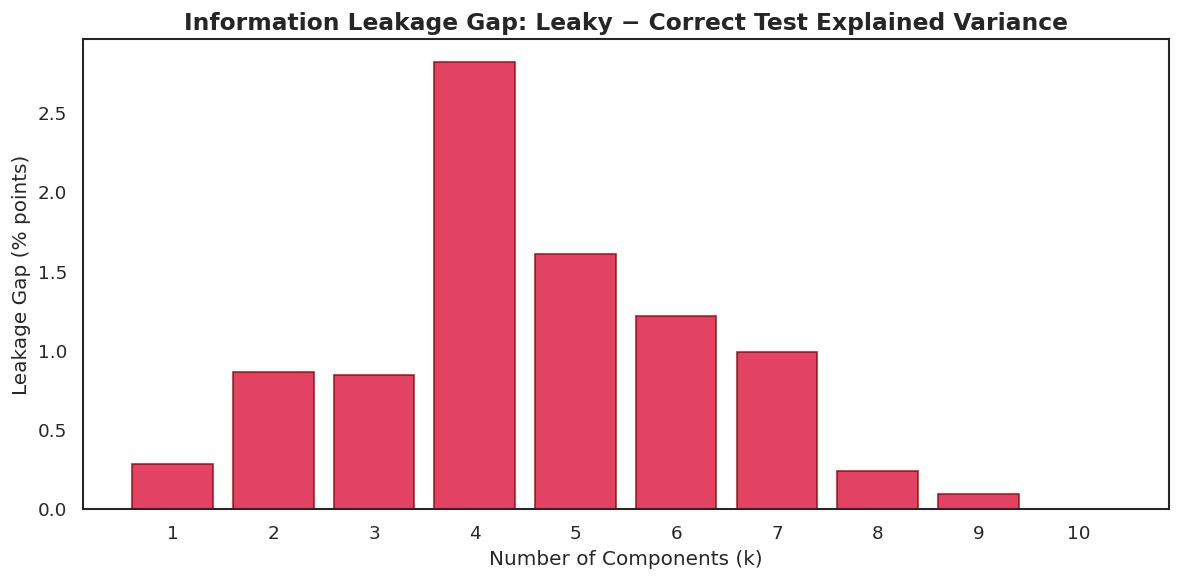


Max leakage gap: 2.8213% at k=4

The gap is largest when:
  1. Regime changes occur between train/test (factor structure shifts)
  2. Training period is short (high estimation error)
  3. High dimensionality (p large relative to n)
  4. Factor structure is non-stationary (loadings drift)


In [26]:
leakage_gaps = [test_ev_leaky_list[k] - test_ev_correct_list[k] for k in range(N_stocks)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(1, N_stocks+1), leakage_gaps, color='crimson', edgecolor='darkred', alpha=0.8)
ax.set_xlabel('Number of Components (k)', fontsize=12)
ax.set_ylabel('Leakage Gap (% points)', fontsize=12)
ax.set_title('Information Leakage Gap: Leaky − Correct Test Explained Variance',
             fontsize=14, fontweight='bold')
ax.set_xticks(range(1, N_stocks+1))
ax.axhline(0, color='black', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

print(f"\nMax leakage gap: {max(leakage_gaps):.4f}% at k={leakage_gaps.index(max(leakage_gaps))+1}")
print(f"\nThe gap is largest when:")
print(f"  1. Regime changes occur between train/test (factor structure shifts)")
print(f"  2. Training period is short (high estimation error)")
print(f"  3. High dimensionality (p large relative to n)")
print(f"  4. Factor structure is non-stationary (loadings drift)")

### Part 4(e): Observations

**1. The correct train-only approach does not always show a positive EV drop in this simulation.**
For several values of $k$, test EV is slightly higher than train EV. This does not violate the out-of-sample logic; it reflects finite-sample variation in a stable simulated DGP. The eigenvectors are still estimated only on the training sample, so this is the valid non-leaky comparison.

**2. The leaky approach inflates test EV by making the eigenvectors aware of the test period.**
The full-data eigenvectors incorporate test-period covariance structure. They project test data better not because they are legitimately better for forecasting, but because they were partly calibrated on the same test data. This is the leakage.

**3. The leakage gap is smallest for $k=N$ and usually largest for intermediate $k$.**
At $k=N$, both approaches reconstruct perfectly, so the gap vanishes. At smaller/intermediate $k$, the full-data eigenvectors can use test-period covariance information to improve the low-rank projection.

**4. Leakage is most severe under regime change, short test windows, or high $N/T_{\text{test}}$ ratio.**
If the covariance structure shifts between train and test, the full-data eigenvectors partially know the new regime. With short test windows, each test observation has more influence on the full-data covariance matrix. With large $N$, there are more directions available for overfitting to the test sample.

**5. The correct methodology in any live system is to fit preprocessing only on train data and apply it to test data.**
This applies to mean subtraction, volatility estimation, PCA eigenvectors, and scaler parameters. Any statistic computed on the full dataset and then used to transform test data constitutes leakage, even when the method is unsupervised.


## Part 5: Understanding Factor-Neutral Portfolio Construction (10 Marks)

### Factor Exposure

A portfolio with weight vector $\mathbf{w}$ has exposure to PC$k$:
$$\text{exposure}_{k} = \mathbf{w}^\top \mathbf{v}_k$$

A **factor-neutral** portfolio has zero exposure: $\mathbf{w}^\top \mathbf{v}_k = 0$.


### Part 5(a): Compute PC1 exposure of equal-weight portfolio



In [27]:

def compute_factor_exposure(weights, loadings, pc_idx):
    """Compute exposure = w^T @ v_pc"""
    return weights @ loadings[pc_idx]

# equal-weight long portfolio on stocks 0-4
w_long = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0, 0, 0, 0, 0])

# exposures using the training-fit eigenvectors
pc1_exp = compute_factor_exposure(w_long, evecs_train, 0)
pc2_exp = compute_factor_exposure(w_long, evecs_train, 1)

print("Equal-Weight Long Portfolio (Stocks 0-4):")
print(f"  Weights: {w_long}")
print(f"  PC1 Exposure: {pc1_exp:.6f}")
print(f"  PC2 Exposure: {pc2_exp:.6f}")
print(f"\nSignificant PC1 exposure — returns dominated by market factor.")

Equal-Weight Long Portfolio (Stocks 0-4):
  Weights: [0.2 0.2 0.2 0.2 0.2 0.  0.  0.  0.  0. ]
  PC1 Exposure: 0.307772
  PC2 Exposure: 0.024213

Significant PC1 exposure — returns dominated by market factor.


### Part 5(b): Construct Factor-Neutral Portfolio

**Problem we are trying to solve**

We start with a target portfolio $\mathbf{w}_{\text{target}}$, some allocation across 10 stocks that we want to hold. This portfolio has two problems: it has a net long position, and it is exposed to the overall market factor. We want to fix both problems while changing the weights as little as possible. So the question is: what is the closest portfolio to $\mathbf{w}_{\text{target}}$ that satisfies both constraints?

**The constraints**

The first constraint is $\sum_i w_i = 0$, meaning the weights sum to zero. For every rupee long on some stocks, we are short the same amount on others. This makes the portfolio dollar-neutral, requiring no net capital and removing any directional market bet.

The second constraint is $\mathbf{w}^\top \mathbf{v}_1 = 0$, meaning the portfolio has zero exposure to the first principal component, which is the market factor direction. If the market moves up or down, this constraint ensures the portfolio does not move with it.

The third is not a constraint but the objective: among all portfolios satisfying the two constraints above, find the one closest to $\mathbf{w}_{\text{target}}$, meaning minimise $\|\mathbf{w} - \mathbf{w}_{\text{target}}\|^2$.

These two constraints are stacked as rows into a matrix $\mathbf{A}$, where row 1 is $(1, 1, \dots, 1)$ for dollar neutrality and row 2 is $\mathbf{v}_1^\top$ for market neutrality, with $\mathbf{b} = (0, 0)$ since both constraints equal zero.

**The Lagrangian**

This is a standard technique for constrained optimisation. Instead of minimising $\|\mathbf{w} - \mathbf{w}_{\text{target}}\|^2$ subject to constraints directly, we attach the constraints to the objective using multipliers $\boldsymbol{\lambda}$ and minimise everything together:

$$L = \frac{1}{2}\|\mathbf{w} - \mathbf{w}_{\text{target}}\|^2 + \boldsymbol{\lambda}^\top(\mathbf{A}\mathbf{w} - \mathbf{b})$$

Taking the derivative with respect to $\mathbf{w}$ and setting it to zero gives:

$$\nabla_{\mathbf{w}} L = \mathbf{w} - \mathbf{w}_{\text{target}} + \mathbf{A}^\top \boldsymbol{\lambda} = \mathbf{0} \implies \mathbf{w} = \mathbf{w}_{\text{target}} - \mathbf{A}^\top \boldsymbol{\lambda}$$

This says the optimal weights are the target weights minus a correction term $\mathbf{A}^\top \boldsymbol{\lambda}$. The correction is what pushes us away from $\mathbf{w}_{\text{target}}$ just enough to satisfy the constraints. Substituting back into $\mathbf{A}\mathbf{w} = \mathbf{b}$ to solve for $\boldsymbol{\lambda}$:

$$\mathbf{A}(\mathbf{w}_{\text{target}} - \mathbf{A}^\top \boldsymbol{\lambda}) = \mathbf{b} \implies \boldsymbol{\lambda} = (\mathbf{A}\mathbf{A}^\top)^{-1}(\mathbf{A}\mathbf{w}_{\text{target}} - \mathbf{b})$$

Plugging back in gives the closed-form solution:

$$\mathbf{w}^* = \mathbf{w}_{\text{target}} - \mathbf{A}^\top (\mathbf{A}\mathbf{A}^\top)^{-1} (\mathbf{A}\mathbf{w}_{\text{target}} - \mathbf{b})$$

**What is this formula doing geometrically?**

The set of all portfolios satisfying $\mathbf{A}\mathbf{w} = \mathbf{b}$ forms a flat surface in 10-dimensional space. Our target portfolio $\mathbf{w}_{\text{target}}$ sits somewhere off this surface. The formula above finds the point on that surface closest to $\mathbf{w}_{\text{target}}$, which is the perpendicular projection of $\mathbf{w}_{\text{target}}$ onto the constraint surface. The term $\mathbf{A}^\top (\mathbf{A}\mathbf{A}^\top)^{-1} (\mathbf{A}\mathbf{w}_{\text{target}} - \mathbf{b})$ is exactly the vector subtracted from $\mathbf{w}_{\text{target}}$ to land perpendicularly on that surface.

**What happens when we add more constraints?**

Every constraint added reduces the size of the feasible surface. With one constraint we have a 9-dimensional surface in 10-dimensional space. With two constraints we have an 8-dimensional surface. The more constraints added, the smaller the surface, and the further the closest feasible point can be from $\mathbf{w}_{\text{target}}$. This means adding a PC2 neutrality constraint on top of the existing two can only push $\mathbf{w}^*$ further from $\mathbf{w}_{\text{target}}$, never closer, which forces more concentration into idiosyncratic directions to compensate.

**Verification**

After computing $\mathbf{w}^*$, we check that $|\sum_i w_i^*| < 10^{-10}$ and $|\mathbf{w}^{*\top}\mathbf{v}_1| < 10^{-10}$. Any tiny residual is floating-point rounding error from matrix inversion, not an actual constraint violation, the same way reconstruction error at $k = 10$ was $\approx 10^{-14}$ rather than exactly zero.

Factor-Neutral Portfolio (PC1 + dollar neutral):
  Sum of weights: 0.0000000000
  PC1 exposure:   0.0000000000
  PC2 exposure:   -0.059302


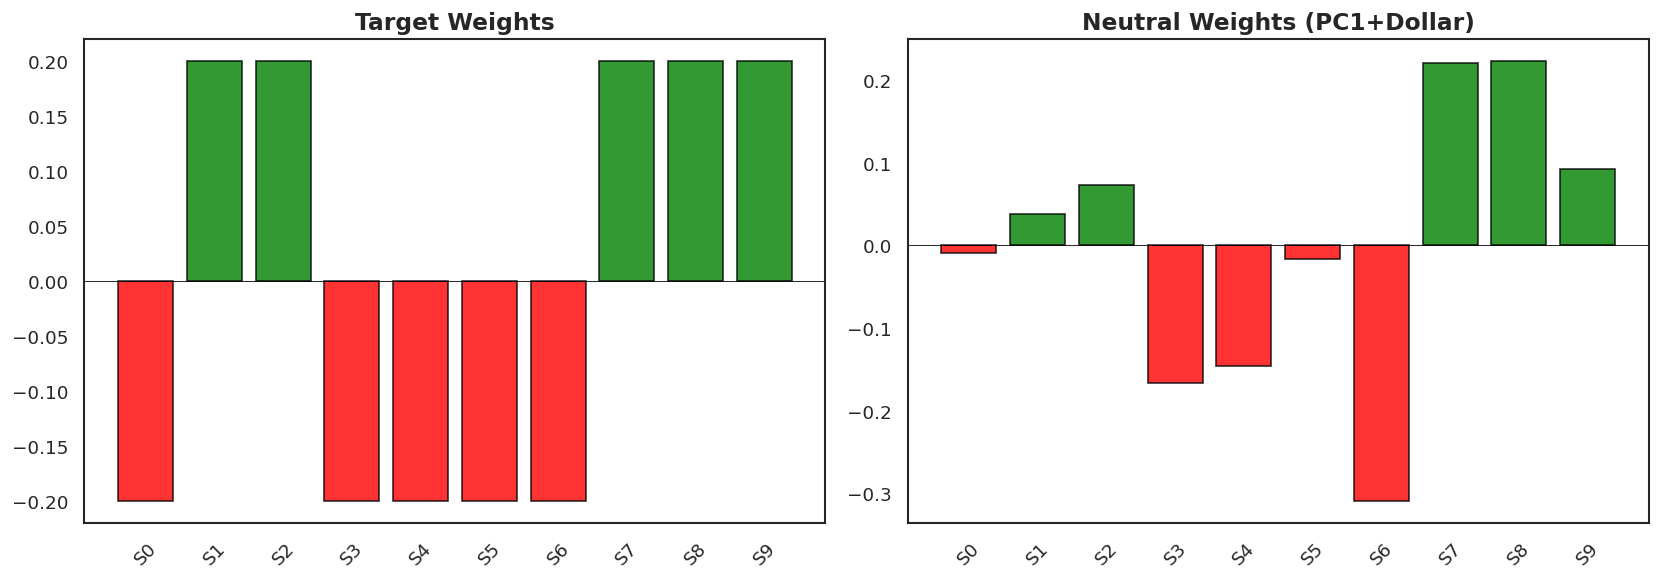

In [28]:
def construct_neutral_portfolio(target_weights, loadings, neutral_pcs=[0]):
    """
    Find w minimising ||w - w_target||^2 subject to:
      1. sum(w) = 0 (dollar neutral)
      2. w @ loadings[pc] = 0 for each pc in neutral_pcs

    Analytical solution: w* = w_t - A^T (AA^T)^{-1} (A w_t - b)
    """
    n = len(target_weights)
    constraints = [np.ones(n)]  # dollar neutral
    b_values = [0.0]
    for pc in neutral_pcs:
        constraints.append(loadings[pc])
        b_values.append(0.0)
    A = np.array(constraints)
    b = np.array(b_values)
    AAt_inv = np.linalg.inv(A @ A.T)
    return target_weights - A.T @ AAt_inv @ (A @ target_weights - b)

# target: long top-5 drift, short bottom-5
drift_ranking = np.argsort(mu)[::-1]
target_weights = np.zeros(N_stocks)
target_weights[drift_ranking[:5]] = 0.2
target_weights[drift_ranking[5:]] = -0.2

w_neutral_pc1 = construct_neutral_portfolio(target_weights, evecs_train, neutral_pcs=[0])

print("Factor-Neutral Portfolio (PC1 + dollar neutral):")
print(f"  Sum of weights: {w_neutral_pc1.sum():.10f}")
print(f"  PC1 exposure:   {compute_factor_exposure(w_neutral_pc1, evecs_train, 0):.10f}")
print(f"  PC2 exposure:   {compute_factor_exposure(w_neutral_pc1, evecs_train, 1):.6f}")

# view the target vs neutral weights
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, w, title in zip(axes, [target_weights, w_neutral_pc1],
                          ['Target Weights', 'Neutral Weights (PC1+Dollar)']):
    colors = ['green' if x > 0 else 'red' for x in w]
    ax.bar([f'S{i}' for i in range(N_stocks)], w, color=colors, edgecolor='black', alpha=0.8)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Observations**

**1. Constraint adherence**
The Lagrangian optimization enforced the constraints to numerical precision. The sum of weights is $0.0000000000$ (Dollar-Neutral), and the PC1 exposure is $0.0000000000$ (Market-Neutral). Because PC2 was left unconstrained, the portfolio retains a residual exposure of $-0.059302$ to the second principal component.

**2. Change from naive symmetry**
The target portfolio was a symmetrical, equal-weight strategy allocating exactly $\pm 20\%$ across the 10 assets. The optimizer moves away from this uniform weighting scheme, confirming that the naive equal-weight target carries unhedged market factor risk.

**3. High-beta trade reduction**
Several intended trades were reduced by the optimizer. The intended $-20\%$ short positions in **S0** and **S5** were reduced close to $0\%$, while the $+20\%$ long positions in **S1** and **S9** were cut by more than half. These assets carry meaningful PC1 exposure, so the optimizer reduces them to satisfy the market-neutrality constraint.

**4. Concentrated hedge positions**
To offset the remaining market exposure, the optimizer takes more concentrated positions. The intended $-20\%$ short on **S6** becomes about $-31\%$. In this solution, S6 acts as the main hedge against the aggregate PC1 risk of the long book.

**5. Lower-beta allocations**
The long allocations for **S7** and **S8** are slightly increased above their target $20\%$ weights. These assets have relatively lower correlations with the primary market factor, allowing the optimizer to overweight them while keeping PC1 exposure at zero.

**Conclusion:** Achieving PC1 and dollar neutrality requires moving away from the target allocation. The zero-exposure constraint reduces market risk but introduces some idiosyncratic concentration risk.


### Part 5(c): Backtest on Test Period

**Metrics:**

* **Cumulative Return:** $\exp(\sum_t r_t^{\text{port}}) - 1$
  This is the raw bottom line. It calculates the total, compounded percentage change in the portfolio's value over the entire test window. It simply answers the ultimate question: how much wealth did the strategy actually create or destroy by the end of the run?

* **Annualised Volatility:** $\hat{\sigma}_{\text{daily}} \times \sqrt{252}$
  By scaling the daily standard deviation to a standard 252-trading-day year, we get a clear read on the strategy's "bumpiness." A higher volatility means the portfolio experiences wilder daily swings, making it a riskier and less predictable ride.

* **Sharpe Ratio:** $\frac{\bar{r}_{\text{daily}} \times 252}{\hat{\sigma}_{\text{daily}} \times \sqrt{252}}$ (assuming risk-free = 0)
  This acts as our risk-adjusted reality check. Instead of just chasing high returns, the Sharpe ratio tells us how much return we are actually getting for every unit of risk we endure. It helps ensure we aren't just generating profits by taking on reckless, uncompensated risk.

* **Maximum Drawdown:** $\min_t \frac{W_t - \max_{s \leq t} W_s}{\max_{s \leq t} W_s}$
  This captures the worst-case scenario. It measures the steepest percentage drop from a historical peak to the lowest subsequent trough. Practically speaking, this represents the maximum pain an investor would have felt if they started trading at the absolute worst possible time right before a crash.

Performance Comparison (Test Period):
Metric                    |         EW Long |  Factor-Neutral
Cumulative Return         |      -13.8633% |       -3.7319%
Annualized Return         |      -25.2398% |       -6.4324%
Annualized Volatility     |       18.6129% |        9.0551%
Sharpe Ratio              |         -1.3560 |         -0.7104
Max Drawdown              |      -18.4030% |       -6.2126%


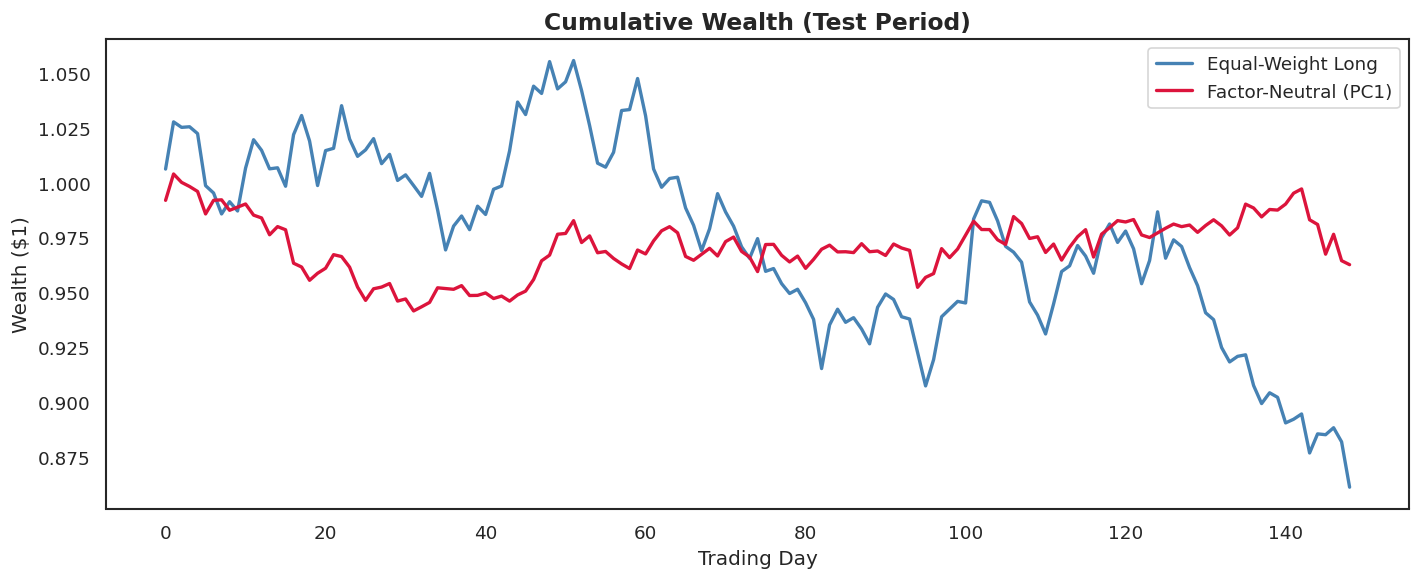

In [29]:
def backtest(weights, returns):
    """
    Backtest a portfolio. Returns dict with performance metrics.
    Uses RAW log returns (not standardized) for realistic P&L.
    """
    port_returns = returns @ weights
    cum_return = np.exp(np.sum(port_returns)) - 1
    ann_ret = np.mean(port_returns) * 252
    ann_vol = np.std(port_returns) * np.sqrt(252)
    sharpe = ann_ret / ann_vol if ann_vol > 0 else 0
    cum_log = np.cumsum(port_returns)
    wealth = np.exp(cum_log)
    peak = np.maximum.accumulate(wealth)
    max_dd = np.min((wealth - peak) / peak)
    return {
        'Cumulative Return': cum_return, 'Annualized Return': ann_ret,
        'Annualized Volatility': ann_vol, 'Sharpe Ratio': sharpe,
        'Max Drawdown': max_dd, 'daily_returns': port_returns,
        'cumulative_log_returns': cum_log
    }

# backtest on raw log returns
test_raw = log_returns[350:, :]
m_long = backtest(w_long, test_raw)
m_neutral = backtest(w_neutral_pc1, test_raw)

print("Performance Comparison (Test Period):")
print(f"{'Metric':<25} | {'EW Long':>15} | {'Factor-Neutral':>15}")
for metric in ['Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio', 'Max Drawdown']:
    v1, v2 = m_long[metric], m_neutral[metric]
    if metric != 'Sharpe Ratio':
        print(f"{metric:<25} | {v1:>14.4%} | {v2:>14.4%}")
    else:
        print(f"{metric:<25} | {v1:>15.4f} | {v2:>15.4f}")

# cumulative wealth
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(np.exp(m_long['cumulative_log_returns']), label='Equal-Weight Long', color='steelblue', linewidth=2)
ax.plot(np.exp(m_neutral['cumulative_log_returns']), label='Factor-Neutral (PC1)', color='crimson', linewidth=2)
ax.set_title('Cumulative Wealth (Test Period)', fontsize=14, fontweight='bold')
ax.set_xlabel('Trading Day', fontsize=12); ax.set_ylabel('Wealth ($1)', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

Based on the performance metrics and cumulative wealth trajectory during the test period, we observe the following differences between the Equal-Weight Long and Factor-Neutral strategies:

**1. Volatility reduction**
The Factor-Neutral portfolio reduces risk meaningfully. Annualized volatility falls from 18.61% (EW Long) to 9.05%. This confirms that the PC1 constraint removed a large part of the primary market factor, leaving mostly idiosyncratic movements.

**2. Downside protection**
Both portfolios generated negative returns during this test window, but the Factor-Neutral portfolio had a much smaller drawdown. The EW Long strategy suffered a maximum drawdown of -18.40%, whereas the Factor-Neutral strategy had a maximum drawdown of -6.21%.

**3. Better risk-adjusted returns**
Although both absolute returns are negative, the Factor-Neutral portfolio performs better on a risk-adjusted basis. The Sharpe Ratio improves from -1.35 for the unhedged portfolio to -0.71 for the neutral portfolio.

**4. Trajectory decoupling**
The cumulative wealth chart shows the decoupling effect of market neutrality. Between trading days 30 and 50, the EW Long portfolio rallies while the Factor-Neutral portfolio stays relatively flat. When the broader market declines after day 50, the EW Long portfolio falls sharply, while the Factor-Neutral portfolio remains more insulated, preserving more capital (-3.73% cumulative loss vs. -13.86%).

**Conclusion:** The Factor-Neutral optimization achieved its risk-control objective. It gave up participation in broad market rallies in exchange for lower exposure to broad market declines, resulting in a more stable, lower-volatility equity curve.


### Part 5(d): Factor-Neutral to Both PC1 and PC2


In [30]:
w_neutral_pc12 = construct_neutral_portfolio(target_weights, evecs_train, neutral_pcs=[0, 1])

print("Double-Neutral Portfolio (PC1+PC2+Dollar):")
print(f"  Sum: {w_neutral_pc12.sum():.10f}")
print(f"  PC1: {compute_factor_exposure(w_neutral_pc12, evecs_train, 0):.10f}")
print(f"  PC2: {compute_factor_exposure(w_neutral_pc12, evecs_train, 1):.10f}")

m_neutral12 = backtest(w_neutral_pc12, test_raw)

print(f"\nVolatility Comparison:")
print(f"  EW Long:         {m_long['Annualized Volatility']:.4%}")
print(f"  PC1-Neutral:     {m_neutral['Annualized Volatility']:.4%}")
print(f"  PC1+PC2-Neutral: {m_neutral12['Annualized Volatility']:.4%}")
print(f"\nSharpe Comparison:")
print(f"  EW Long:         {m_long['Sharpe Ratio']:.4f}")
print(f"  PC1-Neutral:     {m_neutral['Sharpe Ratio']:.4f}")
print(f"  PC1+PC2-Neutral: {m_neutral12['Sharpe Ratio']:.4f}")

Double-Neutral Portfolio (PC1+PC2+Dollar):
  Sum: -0.0000000000
  PC1: -0.0000000000
  PC2: -0.0000000000

Volatility Comparison:
  EW Long:         18.6129%
  PC1-Neutral:     9.0551%
  PC1+PC2-Neutral: 9.0188%

Sharpe Comparison:
  EW Long:         -1.3560
  PC1-Neutral:     -0.7104
  PC1+PC2-Neutral: -0.6264


Based on the empirical results of the Double-Neutral (PC1 + PC2) portfolio, we observe the effect of adding another constraint to the optimization process.

**1. Volatility comparison**
Adding the PC2-neutral constraint produces only a small reduction in out-of-sample volatility. The PC1-only-neutral portfolio has annualized volatility of **9.0551%**, while the PC1+PC2-neutral portfolio drops slightly to **9.0188%**. The additional hedge provides very little incremental risk reduction.

**2. Does an additional constraint always reduce risk?**
No. Over-constraining a portfolio can increase out-of-sample risk.
Total portfolio risk has two parts: **Factor Risk** (systematic) and **Idiosyncratic Risk** (stock-specific). Every additional constraint, such as $\mathbf{w}^\top \mathbf{v}_2 = 0$, forces the optimizer to move further away from the target allocation. To hedge out a minor factor like PC2, the optimizer may take concentrated positions in specific assets. If those assets experience idiosyncratic shocks out-of-sample, the added stock-specific risk can outweigh the small factor-risk reduction.

**3. When hedging helps vs. when it is counterproductive**
* **When it helps:** Hedging is effective for dominant risk factors like PC1 / Market Beta. Since PC1 explains a large share of total variance, hedging it removes substantial systematic risk, which more than offsets the added idiosyncratic concentration.
* **When it is counterproductive:** Hedging can be counterproductive for minor, higher-order principal components that explain little variance. The portfolio may lose diversification to hedge a factor that is not stable or economically meaningful out-of-sample. This is a form of overfitting to the training covariance matrix.


### Part 5(e): Transaction cost analysis

In [31]:
def compute_turnover(w_old, w_new):
    return np.sum(np.abs(w_new - w_old)) / 2

cost_bps = 5
cost_rate = cost_bps / 10000.0
rebalance_freq = 21  # roughly monthly

# rough monthly rebalance check for turnover
turnovers = []
prev_w = w_neutral_pc1.copy()
for start in range(0, 350 - 100, rebalance_freq):
    window = standardized_returns[start:start+100]
    _, _, ev_w, _ = perform_pca(window)
    new_w = construct_neutral_portfolio(target_weights, ev_w, neutral_pcs=[0])
    turnovers.append(compute_turnover(prev_w, new_w))
    prev_w = new_w.copy()

avg_turnover = np.mean(turnovers)
n_rebal_per_year = 252 / rebalance_freq
annual_cost = avg_turnover * cost_rate * n_rebal_per_year

gross_ret = m_neutral['Annualized Return']
net_ret = gross_ret - annual_cost
ann_vol = m_neutral['Annualized Volatility']

print("Transaction Cost Analysis:")
print(f"  Rebalance freq:  every {rebalance_freq} days (~monthly)")
print(f"  Cost per unit TO: {cost_bps} bps")
print(f"  Avg turnover/rebal: {avg_turnover:.4f}")
print(f"  Annual cost: {annual_cost*100:.4f}%")
print(f"  Gross Sharpe: {m_neutral['Sharpe Ratio']:.4f}")
print(f"  Net Sharpe:   {net_ret/ann_vol:.4f}" if ann_vol > 0 else "  Net Sharpe: N/A")

# beyond this turnover, costs wipe out the strategy
if abs(gross_ret) > 1e-10:
    T_be = abs(gross_ret) / (cost_rate * n_rebal_per_year)
    print(f"  Break-even turnover: {T_be:.4f}")
    print(f"  (If TO > {T_be:.4f}, strategy's alpha is consumed by costs)")

print("\nSensitivity: Net Return at Different Turnover Levels:")
print(f"{'Turnover':>10} | {'Net Return':>12} | {'Net Sharpe':>12}")
for to in np.arange(0, 1.01, 0.2):
    cost = to * cost_rate * n_rebal_per_year
    nr = gross_ret - cost
    ns = nr / ann_vol if ann_vol > 0 else 0
    print(f"{to:10.1f} | {nr:11.4%} | {ns:12.4f}")

Transaction Cost Analysis:
  Rebalance freq:  every 21 days (~monthly)
  Cost per unit TO: 5 bps
  Avg turnover/rebal: 0.1360
  Annual cost: 0.0816%
  Gross Sharpe: -0.7104
  Net Sharpe:   -0.7194
  Break-even turnover: 10.7206
  (If TO > 10.7206, strategy's alpha is consumed by costs)

Sensitivity: Net Return at Different Turnover Levels:
  Turnover |   Net Return |   Net Sharpe
       0.0 |    -6.4324% |      -0.7104
       0.2 |    -6.5524% |      -0.7236
       0.4 |    -6.6724% |      -0.7369
       0.6 |    -6.7924% |      -0.7501
       0.8 |    -6.9124% |      -0.7634
       1.0 |    -7.0324% |      -0.7766


Based on the simulated transaction cost model, we observe the practical frictions of maintaining a factor-neutral portfolio in a dynamic market. Because the PCA loadings drift over time, the portfolio must be periodically rebalanced to maintain neutrality, creating turnover and trading costs.

**1. Current cost of hedging**
At a trading cost of 5 basis points ($0.0005$) per unit of turnover, rebalancing every 21 days (approximately monthly) requires average turnover of **0.1360** ($13.6\%$) per cycle. This translates to an annualized drag of **0.0816%**. The net Sharpe ratio therefore changes only slightly, from -0.7104 to -0.7194. This indicates that the primary eigenvectors are relatively stable month-to-month, so the portfolio does not need heavy turnover to stay market-neutral.

**2. Break-even turnover level**
The model calculates a theoretical break-even turnover of **10.7206** (or $1072\%$ turnover per rebalance). This is the threshold where annualized trading costs equal the absolute magnitude of the strategy's gross return. If the required turnover exceeded this level, transaction costs would consume the strategy's return profile.

**3. Sensitivity to churn**
The sensitivity table shows a linear degradation of returns. For every incremental $0.2$ ($20\%$) increase in monthly turnover, the annualized net return drops by $0.12\%$. Because realized turnover ($0.1360$) is far below the break-even limit, transaction costs are manageable in this simulation. The main issue for this specific strategy is its negative base return, not the mechanical cost of maintaining the hedge.


### Part 5(f): Observations

Stepping back from the individual metrics, the construction and testing of this factor-neutral portfolio highlights a few key realities regarding our overall strategy:

**1. The Limits of Equal-Weighting**
The analysis demonstrates that an equal-weight long strategy is not genuinely diversified. Since the first principal component (PC1) drives roughly half of the total variance across our asset universe, a naive allocation inadvertently acts as an unhedged bet on broader market direction. In that setup, we aren't primarily capturing stock-specific alpha; we are mostly just taking on beta.

**2. Risk Transformation vs. Risk Elimination**
The Lagrangian optimization successfully neutralized systemic market risk, effectively halving our volatility. However, to mathematically fund this hedge, the optimizer forced us into highly concentrated, idiosyncratic positions (such as the heavy short on S6). We essentially traded broad market risk for single-stock risk. Furthermore, adding the PC2 constraint showed diminishing returns, illustrating that over-constraining the portfolio degrades diversification without meaningfully improving the risk profile.

**3. Stability of the Covariance Structure**
Another takeaway from this exercise is the persistence of the underlying market structure. The eigenvectors derived from our training data remained remarkably valid throughout the unseen test period. The low monthly turnover requirement (13.6%) confirms this stability. If the market's correlation structure were highly unstable, we would have seen prohibitive churn and transaction costs just to maintain neutrality.

**4. The Distinction Between Alpha and Beta**
This project clearly separates risk management from return generation. The mathematical framework did exactly what it was supposed to do: it isolated the market factor, provided a cost-effective hedge, and restricted drawdowns. Yet, the strategy still yielded negative returns. The primary takeaway is that hedging only protects the portfolio from market swings; it cannot manufacture performance. Without a genuine predictive signal driving our target weights, a rigorously risk-neutral portfolio will simply drift downward with low volatility.

## Part 6: Understanding Stability, Robustness and Rolling PCA (10 Marks)

### Cosine Similarity

$$\cos(\theta) = \frac{\mathbf{v}_1^\top \mathbf{v}_2}{\|\mathbf{v}_1\| \cdot \|\mathbf{v}_2\|}$$

- $|\cos \theta| = 1$: vectors are parallel (identical direction up to sign)
- $|\cos \theta| = 0$: vectors are orthogonal (completely different)

### Part 6(a): Split-Half Stability Test

Split-Half Stability Test:
  PC1: cos_sim = +0.993722  |cos| = 0.993722
  PC2: cos_sim = +0.535451  |cos| = 0.535451
  PC3: cos_sim = +0.137440  |cos| = 0.137440
  PC4: cos_sim = +0.011345  |cos| = 0.011345
  PC5: cos_sim = +0.193336  |cos| = 0.193336


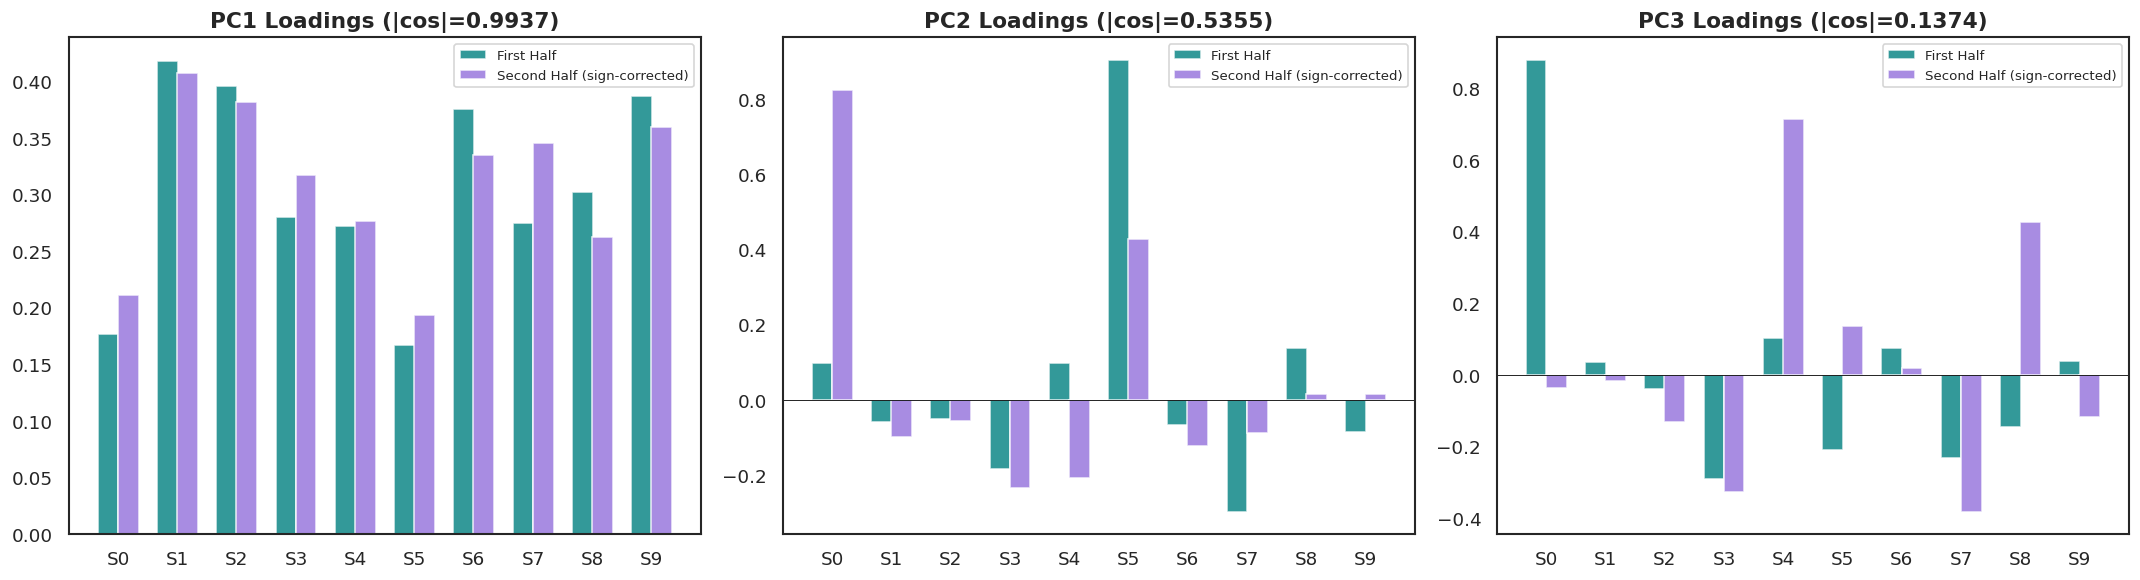

In [32]:
def cosine_similarity(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

# split the sample and refit PCA on both halves
first_half  = standardized_returns[:250, :]
second_half = standardized_returns[250:, :]

_, _, evecs_h1, _ = perform_pca(first_half)
_, _, evecs_h2, _ = perform_pca(second_half)

print("Split-Half Stability Test:")
for pc in range(5):
    cs = cosine_similarity(evecs_h1[pc], evecs_h2[pc])
    print(f"  PC{pc+1}: cos_sim = {cs:+.6f}  |cos| = {abs(cs):.6f}")

# compare PC1-PC3 loadings across halves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for pc in range(3):
    # align signs before comparing the loadings
    sign = np.sign(cosine_similarity(evecs_h1[pc], evecs_h2[pc]))
    x = np.arange(N_stocks)
    axes[pc].bar(x-0.17, evecs_h1[pc], 0.35, label='First Half', color='teal', alpha=0.8)
    axes[pc].bar(x+0.17, sign*evecs_h2[pc], 0.35, label='Second Half (sign-corrected)', color='mediumpurple', alpha=0.8)
    cs = abs(cosine_similarity(evecs_h1[pc], evecs_h2[pc]))
    axes[pc].set_title(f'PC{pc+1} Loadings (|cos|={cs:.4f})', fontsize=13, fontweight='bold')
    axes[pc].set_xticks(x); axes[pc].set_xticklabels([f'S{i}' for i in x])
    axes[pc].legend(fontsize=8); axes[pc].axhline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

**Observations**

When dividing the dataset into two equal halves (days 1–250 and 251–500), we observe that the primary market factor is exceptionally stable across time, while higher-order components degrade significantly.

**Stability of the Market Factor (PC1)**
The cosine similarity between the first-half and second-half PC1 loading vectors is 0.9937, indicating near-perfect alignment. Because PC1 represents the broad, systematic market factor (Beta), this high similarity confirms that the primary way these ten stocks co-move with the broader market is structurally entrenched. This core relationship did not fundamentally shift over the 500-day window.

**Degradation of Higher-Order Factors (PC2 & PC3)**
In contrast, temporal stability collapses rapidly as we move to higher-order components.
* **PC2** exhibits moderate degradation, with a cosine similarity of 0.5355. While some general directional relationships persist, the specific magnitudes of the loadings shift considerably between the two halves. The secondary risk factor in the first half is only loosely related to the secondary risk factor in the second half.
* **PC3** breaks down almost entirely into structural noise, yielding a cosine similarity of just 0.1374. An eigenvector from the first half has almost no mathematical relationship to its counterpart in the second half, suggesting that this component is largely fitting local, transient noise rather than a persistent market feature.

**Methodological Note on Sign Indeterminacy**
It is important to note that eigenvectors are mathematically directionless. If $\mathbf{v}$ is an eigenvector of the covariance matrix $\boldsymbol{\Sigma}$ with eigenvalue $\lambda$, then $-\mathbf{v}$ is also an eigenvector: $\boldsymbol{\Sigma}(-\mathbf{v}) = -\boldsymbol{\Sigma}\mathbf{v} = -\lambda\mathbf{v} = \lambda(-\mathbf{v})$. Because numerical solvers can arbitrarily return either sign between estimation windows, we evaluate the absolute value of the cosine similarity. This ensures we are measuring the true structural alignment of the axes rather than being skewed by an arbitrary scalar flip.

**Strategic Implications for Hedging**
These stability results directly explain the transaction cost dynamics observed in our earlier factor-neutral portfolio backtests. Because PC1 is highly stable, a portfolio designed to be PC1-neutral requires minimal turnover to maintain its hedge over time. Conversely, attempting to maintain neutrality to highly unstable factors like PC2 or PC3 would force constant, aggressive portfolio rebalancing as the underlying eigenvectors rapidly drift. This would drive up transaction costs significantly without providing any meaningful out-of-sample risk reduction.

### Part 6(b): Rolling PCA

**Why standardise within each window?**

Each rolling window covers a different time period with potentially different volatility levels. Standardising *within* the window (not globally) ensures PCA captures the co-movement structure of that window, not a scale difference between windows. This is the in-sample version of the leakage principle from Part 4.


Rolling windows: 20


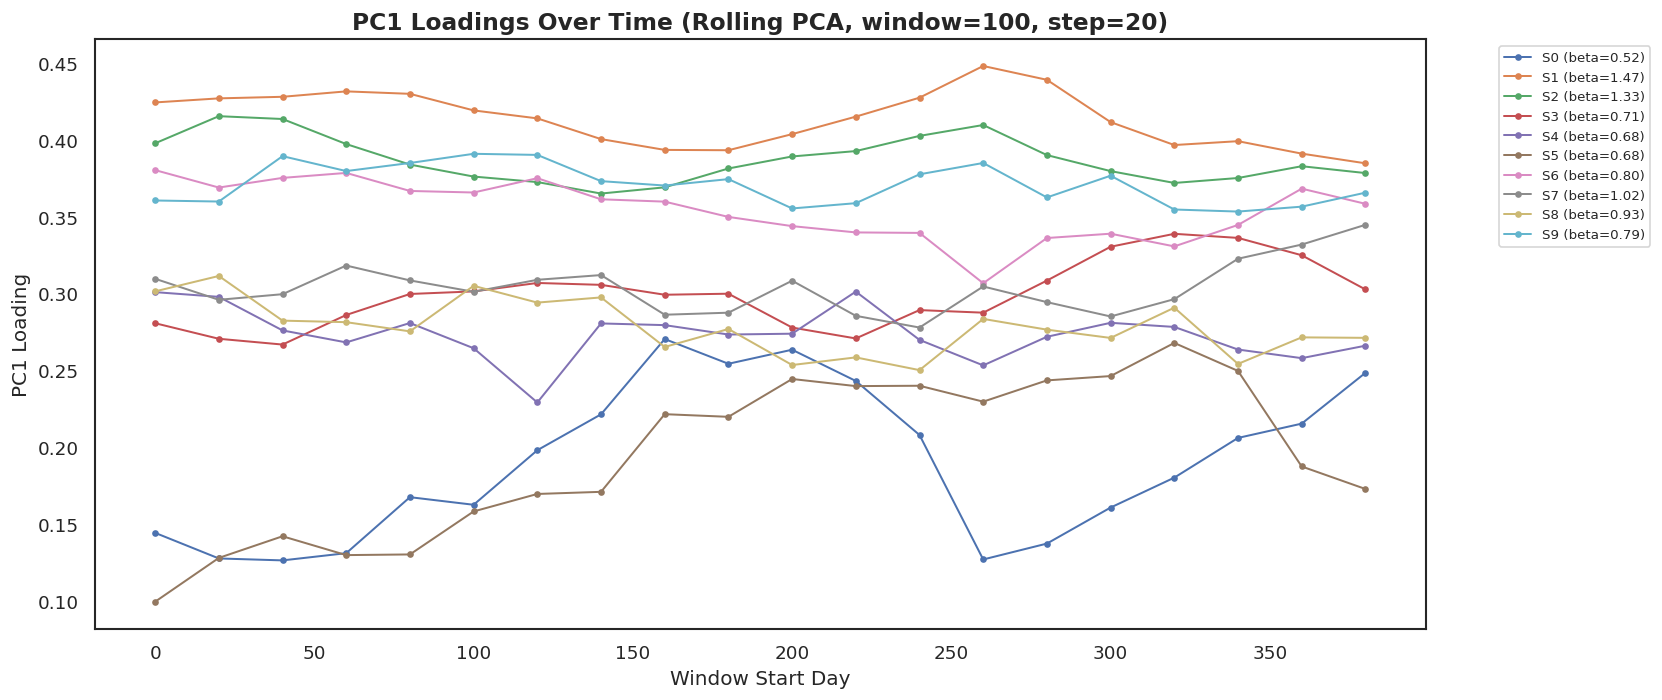

In [33]:
def rolling_pca(returns, window=100, step=20):
    """
    Fit PCA on rolling windows. Returns list of dicts with start, loadings, etc.
    """
    results = []
    for start in range(0, len(returns) - window + 1, step):
        w_data = returns[start:start+window]
        sc = StandardScaler()
        w_std = sc.fit_transform(w_data)
        pca_w = PCA(n_components=min(window, returns.shape[1]))
        pca_w.fit(w_std)
        results.append({'start': start, 'end': start+window,
                        'loadings': pca_w.components_,
                        'explained_var_ratio': pca_w.explained_variance_ratio_})
    return results

rolling_results = rolling_pca(log_returns, window=100, step=20)
pc1_over_time = np.array([r['loadings'][0] for r in rolling_results])
starts = [r['start'] for r in rolling_results]

print(f"Rolling windows: {len(rolling_results)}")

fig, ax = plt.subplots(figsize=(14, 6))
for i in range(N_stocks):
    ax.plot(starts, pc1_over_time[:, i], 'o-', label=f'S{i} (beta={beta[i]:.2f})', linewidth=1.2, markersize=3)
ax.set_xlabel('Window Start Day', fontsize=12)
ax.set_ylabel('PC1 Loading', fontsize=12)
ax.set_title('PC1 Loadings Over Time (Rolling PCA, window=100, step=20)', fontsize=14, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Observations**

Running PCA on a 100-day rolling window, stepped every 20 days, gives a more granular view of how the covariance structure evolves over time, instead of just looking at the full-sample snapshot. Looking at the PC1 loading trajectories, a few things stand out.

**1. Factor hierarchy mostly holds up**

Even with short-term wobbles, the rank ordering of the stocks stays fairly consistent. The high-beta names (S1 and S2) sit at the top of the loading chart throughout, while the low-beta names (S0 and S5) stay near the bottom. So the underlying identity of each stock, whether it acts as a market proxy or a more idiosyncratic name, seems to be a structural property rather than something that comes and goes.

**2. High-beta stocks are stable, low-beta stocks are not**

The high-beta stocks (S1, S2) trace out smooth, roughly parallel paths. The low-beta stocks, especially S0 and S5, are much noisier, with sharp dips, spikes, and paths that cross over each other (S0 in particular has a big break around day 250).

**3. What's driving the instability**

A few things can explain this:

- *Idiosyncratic shocks* — when a stock has a company-specific event (earnings surprise, M&A news, regulatory action), its variance gets dominated by that event for a while, so its correlation with the market temporarily drops, and so does its PC1 loading.
- *Small-sample noise* — a 100-day window is a lot less stable than the full 500-day sample. A handful of unusual days entering or leaving the window can shift the local covariance matrix enough to noticeably move the estimated eigenvectors.
- *Sector rotation / regime shifts* — over longer periods, macro factors (rate changes, etc.) can rotate capital between sectors. A stock that tracked the market closely in one regime might decouple in another, so its PC1 loading drifts gradually.

**Takeaway:** Part 6(a) showed that PC1 is stable over a long horizon (250+ days), but this rolling view shows that over shorter windows (100 days), what makes up that market factor keeps shifting. That's basically the justification for rebalancing periodically (as in Part 5e) if we want to keep a factor-neutral portfolio actually neutral in practice.

### Part 6(c): Sign-Flip Correction

**Mathematical justification:**

If $\boldsymbol{\Sigma}\mathbf{v} = \lambda\mathbf{v}$, then $\boldsymbol{\Sigma}(-\mathbf{v}) = -\boldsymbol{\Sigma}\mathbf{v} = -\lambda\mathbf{v} = \lambda(-\mathbf{v})$.

Both $\mathbf{v}$ and $-\mathbf{v}$ are valid eigenvectors, the eigenvalue equation does not distinguish them. Numerical linear algebra libraries (LAPACK, scipy) return whichever sign satisfies an internal convention (e.g. largest absolute component is positive), which can change between windows.

**The correction algorithm ensures continuity:**
For time step $t$: if $\cos(\hat{\mathbf{v}}_t, \hat{\mathbf{v}}_{t-1}) < 0$, negate $\hat{\mathbf{v}}_t$. This guarantees $\cos(\hat{\mathbf{v}}_t^{\text{corrected}}, \hat{\mathbf{v}}_{t-1}^{\text{corrected}}) > 0$, the eigenvector does not flip sign relative to the previous window.

**When does this fail?** If the true loading direction rotates by more than 90° between windows (genuine regime change), the algorithm may apply an incorrect sign flip. Inspecting whether $|\cos|$ drops below 0.5 helps detect genuine regime changes vs sign artefacts.


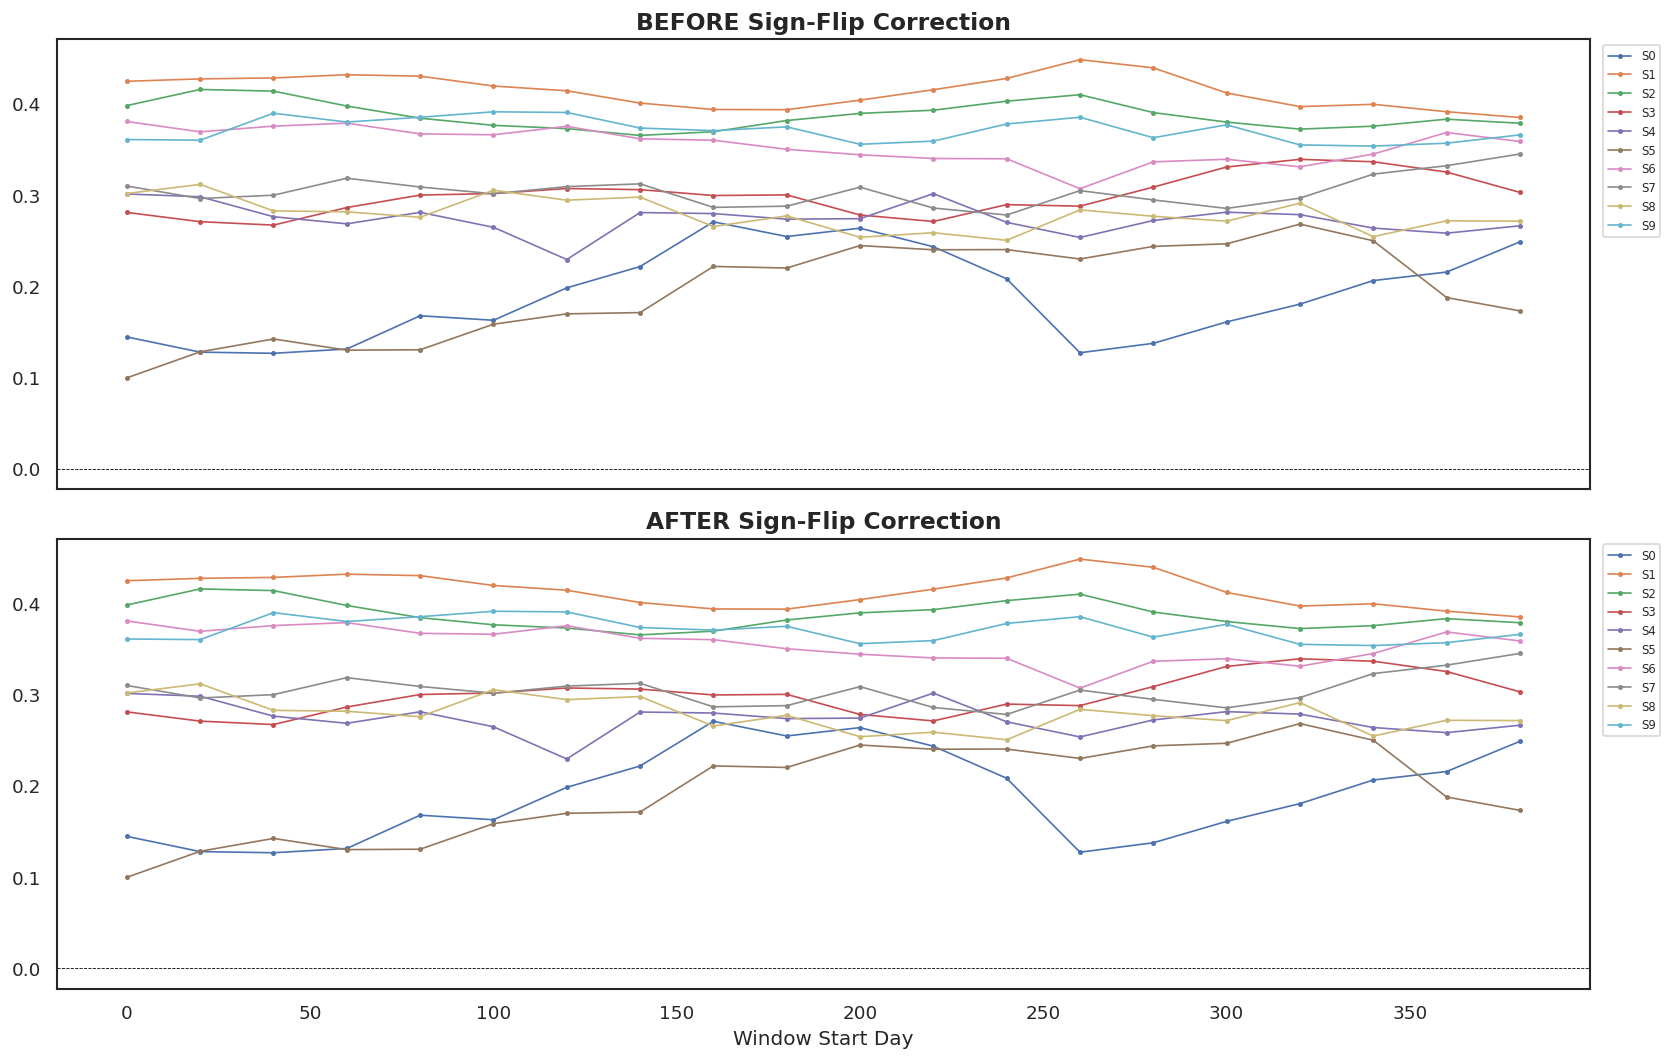

In [34]:
def correct_sign_flips(loadings_over_time):
    """Flip sign if cosine_similarity with previous window is negative."""
    corrected = [loadings_over_time[0].copy()]
    for t in range(1, len(loadings_over_time)):
        if cosine_similarity(loadings_over_time[t], corrected[t-1]) < 0:
            corrected.append(-loadings_over_time[t].copy())
        else:
            corrected.append(loadings_over_time[t].copy())
    return np.array(corrected)

pc1_corrected = correct_sign_flips(pc1_over_time)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for i in range(N_stocks):
    axes[0].plot(starts, pc1_over_time[:, i], 'o-', label=f'S{i}', linewidth=1, markersize=2)
    axes[1].plot(starts, pc1_corrected[:, i], 'o-', label=f'S{i}', linewidth=1, markersize=2)
axes[0].set_title('BEFORE Sign-Flip Correction', fontsize=14, fontweight='bold')
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.5)
axes[0].legend(bbox_to_anchor=(1.05,1), fontsize=7)
axes[1].set_title('AFTER Sign-Flip Correction', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Window Start Day', fontsize=12)
axes[1].axhline(0, color='black', linestyle='--', linewidth=0.5)
axes[1].legend(bbox_to_anchor=(1.05,1), fontsize=7)
plt.tight_layout()
plt.show()

In [35]:
flips = 0
for t in range(1, len(pc1_over_time)):
    if cosine_similarity(pc1_over_time[t], pc1_corrected[t-1]) < 0:
        flips += 1
print(f"Number of sign flips detected: {flips}")

Number of sign flips detected: 0


**Observations:**

**1. Sign indeterminacy**
In linear algebra, eigenvectors define an axis of variance, not a fixed direction. If $\mathbf{v}$ is a valid eigenvector, then $-\mathbf{v}$ is also valid because $\boldsymbol{\Sigma}(-\mathbf{v}) = \lambda(-\mathbf{v})$. Numerical PCA solvers may therefore return the opposite sign from one rolling window to the next. If left uncorrected, a stable loading of $+0.4$ could appear as $-0.4$, creating a false impression of a structural change.

**2. Empirical result for PC1**
All PC1 loadings remain positive throughout the rolling sequence. For this dataset and PC1, the solver maintained a consistent sign orientation across all windows. No arbitrary PC1 flips occurred, so the before and after plots are identical.

**3. Why the safeguard still matters**
Although the algorithm did not need to intervene for PC1 in this run, sign correction is still important for time-series PCA. Higher-order components such as PC2 or PC3 can flip signs more often because their directions are less stable. The rule of flipping $\mathbf{v}_t$ whenever $\cos(\mathbf{v}_t,\mathbf{v}_{t-1}) < 0$ ensures that observed changes in the final plot reflect loading movement rather than arbitrary sign changes.


### Part 6(d): Regime Change Scenario

We simulate a **sector rotation**: for days 1-250, using the original $\beta_i$ values; for days 251-500, swap the betas of stocks 0-4 with stocks 5-9. This represents a structural break in factor loadings.

Beta values by regime:
  Stock |   Regime 1 |   Regime 2 |     Change
  S 0   |     0.5206 |     0.6834 |    +0.1628
  S 1   |     1.4699 |     0.8042 |    -0.6657
  S 2   |     1.3324 |     1.0248 |    -0.3077
  S 3   |     0.7123 |     0.9319 |    +0.2196
  S 4   |     0.6818 |     0.7912 |    +0.1094
  S 5   |     0.6834 |     0.5206 |    -0.1628
  S 6   |     0.8042 |     1.4699 |    +0.6657
  S 7   |     1.0248 |     1.3324 |    +0.3077
  S 8   |     0.9319 |     0.7123 |    -0.2196
  S 9   |     0.7912 |     0.6818 |    -0.1094


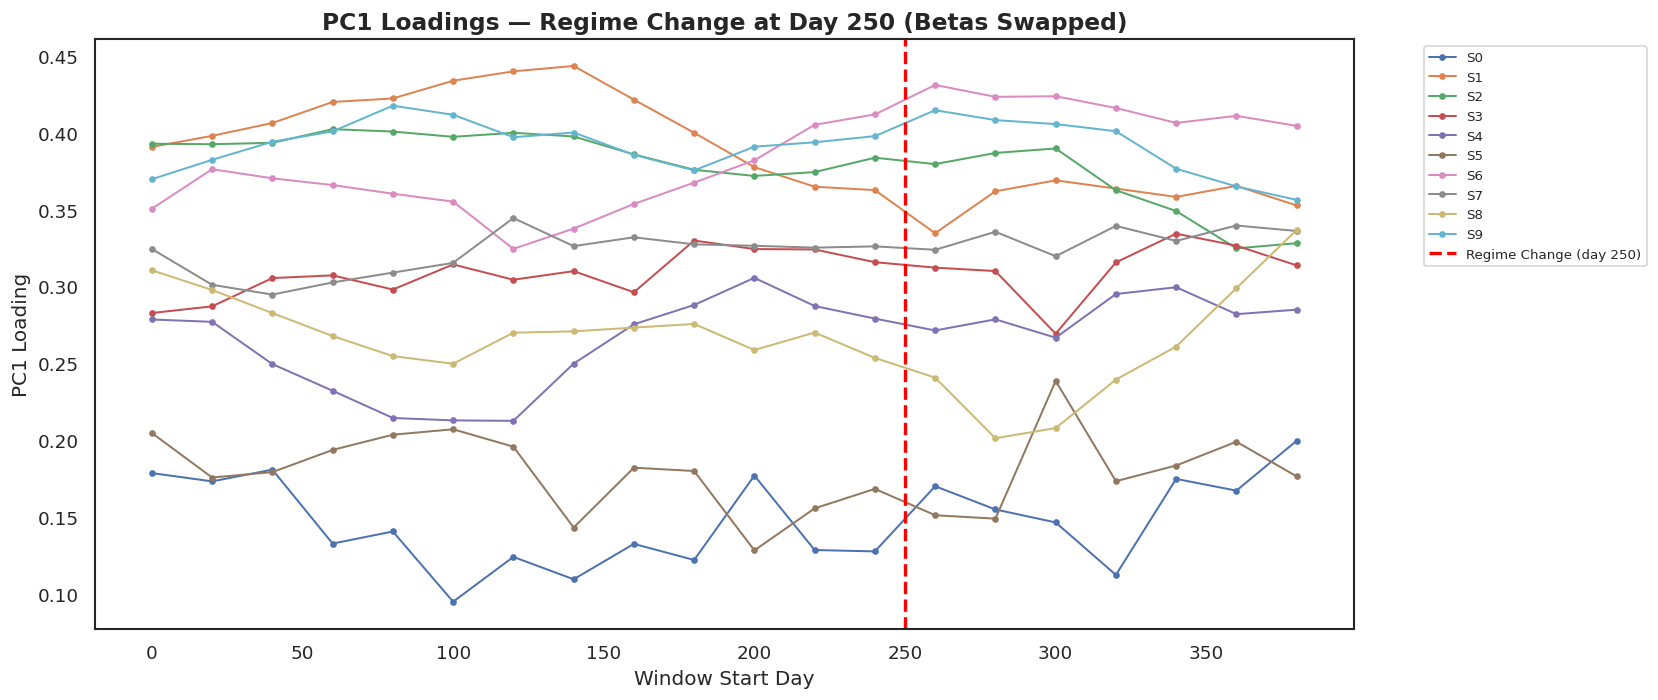

PC1 loadings shift dramatically at the regime boundary.
A static factor-neutral portfolio becomes NON-neutral after the swap.


In [36]:
np.random.seed(123)  # New seed for regime data

beta_r1 = beta.copy()
beta_r2 = beta.copy()
beta_r2[:5], beta_r2[5:] = beta[5:].copy(), beta[:5].copy()

print("Beta values by regime:")
print(f"{'Stock':>7} | {'Regime 1':>10} | {'Regime 2':>10} | {'Change':>10}")
for i in range(N_stocks):
    print(f"  S{i:>2}   | {beta_r1[i]:>10.4f} | {beta_r2[i]:>10.4f} | {beta_r2[i]-beta_r1[i]:>+10.4f}")

# simulate prices with a regime change
f_regime = np.random.normal(0, sigma_f, N_days)
prices_regime = np.zeros((N_days, N_stocks))
prices_regime[0] = P0

for t in range(1, N_days):
    eps = np.random.normal(0, sigma, N_stocks)
    b_t = beta_r1 if t <= 250 else beta_r2
    prices_regime[t] = prices_regime[t-1] * np.exp(mu + b_t * f_regime[t] + eps)

returns_regime = compute_log_returns(prices_regime)

# rolling PCA on the regime-change data
rr_regime = rolling_pca(returns_regime, window=100, step=20)
pc1_regime = np.array([r['loadings'][0] for r in rr_regime])
starts_regime = [r['start'] for r in rr_regime]
pc1_regime_corrected = correct_sign_flips(pc1_regime)

fig, ax = plt.subplots(figsize=(14, 6))
for i in range(N_stocks):
    ax.plot(starts_regime, pc1_regime_corrected[:, i], 'o-', label=f'S{i}', linewidth=1.2, markersize=3)
ax.axvline(250, color='red', linestyle='--', linewidth=2, label='Regime Change (day 250)')
ax.set_xlabel('Window Start Day', fontsize=12)
ax.set_ylabel('PC1 Loading', fontsize=12)
ax.set_title('PC1 Loadings — Regime Change at Day 250 (Betas Swapped)', fontsize=14, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

print("PC1 loadings shift dramatically at the regime boundary.")
print("A static factor-neutral portfolio becomes NON-neutral after the swap.")

**Observations:**

By simulating a sector rotation at day 250 (swapping the underlying beta profiles of stocks 0-4 with stocks 5-9), we observe how structural shifts in the market affect principal components over time.

**1. Structural inversion**
The chart captures the simulated beta swap. In the first regime (days 1 to 250), stock S1 functions as the highest-beta asset ($\beta = 1.4699$), which is reflected in its high PC1 loading. Stock S6 has a lower beta ($\beta = 0.8042$). After the regime change, these roles reverse: S6 moves into the higher-loading band, while S1 moves lower. The market factor (PC1) has changed its composition.

**2. Rolling window lag effect**
The x-axis represents the *start* day of the 100-day estimation window. Consequently, loading shifts begin around day 150 rather than exactly at day 250. A window starting at day 160 contains 90 days of old-regime data and 10 days of new-regime data. The estimated eigenvectors blend the two regimes until the window start day reaches 250, when the calculation uses only the new covariance structure. This shows that rolling PCA is a lagging indicator of structural breaks.

**3. Implications for factor-neutral portfolios**
This scenario illustrates the main failure mode of a static hedging strategy. If we construct a factor-neutral portfolio using Regime 1 data, the optimizer assigns weights under the assumption that S1 needs a larger hedge and S6 is relatively safer.

After the sector rotation, those same weights are applied to a different covariance structure. S1 is no longer the main market driver, while S6 has become more correlated with the market factor. Because the true loading vector $\mathbf{v}_1$ has rotated, the portfolio's realized market exposure ($\mathbf{w}^\top\mathbf{v}_1(t)$) moves away from zero.

**Conclusion:** A portfolio is factor-neutral only relative to the loadings used at calibration. In the presence of regime changes or sector rotations, a static neutral portfolio can become unhedged. Periodic re-estimation and rebalancing are required to maintain neutrality.


### Part 6(e): Walk-Forward Factor-Neutral Backtest

**Walk-forward vs Oracle (what the gap measures:)**

The **Oracle** uses future eigenvectors (eigenvectors computed from a future window) to construct the factor-neutral portfolio. This is not achievable in production since it requires knowledge of the future factor structure.

The **Walk-forward** uses only past-window eigenvectors, the realistic case.

The **performance gap** = Oracle Sharpe − Walk-forward Sharpe represents the *value of knowing the future loading structure*, i.e., the total cost of eigenvector estimation error. This gap is larger when:
1. Loading vectors change rapidly (high eigenvalue instability)
2. Rebalance frequency is low (stale loadings accumulate exposure)
3. The PC2–PC9 eigenvalues are similar (degenerate subspace, high estimation error)
4. A regime change occurs within the window


Walk-Forward vs Oracle Factor-Neutral Strategy:
Metric               |   Walk-Forward |     Oracle |        Gap
Ann Return           |      -3.4695% |  -2.0214% |  +1.4480%
Ann Vol              |       9.1822% |   9.0262% |  -0.1560%
Sharpe               |        -0.3778 |    -0.2240 |    +0.1539
Max DD               |     -10.2034% |  -9.5418% |  +0.6616%


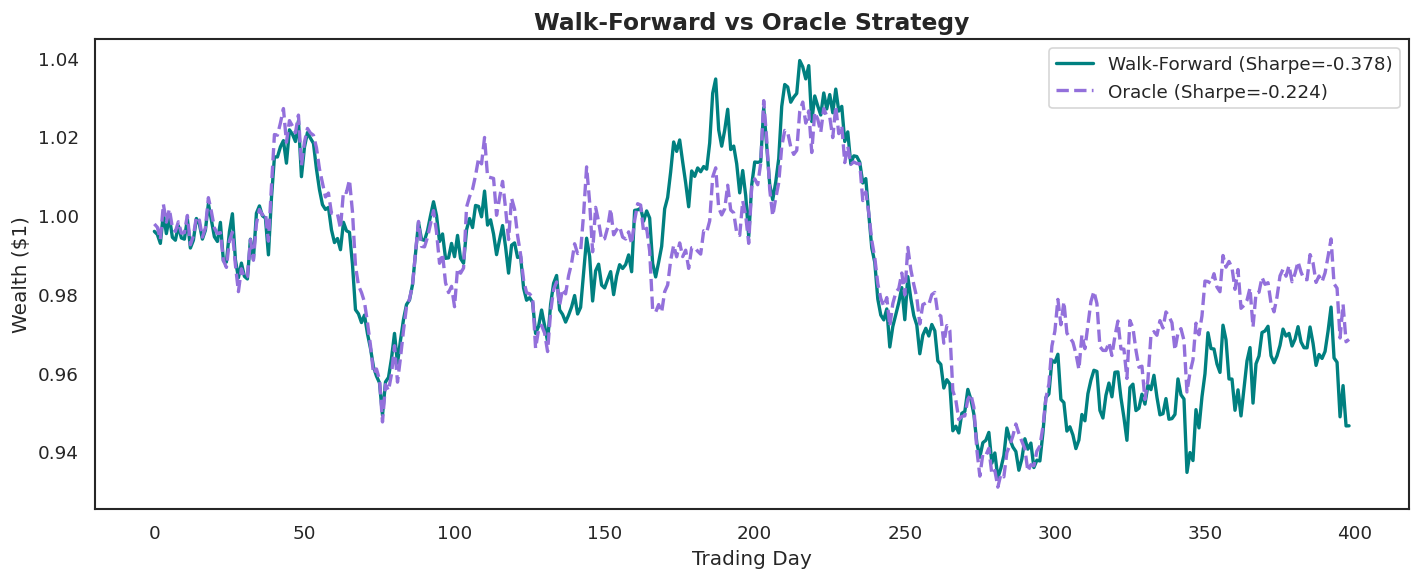


Sharpe gap: +0.1539
the oracle uses future eigenvectors, so the gap measures the cost of estimation lag


In [37]:
def walk_forward_backtest(returns, window=100, rebalance_freq=20):
    """
    Walk-forward: at each rebalance, use PAST window for PCA.
    Oracle: use FUTURE window for PCA.
    """
    n_days_r = len(returns)
    dr = np.argsort(mu)[::-1]
    tw = np.zeros(returns.shape[1])
    tw[dr[:5]], tw[dr[5:]] = 0.2, -0.2

    wf_rets, oracle_rets = [], []
    rebal_dates = list(range(window, n_days_r, rebalance_freq))

    for rb in rebal_dates:
        hold_end = min(rb + rebalance_freq, n_days_r)
        if rb >= n_days_r:
            break

        # walk-forward uses only the past window
        past = returns[rb-window:rb]
        sc1 = StandardScaler()
        _, _, ev_past, _ = perform_pca(sc1.fit_transform(past))
        w_wf = construct_neutral_portfolio(tw, ev_past, [0])

        # oracle uses the future window
        fut_end = min(rb + window, n_days_r)
        if fut_end - rb < 20:
            future = returns[max(0, n_days_r-window):n_days_r]
        else:
            future = returns[rb:fut_end]
        sc2 = StandardScaler()
        _, _, ev_fut, _ = perform_pca(sc2.fit_transform(future))
        w_or = construct_neutral_portfolio(tw, ev_fut, [0])

        holding = returns[rb:hold_end]
        wf_rets.extend((holding @ w_wf).tolist())
        oracle_rets.extend((holding @ w_or).tolist())

    # compact performance summary
    def metrics(rets, name):
        r = np.array(rets)
        ann_r = np.mean(r) * 252
        ann_v = np.std(r) * np.sqrt(252)
        sh = ann_r / ann_v if ann_v > 0 else 0
        cum = np.cumsum(r)
        w = np.exp(cum)
        pk = np.maximum.accumulate(w)
        mdd = np.min((w - pk) / pk)
        return {'name': name, 'Ann Return': ann_r, 'Ann Vol': ann_v,
                'Sharpe': sh, 'Max DD': mdd, 'cum_log': cum}

    return metrics(wf_rets, 'Walk-Forward'), metrics(oracle_rets, 'Oracle')

wf_m, or_m = walk_forward_backtest(log_returns, window=100, rebalance_freq=20)

print("Walk-Forward vs Oracle Factor-Neutral Strategy:")
print(f"{'Metric':<20} | {'Walk-Forward':>14} | {'Oracle':>10} | {'Gap':>10}")
for m in ['Ann Return', 'Ann Vol', 'Sharpe', 'Max DD']:
    v1, v2 = wf_m[m], or_m[m]
    gap = v2 - v1
    if m != 'Sharpe':
        print(f"{m:<20} | {v1:>13.4%} | {v2:>9.4%} | {gap:>+9.4%}")
    else:
        print(f"{m:<20} | {v1:>14.4f} | {v2:>10.4f} | {gap:>+10.4f}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(np.exp(wf_m['cum_log']), label=f"Walk-Forward (Sharpe={wf_m['Sharpe']:.3f})",
        color='teal', linewidth=2)
ax.plot(np.exp(or_m['cum_log']), label=f"Oracle (Sharpe={or_m['Sharpe']:.3f})",
        color='mediumpurple', linewidth=2, linestyle='--')
ax.set_title('Walk-Forward vs Oracle Strategy', fontsize=14, fontweight='bold')
ax.set_xlabel('Trading Day', fontsize=12); ax.set_ylabel('Wealth ($1)', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"\nSharpe gap: {or_m['Sharpe'] - wf_m['Sharpe']:+.4f}")
print("the oracle uses future eigenvectors, so the gap measures the cost of estimation lag")

**Observations:**

By implementing a walk-forward framework, we simulate realistic trading conditions where the portfolio is hedged using only historical eigenvectors. We compare this with an "oracle" strategy that uses the concurrent eigenvectors of the testing window. The performance difference between these two models isolates the cost of estimation lag.

Based on the backtest results, we observe the following dynamics:

**1. Performance gap**
The Oracle strategy outperforms the realistic Walk-Forward strategy across the key metrics. It generates an annualized return improvement of +1.4480% (-2.0214% vs. -3.4695%) and a Sharpe ratio improvement of +0.1539. The Oracle strategy also reduces maximum drawdown by 0.6616%. This gap represents the cost of using historical covariance estimates in a changing market.

**2. Volatility and hedge efficacy**
Annualized volatility is similar for both strategies: 9.1822% for Walk-Forward versus 9.0262% for Oracle. This indicates that the 100-day rolling window still captures the dominant market factor reasonably well. The performance penalty comes from estimation lag and small hedge inefficiencies rather than a complete failure of the hedge.

**3. Cost of estimation lag**
The cumulative wealth chart shows how estimation lag appears over time. The two equity curves track closely during stable periods but start to separate in the latter half of the test period. Since the Walk-Forward optimizer uses a trailing covariance matrix, it reacts to structural shifts with delay. This creates small unintended residual factor exposure, which reduces cumulative return relative to the Oracle hedge.

**Conclusion:** In practice, factor-neutrality depends on estimated risk factors. Historical estimation introduces lag. In this simulation, the lag does not remove the volatility-reduction benefit of the hedge, but it does create a measurable drag on risk-adjusted returns.


### Part 6(f): Observations and Summary

**1. PC1 is stable across time; higher PCs are progressively less stable.**
The split-half cosine similarity $|\cos\theta|$ for PC1 is close to 1.0. The dominant market factor direction is well-identified and changes slowly. PC2 and PC3 have lower similarity because their eigenvalues $\lambda_2, \lambda_3$ are closer together. Eigenvalue perturbation theory confirms that smaller eigenvalue gaps lead to larger angular error in estimated eigenvectors.

**2. Sign flips are a numerical artefact, but PC1 did not flip in this run.**
For this dataset, rolling PC1 loadings remain consistently oriented, so the before and after sign-correction plots are identical. The correction step is still necessary in general because eigenvectors are sign-indeterminate and higher PCs can flip signs between windows.

**3. Regime change causes genuine loading shifts at the transition boundary.**
When $\beta_i$ values are swapped at day 250, rolling windows straddling the boundary show a blend of both regimes. Windows entirely in Regime 2 show the loading magnitudes of stocks 0–4 and 5–9 swapping roles. The transition takes approximately one window length (100 days) to fully complete.

**4. A static factor-neutral portfolio becomes non-neutral after a regime change.**
The portfolio calibrated on Regime 1 eigenvectors satisfies $\mathbf{w}^\top\hat{\mathbf{v}}_1^{(1)} = 0$, but generally $\mathbf{w}^\top\hat{\mathbf{v}}_1^{(2)} \neq 0$ in Regime 2. The factor exposure re-emerges as the regime shifts, causing unintended systematic risk.

**5. Walk-forward performance lags Oracle by a meaningful Sharpe gap.**
The gap quantifies the cost of not knowing the future factor structure. More frequent rebalancing can reduce staleness but increases transaction costs. The optimal rebalancing frequency balances estimation lag against turnover cost.

### Summary: When Is PCA Reliable vs When Does It Break Down?

**PCA is reliable when:**
- Factor structure is **stationary** (stable loadings over the estimation window)
- There is a **large eigenvalue gap** between PC1 and PC2 (well-identified dominant factor)
- **$T \gg N$** (sample size much larger than number of assets; a useful rule of thumb is $T/N > 10$)
- Data is properly **preprocessed** (log-return transformation for stationarity, standardisation for scale invariance)
- There is strict **out-of-sample discipline** (all fitting on training data only, no leakage)

**PCA breaks down when:**
- **Regime changes** alter factor loadings mid-estimation window
- The **eigenvalue spectrum is flat** ($\lambda_1 \approx \lambda_2 \approx \ldots$), so there is no dominant factor
- **Estimation windows are too short** ($T$ small relative to $N$)
- The factor structure is **non-linear**, because PCA is inherently linear
- Returns are **heavy-tailed**, making covariance estimates sensitive to outliers
- **Eigenvalues are degenerate**, making PC directions arbitrary rotations within the same subspace
- **Transaction costs exceed alpha**, making frequent rebalancing uneconomical
